# Cosmology

Acht Wege, das Universum als Ganzes zu vermessen, jeweils mit echten Daten oder eigener Simulation: das Hubble-Diagramm der Supernovae von Pantheon+, die Frage nach einer lokalen Leere, eine eigene N-Körper-Simulation, die Standardsirene GW170817, kosmische Chronometer, die baryonischen akustischen Oszillationen von DESI, die akustischen Peaks der Hintergrundstrahlung aus Planck-Karten und die Nukleosynthese in den ersten Minuten mit einem eigenen Reaktionsnetz. Die Daten kommen aus den öffentlichen Releases von Pantheon+/SH0ES, DESI DR2, Planck 2018, GWOSC (GWTC-1), den Messungen von Moresco et al. und den Raten von PRIMAT und NACRE II; Downloads landen in `data/cosmology/`. Der Code steht in [`code/cosmology/`](https://github.com/deltorobarba/science/tree/main/code/cosmology), ein Modul je Teil (`hubble.py`, `localvoid.py`, `nbody.py`, `sirens.py`, `chronometers.py`, `bao.py`, `cmbpeaks.py`, `bbn.py`, dazu `cosmodata.py` für den Cache); hier stehen nur die Aufrufe und die Bilder. Die Funktionen eines Moduls reichen ihre Zwischenergebnisse weiter und laufen deshalb in der Reihenfolge des Notebooks.

**Der rote Faden**

Alle acht Teile fragen, wie schnell sich das Universum ausdehnt und woraus es besteht, und sie gehen dabei von heute zurück bis zu den ersten Minuten. Im Hintergrund steht die Hubble-Spannung: Die Entfernungsleiter mit Cepheiden gibt H₀ ≈ 73 km/s/Mpc, das frühe Universum im Standardmodell ≈ 67.

- **Schritte 1 bis 13, Hubble-Diagramm:** Supernovae als Kerzen geben H₀ = 73.4, Ω_m und die beschleunigte Expansion; die volle Kovarianz zählt.
- **Schritte 14 bis 24, lokale Leere:** Lebten wir in einer großen Leere, wäre H₀ lokal größer. Die Supernovae und ΛCDM schließen das aus.
- **Schritte 25 bis 35, N-Körper-Simulation:** Das kosmische Netz entsteht aus winzigen Schwankungen; eine Leere wie die KBC-Leere ist darin 7σ selten.
- **Schritte 36 bis 45, Standardsirenen:** GW170817 misst H₀ ohne jede Eichung; mit dem Jet als Winkelmesser auf 7 %.
- **Schritte 46 bis 56, Chronometer:** Das Alter alter Galaxien misst H(z) direkt und eicht Lineal und Kerzen.
- **Schritte 57 bis 70, BAO:** Ein Lineal aus Schallwellen gibt Ω_m, H₀ ≈ 68.5 und Hinweise auf eine Dunkle Energie, die sich ändert.
- **Schritte 71 bis 85, CMB-Peaks:** Die Schallwellen in der Hintergrundstrahlung geben den Winkel des Schallhorizonts und daraus H₀ ≈ 68.
- **Schritte 86 bis 98, Nukleosynthese:** Deuterium und Helium aus den ersten Minuten geben die Baryonendichte und drei Neutrinoarten.

Die gemeinsame Lehre: Jede Messung braucht eine Eichung, eine Kerze, ein Lineal oder eine Uhr. Alle Wege ohne Cepheiden landen hier zwischen 64 und 70, die Leiter mit Cepheiden bei 73; die Form der Expansion passt überall zusammen, die Eichungen nicht.

In [1]:
import sys
import urllib.request
import importlib.util
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "cosmology"
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir(parents=True)
    for f in ["cosmodata.py", "hubble.py", "localvoid.py", "nbody.py", "sirens.py", "chronometers.py", "bao.py", "cmbpeaks.py", "bbn.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/cosmology/{f}", CODE / f)
if "google.colab" not in sys.modules and (importlib.util.find_spec("numba") is None or importlib.util.find_spec("h5py") is None):
    raise ImportError("Es fehlt eines der Pakete numba, h5py; lokal selbst installieren (conda-forge)")
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import hubble, localvoid, nbody, sirens, chronometers, bao, cmbpeaks, bbn

**1. Das Hubble-Diagramm: Pantheon+**

1929 fand Edwin Hubble, dass sich Galaxien umso schneller entfernen, je weiter sie weg sind; die Steigung, die Hubble-Konstante H₀, misst, wie schnell sich das Universum heute ausdehnt. Supernovae vom Typ Ia, Explosionen Weißer Zwerge mit fast gleicher Leuchtkraft, machen daraus seit 1998 ein Präzisionswerkzeug, mit dem auch die beschleunigte Expansion entdeckt wurde. Geladen wird Pantheon+: 1701 Lichtkurven von 1543 Supernovae bis z = 2.26, mit der vollen Kovarianzmatrix und den Entfernungen der Kalibratoren aus Cepheiden (SH0ES).

Die Ausgabe zählt die Lichtkurven, die Kalibratoren mit Cepheiden-Entfernung und die Größe der Kovarianzmatrix (1701 × 1701), die gemeinsame Fehler aller Lichtkurven enthält.

In [2]:
hubble.load()

1701 Lichtkurven von 1543 Supernovae aus 20 Durchmusterungen; z von 0.0012 bis 2.26
Kalibratoren: 77 Lichtkurven von 43 Supernovae; Hubble-Fluss (SH0ES): 277 Lichtkurven, z = 0.0234 bis 0.1490


Kovarianz: (1701, 1701), größte Asymmetrie vor dem Symmetrisieren 3e-08 mag², kleinster Eigenwert 8.03e-04
Test: μ(z = 0.1, H₀ = 70, Ω_m = 0.3) = 38.315 | leeres Universum: 38.265


**2. Der Katalog**

Die Rotverschiebungen, getrennt nach Kalibratoren, dem Hubble-Fluss von SH0ES und dem Rest, und die Lage am Himmel.

77 Lichtkurven gehören zu Kalibratoren (z bis 0.017), 277 zum Hubble-Fluss (z = 0.023 bis 0.15). Das größte Maximum liegt bei z ≈ 0.3: Tiefe Durchmusterungen finden auf kleiner Fläche viele ferne Supernovae, nahe muss man über den ganzen Himmel suchen. 98 Supernovae haben zwei Lichtkurven, 29 drei oder mehr, weil mehrere Durchmusterungen dieselbe Explosion sahen.

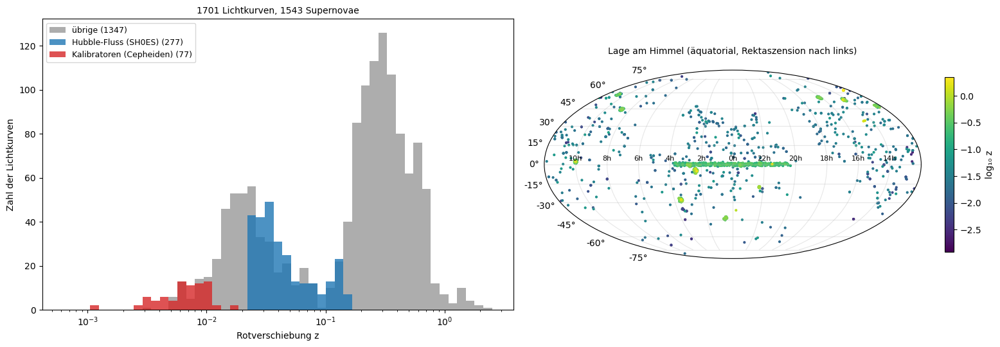

Lichtkurven pro Supernova: 1 bei 1416, 2 bei 98, 3 oder mehr bei 29
Median z: alle 0.164, z < 0.1: 44%, z > 1: 25 Lichtkurven
Kalibratoren: 1981B, 1990N, 1994ae, 1995al, 1997bp, 1997bq, 1998aq, 1998dh, 1999cp, 1999dq, 2001bg, 2001el ...


In [3]:
hubble.catalog()

**3. Das Hubble-Diagramm**

Die standardisierte Helligkeit gegen die Rotverschiebung, mit dem Hubble-Gesetz für zwei Werte von H₀; daneben die Abweichung von einem leeren Universum.

Die Punkte liegen auf einer Geraden: zehnmal weiter heißt 5 mag schwächer. Die Linien für H₀ = 67.4 und 73 liegen nur 0.17 mag auseinander, so klein ist der Unterschied, um den gestritten wird. Bei z = 0.4 bis 0.8 sind die Supernovae schwächer als in einem leeren Universum, also weiter weg: Die Expansion beschleunigt. Jenseits von z ≈ 1 biegt die Kurve um; damals bremste noch die Materie.

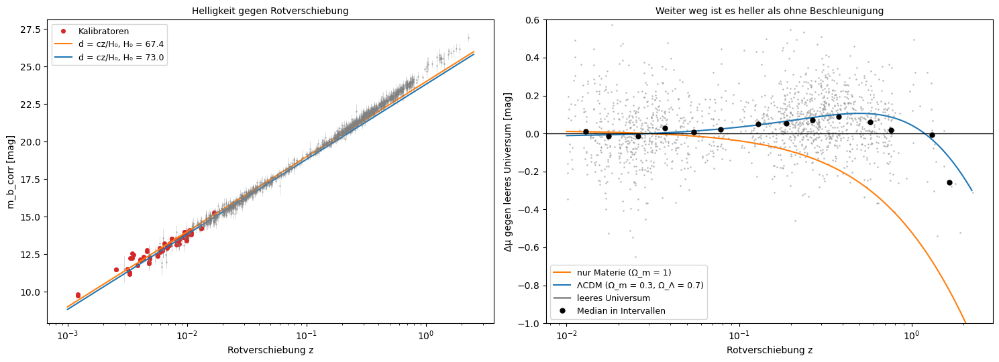

Streuung um eine Gerade im Hubble-Fluss (0.023 < z < 0.15): 0.148 mag; typischer Fehler pro Lichtkurve 0.217 mag
Abweichung vom leeren Universum bei 0.4 < z < 0.8 (Median, auf z ≈ 0.03 normiert): +0.072 mag


In [4]:
hubble.hubble_diagram()

**4. Rotverschiebungen und Eigenbewegungen**

Pantheon+ gibt drei Rotverschiebungen: wie gemessen, ohne die Bewegung der Sonne gegen die Hintergrundstrahlung, und zusätzlich ohne die Eigenbewegung der Wirtsgalaxie.

Die Bewegung der Sonne verschiebt je nach Richtung um bis zu ±370 km/s. Eigenbewegungen von 300 km/s sind bei cz = 3500 km/s 8.6 %, im Entfernungsmodul 0.18 mag, mehr als die Streuung einer Supernova. Deshalb beginnt der Hubble-Fluss erst bei z = 0.023.

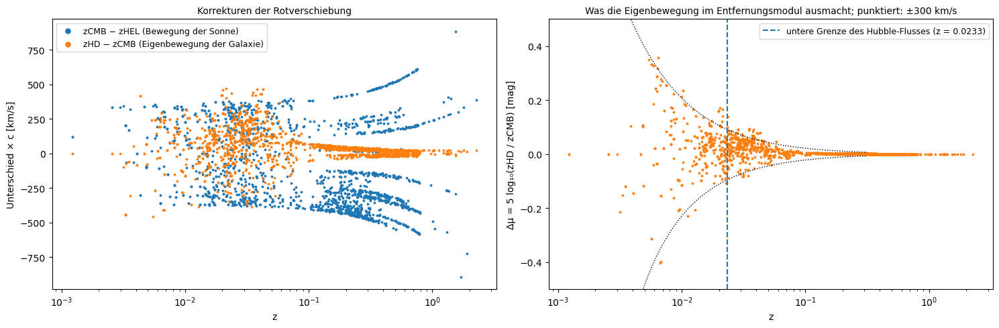

z 0.0000 bis 0.01  :  111 Lichtkurven, |zHD − zCMB|·c Median   135 km/s, |Δμ| Median 0.123 mag
z 0.0100 bis 0.0233:  225 Lichtkurven, |zHD − zCMB|·c Median   114 km/s, |Δμ| Median 0.048 mag
z 0.0233 bis 0.15  :  490 Lichtkurven, |zHD − zCMB|·c Median    90 km/s, |Δμ| Median 0.017 mag
z 0.1500 bis 3     :  875 Lichtkurven, |zHD − zCMB|·c Median    27 km/s, |Δμ| Median 0.001 mag
VPECERR: Median 250 km/s


In [5]:
hubble.redshifts()

**5. Die Kovarianzmatrix**

Die Kovarianzmatrix enthält die Fehler jeder Lichtkurve (Diagonale) und die gemeinsamen Fehler (Nebendiagonale), etwa die Eichung der Filter einer Durchmusterung.

Nur 2 % der Paare sind stärker als 0.1 korreliert, zwei Lichtkurven derselben Supernova aber im Median zu 0.41. Die größten Eigenwerte liegen weit über den größten Diagonalelementen. Der Mittelwert aller Lichtkurven ist mit der Diagonale allein auf 0.0044 mag genau, mit voller Kovarianz auf 0.0049: Ein gemeinsamer Fehler mittelt sich nicht heraus.

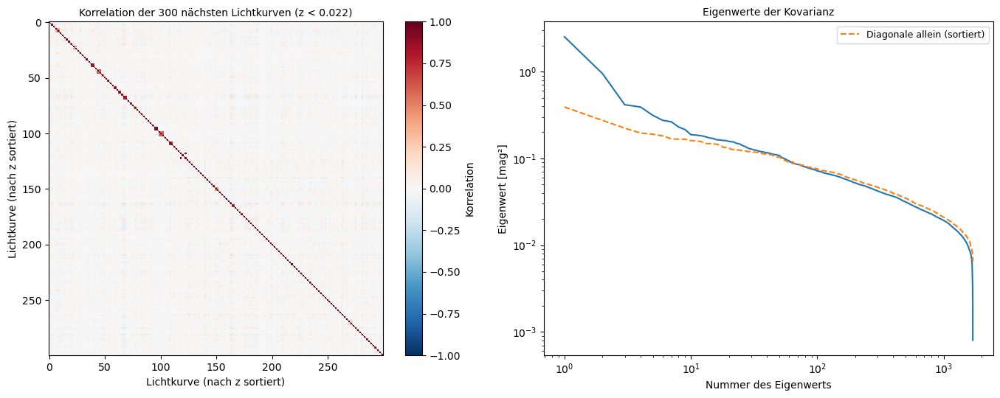

Diagonale: Fehler pro Lichtkurve Median 0.156 mag; Nebendiagonale: Median der Korrelation -0.000, Anteil > 0.1: 2.0%
Zwei Lichtkurven derselben Supernova (191 Paare): Korrelation Median 0.41
Größter Eigenwert 2.5237 mag² (σ = 1.589), die 10 größten zusammen 10.5% der Spur
Fehler des Mittelwerts aller 1701 Lichtkurven: nur Diagonale 0.0044 mag, volle Kovarianz 0.0049 mag


In [6]:
hubble.covariance()

**6. Die Kalibratoren: wie hell ist eine Supernova?**

In Galaxien mit Cepheiden ist die Entfernung bekannt, also folgt die absolute Helligkeit M_B jeder Supernova; gemittelt wird mit der vollen Kovarianz.

M_B = −19.249 ± 0.030, im Band von Riess et al. (2022). Die Farben und Breiten der Lichtkurven unterscheiden sich kaum zwischen Kalibratoren und Hubble-Fluss, die Wirtsgalaxien der Kalibratoren sind aber massereicher; deshalb ist die Korrektur nach der Masse der Wirtsgalaxie für H₀ wichtig.

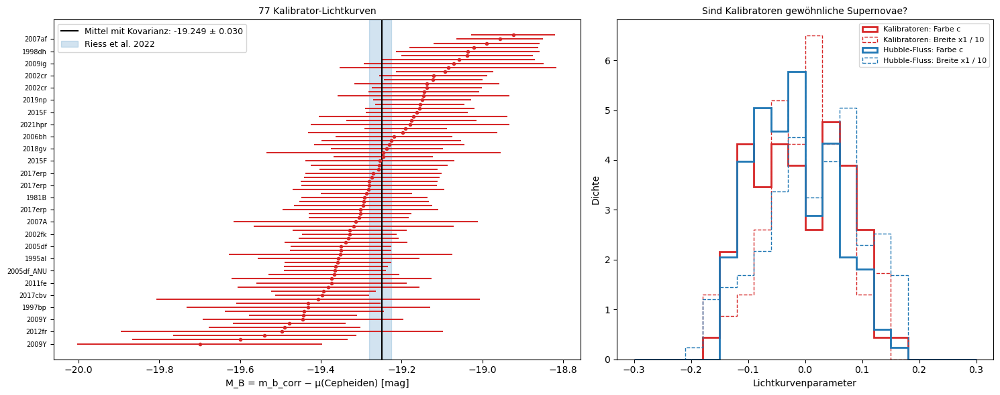

M_B = -19.2489 ± 0.0301 (volle Kovarianz), diagonal gewichtet -19.2447; Riess et al. 2022: -19.253 ± 0.027
χ² = 57.1 bei 76 Freiheitsgraden; Streuung der Einzelwerte 0.146 mag
c            : Kalibratoren Median -0.026, Hubble-Fluss -0.026; KS-Test p = 0.39
x1           : Kalibratoren Median +0.062, Hubble-Fluss +0.196; KS-Test p = 0.06
HOST_LOGMASS : Kalibratoren Median +10.353, Hubble-Fluss +9.989; KS-Test p = 0.00


In [7]:
hubble.calibrators()

**7. Der Hubble-Fluss**

Im Hubble-Fluss gibt jede Supernova mit ihrer Rotverschiebung einen Achsenabschnitt a_B, der nicht von H₀ abhängt. Erst mit M_B aus den Cepheiden folgt H₀.

a_B ist auf 0.4 % genau und zeigt keinen Gang mit z. Damit wird H₀ = 73.49 ± 1.06 km/s/Mpc. Für H₀ = 67.4 müssten Supernovae 0.19 mag heller sein, 6σ neben dem Wert der Cepheiden. Der Fehler von H₀ hängt also fast ganz an M_B.

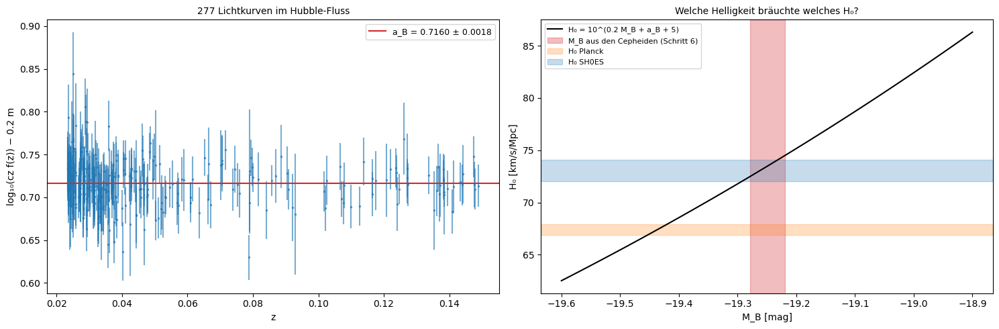

a_B = 0.71599 ± 0.00181 (χ² = 230.7 bei 276 Freiheitsgraden)
H₀ = 10^(0.2 · -19.249 + 0.7160 + 5) = 73.49 ± 1.06 km/s/Mpc
Für H₀ = 67.4 müsste M_B = -19.437 sein, -0.188 mag (-6.2 σ) neben dem Wert der Cepheiden


In [8]:
hubble.hubble_flow()

**8. H₀ im gemeinsamen Fit**

M_B und H₀ werden gleichzeitig an alle 354 Lichtkurven aus Kalibratoren und Hubble-Fluss angepasst, mit voller Kovarianz, wie bei Brout et al. (2022).

H₀ = 73.43 ± 1.05 km/s/Mpc, wie über den Achsenabschnitt und wie bei Brout et al. (73.5 ± 1.1). Die Fehlerellipse ist lang und schmal (Korrelation +0.96), weil H₀ nur zusammen mit M_B bestimmt ist; das Band von Planck liegt weit außerhalb.

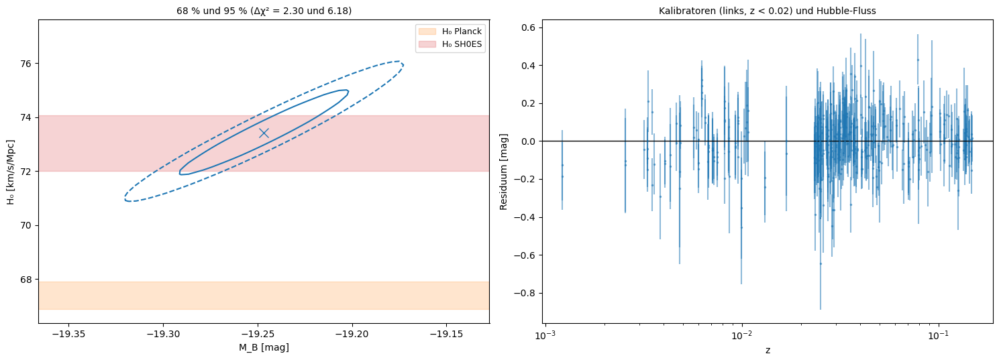

M_B = -19.2467 ± 0.0299, H₀ = 73.43 ± 1.05 km/s/Mpc, Korrelation +0.96; χ² = 299.8 bei 352 Freiheitsgraden
Schritt 7 (Achsenabschnitt): 73.49 ± 1.06; δH₀/H₀ = 0.46 · δM_B: 0.03 mag in M_B sind 1.4% in H₀


In [9]:
hubble.h0_joint()

**9. Ω_m aus dem ganzen Diagramm**

An alle Supernovae über z = 0.01 wird ein flaches ΛCDM angepasst. H₀ und M_B verschieben alle Helligkeiten gleich und fallen heraus; übrig bleibt der Materieanteil Ω_m.

Ω_m = 0.333 ± 0.018, verträglich mit Planck (0.315). Ein Universum nur aus Materie ist um Δχ² = 693 schlechter. Der Rest, Ω_Λ = 0.67, ist die kosmologische Konstante, und der Abbremsparameter q₀ = −0.50 sagt: Die Expansion beschleunigt.

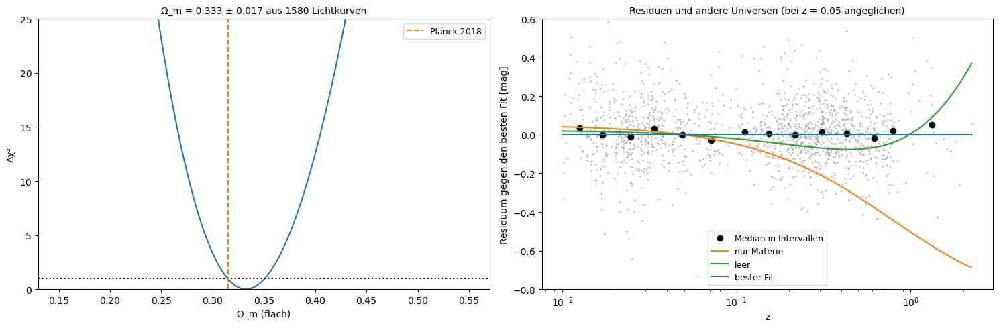

Ω_m = 0.3326 ± 0.0175 (Δχ² = 1), χ²_min = 1386.4 bei 1578 Freiheitsgraden; Ω_Λ = 0.667, q₀ = -0.501
Δχ² für Ω_m = 1 (nur Materie): 693


In [10]:
hubble.omega_m()

**10. Beschleunigt die Expansion?**

Dieselbe Rechnung ohne die Annahme eines flachen Universums, in der Ebene Ω_m gegen Ω_Λ. Mit diesem Bild haben Riess et al. (1998) und Perlmutter et al. (1999) die Beschleunigung entdeckt.

Die erlaubten Flächen liegen ganz über der Linie, die Beschleunigung von Bremsung trennt; ohne kosmologische Konstante ist Δχ² mindestens 49, etwa 7σ. Der beste Wert (Ω_m = 0.30, Ω_Λ = 0.62) ist fast flach. In der schraffierten Ecke gäbe es keinen Urknall.

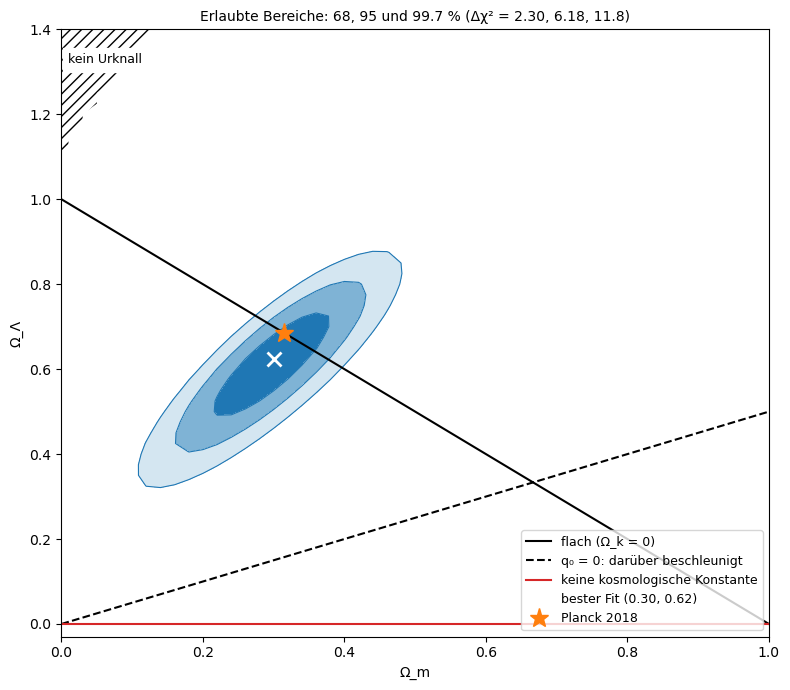

Bester Fit mit Krümmung: Ω_m = 0.30, Ω_Λ = 0.62, Ω_k = +0.07
Kleinstes Δχ² ohne kosmologische Konstante (Ω_Λ = 0): 49, entspricht 7 σ bei einem Parameter
Kleinstes Δχ² im gebremsten Bereich (q₀ > 0): 49; ausgeschlossene Gitterpunkte (kein Urknall): 45


In [11]:
hubble.acceleration()

**11. Diagonale gegen volle Kovarianz**

Die Fits mit voller Kovarianz, nur mit ihrer Diagonale, und mit der Diagonale und jeder Supernova nur einmal.

Ohne Korrelationen schrumpft der Fehler von H₀ um 37 %, falsch klein, weil der gemeinsame Fehler der Kalibrierung wegfällt. Ω_m verschiebt sich zusätzlich um fast 1σ auf 0.350, auch mit jeder Supernova einmal: Gemeinsame Fehler, die mit z zusammenhängen, ziehen den Fit, wenn man sie als unabhängig behandelt.

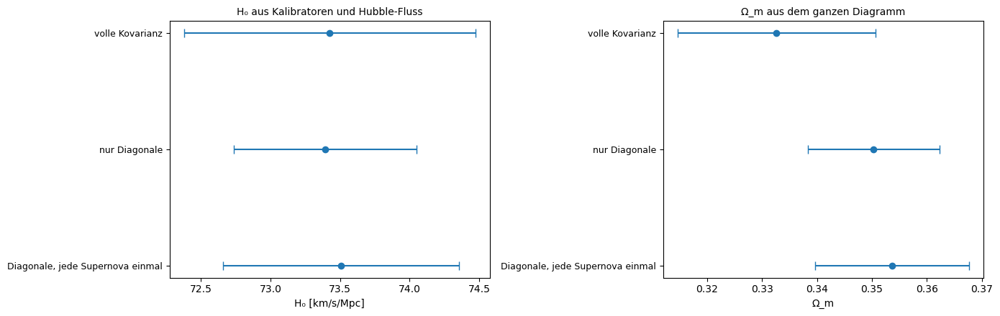

                          Matrix  Lichtkurven_H0      H0  H0_Fehler  Lichtkurven_Om     Om  Om_Fehler
                 volle Kovarianz             354 73.4251     1.0468            1580 0.3326     0.0180
                   nur Diagonale             354 73.3919     0.6567            1580 0.3503     0.0120
Diagonale, jede Supernova einmal             281 73.5079     0.8475            1466 0.3536     0.0140


In [12]:
hubble.diag_vs_full()

**12. H₀ gegen SH0ES und Planck: die Hubble-Spannung**

Das eigene H₀ neben Brout et al., Riess et al. und Planck, der Hintergrundstrahlung, aus der man H₀ im Standardmodell vorhersagt; dazu, wie stark H₀ an den Annahmen hängt.

73.43 ± 1.05 liegt bei SH0ES und 5.2σ über Planck (67.4 ± 0.5). Ω_m, der Beginn des Hubble-Flusses oder die Wahl der Rotverschiebung verschieben H₀ um höchstens 0.4 km/s/Mpc. Mit diesen Daten lässt sich die Spannung nicht wegrechnen; ein Fehler müsste in der Eichung durch die Cepheiden stecken oder in der Annahme ΛCDM bei Planck.

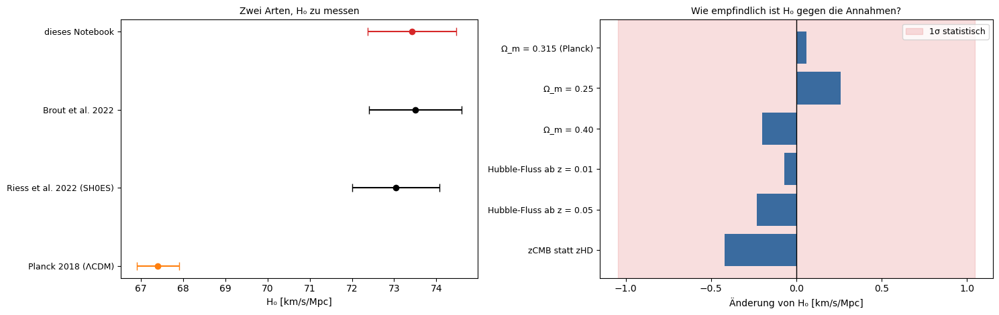

Eigenes H₀ = 73.43 ± 1.05: gegen Brout -0.0 σ, gegen SH0ES +0.3 σ, gegen Planck +5.2 σ
SH0ES gegen Planck: 4.9 σ
  Ω_m = 0.315 (Planck)        : H₀ = 73.48 (+0.06)
  Ω_m = 0.25                  : H₀ = 73.68 (+0.26)
  Ω_m = 0.40                  : H₀ = 73.22 (-0.20)
  Hubble-Fluss ab z = 0.01    : H₀ = 73.35 (-0.07)
  Hubble-Fluss ab z = 0.05    : H₀ = 73.19 (-0.23)
  zCMB statt zHD              : H₀ = 73.00 (-0.42)


In [13]:
hubble.hubble_tension()

**13. Ω_m gegen Pantheon+ und Planck**

Das eigene Ω_m neben Brout et al. und Planck, und wie es von der unteren Grenze in z abhängt.

0.333 ± 0.018 stimmt mit Brout et al. (0.334) und mit Planck (0.315, 0.9σ). Die untere Grenze in z ändert Ω_m kaum. Supernovae und Hintergrundstrahlung messen mit ganz verschiedenen Methoden denselben Materieanteil: ΛCDM passt in Ω_m, aber nicht in H₀.

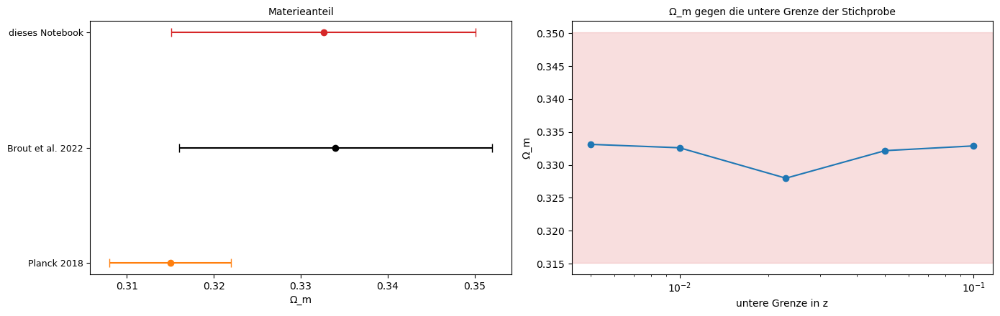

Ω_m = 0.3326 ± 0.0175: gegen Brout -0.06 σ, gegen Planck +0.93 σ
  z > 0.005 : Ω_m = 0.3331 (1619 Lichtkurven)
  z > 0.01  : Ω_m = 0.3326 (1580 Lichtkurven)
  z > 0.023 : Ω_m = 0.3280 (1371 Lichtkurven)
  z > 0.05  : Ω_m = 0.3322 (1056 Lichtkurven)
  z > 0.1   : Ω_m = 0.3329 (960 Lichtkurven)


In [14]:
hubble.vs_pantheon()

**14. Eine lokale Leere?**

Das Universum ist ein Netz aus Filamenten und Haufen mit Leeren dazwischen. 2013 fanden Keenan, Barger und Cowie, dass die Dichte bis etwa 300 Mpc um uns 46 % unter dem Mittel liegt, die KBC-Leere. Materie in einer Unterdichte strömt nach außen; in der Leere würde man deshalb ein größeres H₀ messen als im ganzen Universum. Könnte das die Hubble-Spannung erklären? Geladen werden dieselben Pantheon+-Supernovae mit beiden Rotverschiebungen, mit und ohne Korrektur der Eigenbewegungen.

Die Ausgabe zählt die Lichtkurven und Kalibratoren und meldet die Kovarianzmatrix; die Daten sind dieselben wie beim Hubble-Diagramm.

In [15]:
localvoid.load()

1701 Lichtkurven, 77 Kalibratoren; z > 0.01 ohne Kalibratoren: 1580
KBC-Leere: δ = -0.46 ± 0.06 bis R = 300 Mpc; Wachstumsrate f = 0.547
Test: σ(8 Mpc/h) = 0.811, σ(100 Mpc) = 0.1089, σ(300 Mpc) = 0.0232
Test: δ̄(<r) einer Leere mit δ₀ = −0.46, R = 300 Mpc bei r = 150, 300, 600 Mpc: -0.460, -0.418, -0.059


**15. Supernovae nach Entfernung**

Für jede Supernova die Entfernung, und wie viele innerhalb, am Rand und außerhalb einer Leere von 300 Mpc liegen.

585 Lichtkurven liegen innerhalb von 300 Mpc (z = 0.071), 109 zwischen 300 und 600 Mpc, 886 weiter weg; sie verteilen sich über den ganzen Himmel. Am Rand der Leere gibt es wenige Supernovae, innen und außen aber genug, um einen Sprung von H₀ zu sehen.

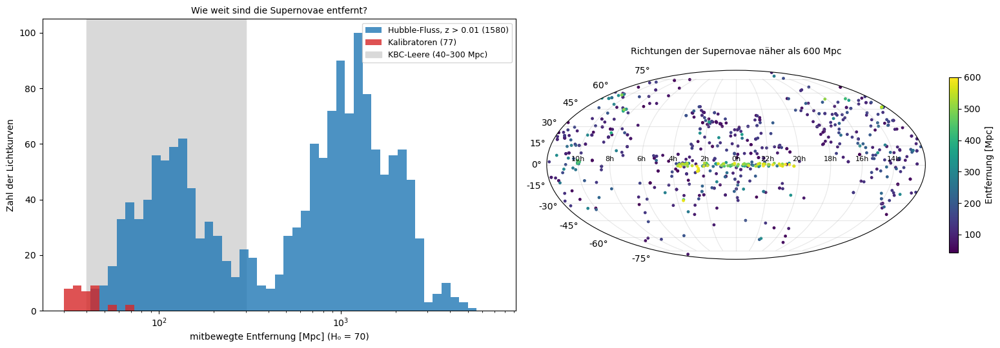

innerhalb (< 300 Mpc) :  585 Lichtkurven
Rand (300–600 Mpc)    :  109 Lichtkurven
außerhalb (> 600 Mpc) :  886 Lichtkurven
300 Mpc entsprechen z = 0.071; Kalibratoren bis 72 Mpc


In [16]:
localvoid.by_distance()

**16. Der Ausgangswert**

M_B und H₀ werden gemeinsam an alle Supernovae über z = 0.01 und die Kalibratoren angepasst, einmal mit und einmal ohne Korrektur der Eigenbewegungen.

H₀ = 73.52 ± 1.01 km/s/Mpc mit Korrektur und 73.24 ± 1.00 ohne; der Unterschied ist kleiner als ein Drittel des Fehlers, der fast ganz von den Cepheiden kommt. Mit Korrektur ist χ² um 38 kleiner: Sie macht das Diagramm glatter, wie sie soll.

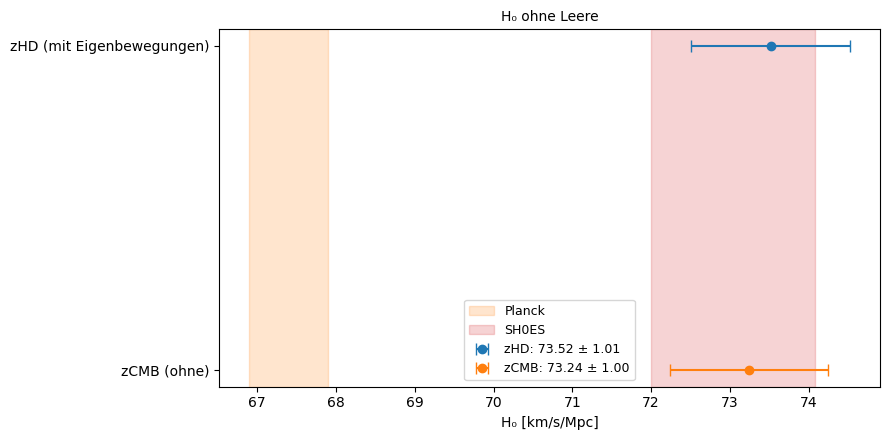

zHD: M_B = -19.2439 ± 0.0295, H₀ = 73.52 ± 1.01, χ² = 1452.0 bei 1655 Freiheitsgraden
zCMB: M_B = -19.2444 ± 0.0295, H₀ = 73.24 ± 1.00, χ² = 1489.7 bei 1653 Freiheitsgraden


In [17]:
localvoid.baseline()

**17. Was die Korrektur der Eigenbewegungen tut**

Enthielte das Modell der Eigenbewegungen eine große Leere, wäre die Korrektur im Mittel negativ und würde nach außen wachsen. Gezeigt wird der Median der Korrektur gegen die Entfernung und daneben, was die KBC-Leere verlangen würde.

Die KBC-Leere verlangte ein Ausströmen von bis zu 1600 km/s am Rand. Die Korrektur liegt bei +40 bis +150 km/s, mit falschem Vorzeichen und zehnmal kleiner: Das Modell enthält keine große Leere und rechnet ein Void-Signal deshalb nicht heraus. Die folgenden Schritte rechnen trotzdem mit beiden Rotverschiebungen.

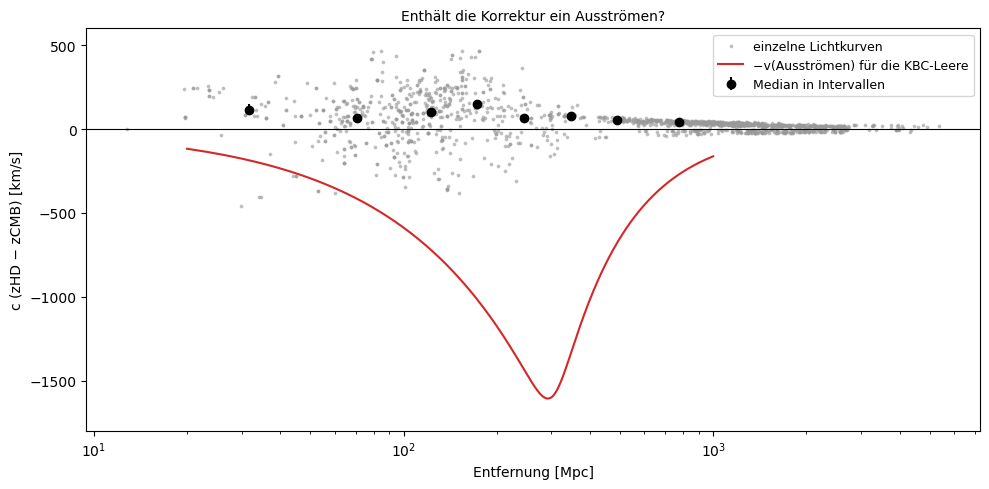

  20 bis   50 Mpc: Median c(zHD − zCMB) =   +114 km/s; KBC verlangt   -186
  50 bis  100 Mpc: Median c(zHD − zCMB) =    +66 km/s; KBC verlangt   -415
 100 bis  150 Mpc: Median c(zHD − zCMB) =   +102 km/s; KBC verlangt   -719
 150 bis  200 Mpc: Median c(zHD − zCMB) =   +147 km/s; KBC verlangt  -1017
 200 bis  300 Mpc: Median c(zHD − zCMB) =    +63 km/s; KBC verlangt  -1432
 300 bis  400 Mpc: Median c(zHD − zCMB) =    +78 km/s; KBC verlangt  -1341
 400 bis  600 Mpc: Median c(zHD − zCMB) =    +51 km/s; KBC verlangt   -677
 600 bis 1000 Mpc: Median c(zHD − zCMB) =    +39 km/s; KBC verlangt   -271


In [18]:
localvoid.peculiar_velocities()

**18. H₀ in Schalen**

Mit M_B aus dem gemeinsamen Fit gibt jede Supernova ihr eigenes H₀; gemittelt wird in Schalen der Rotverschiebung. Eine Leere wie die KBC-Leere ließe H₀ zwischen z = 0.07 und 0.2 um 6 km/s/Mpc fallen.

Die Messungen fallen nicht: innen 73.40 ± 0.26, bei 0.1 < z < 0.4 73.57 ± 0.22. Alle Schalen liegen im Band von SH0ES, keine bei Planck. Der gemeinsame Fehler von M_B würde alle Schalen gleich verschieben und kann einen Abfall weder erzeugen noch verdecken.

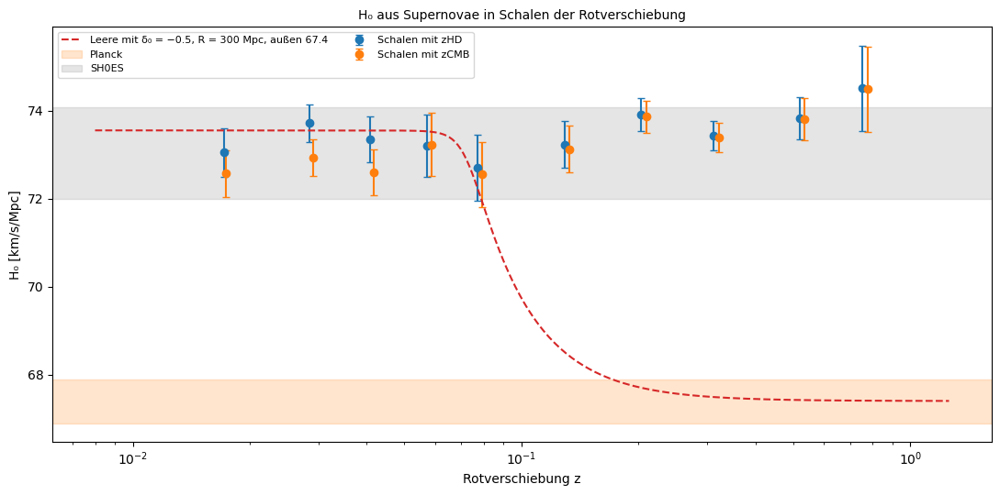

 z_lo  z_hi  z_med   n     H0   err        r
0.010 0.023  0.017 215 73.047 0.551   73.345
0.023 0.035  0.028 208 73.714 0.423  121.141
0.035 0.050  0.041 101 73.346 0.512  172.813
0.050 0.070  0.057  52 73.204 0.708  241.350
0.070 0.100  0.077  44 72.702 0.747  324.019
0.100 0.150  0.129  85 73.223 0.533  535.119
0.150 0.250  0.203 261 73.910 0.368  825.288
0.250 0.400  0.312 306 73.426 0.332 1230.128
0.400 0.700  0.519 233 73.824 0.476 1926.746
0.700 1.200  0.755  56 74.505 0.965 2619.937
zHD: H₀ für z < 0.07 73.40 ± 0.26, für 0.1 < z < 0.4 73.57 ± 0.22; Unterschied -0.17 ± 0.34


In [19]:
localvoid.shells()

**19. Was eine Leere vorhersagt**

Profil und mittlerer Dichtekontrast einer Leere mit weichem Rand, und die scheinbare Hubble-Rate, die sie erzeugt: H_lokal / H = 1 − f δ̄(<r) / 3, mit der Wachstumsrate f ≈ 0.55.

Die KBC-Leere hebt H innen um 8.4 % an, genau das Verhältnis 73.04/67.4; bei 600 Mpc wirkt sie noch mit 1.1 %. Eine flachere Leere gibt nur 3.7 %. Dass die nötige Tiefe fast genau die der KBC-Leere ist, macht die Idee so verlockend.

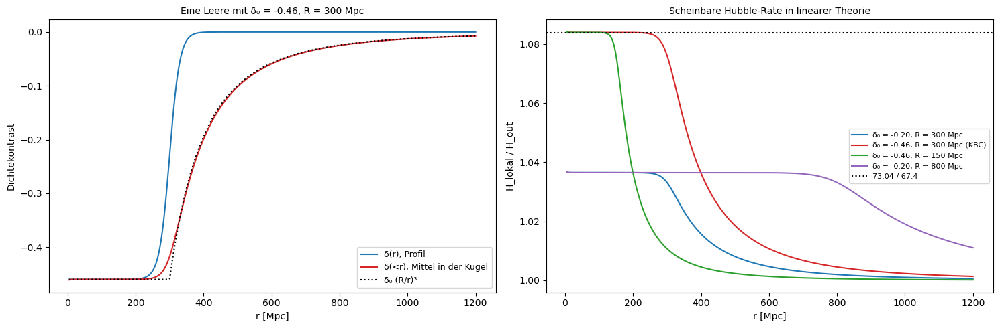

f = 0.547; für H_lokal/H_out = 1.084 braucht man δ̄ = -0.459
δ₀ = -0.46, R = 300: H_lokal/H_out bei 100 Mpc 1.0839, bei 600 Mpc 1.0107
δ₀ = -0.2, R = 300: H_lokal/H_out bei 100 Mpc 1.0365, bei 600 Mpc 1.0047


In [20]:
localvoid.void_prediction()

**20. Fit des Void-Modells**

Für jede Tiefe und jeden Radius einer Leere werden M_B und das äußere H₀ angepasst; die Karte zeigt, wie viel schlechter oder besser das Modell ist als eines ohne Leere.

Die KBC-Leere liegt tief im ausgeschlossenen Bereich (Δχ² = 253). Bei 300 Mpc ist nur eine Tiefe zwischen −0.04 und +0.10 erlaubt, weit weg von −0.46. Nur bei kleinen Radien ist jede Tiefe erlaubt, weil dort kaum Supernovae innen liegen. Die beste Leere verbessert χ² nur um 4.5.

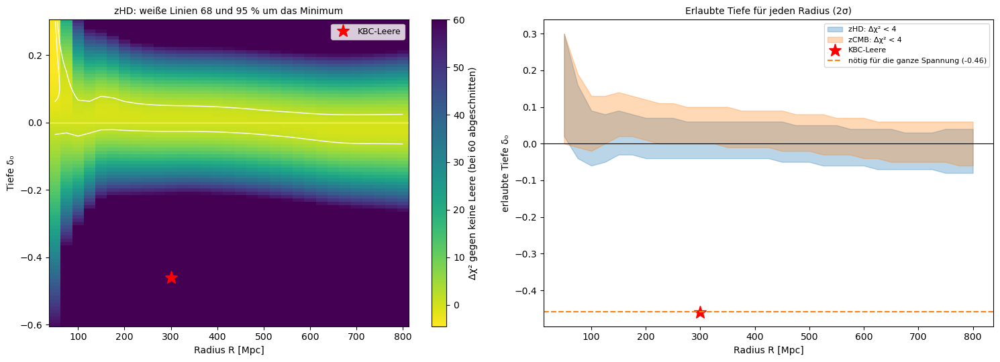

zHD: Minimum bei δ₀ = +0.21, R = 50 Mpc (Δχ² = -4.5); bei R = 300 Mpc erlaubt -0.040 bis +0.060; KBC-Leere Δχ² = 253
zCMB: Minimum bei δ₀ = +0.08, R = 150 Mpc (Δχ² = -5.8); bei R = 300 Mpc erlaubt -0.000 bis +0.100; KBC-Leere Δχ² = 293


In [21]:
localvoid.void_fit()

**21. Kann eine Leere die Spannung erklären?**

Jetzt wird das äußere H₀ auf den Wert von Planck festgehalten und die beste Leere gesucht, bis 2000 Mpc Radius.

Ohne Leere ist dieses Modell um Δχ² = 40 schlechter als mit freiem H₀; Leeren bis 1000 Mpc bringen es nur auf 32 bis 39. Um innen 71 statt 73 zu erreichen, zieht der Fit M_B von den Cepheiden weg. Erst eine Leere von 2 Gpc hilft etwas, aber sie umfasst fast alle Supernovae und ist keine lokale Leere mehr.

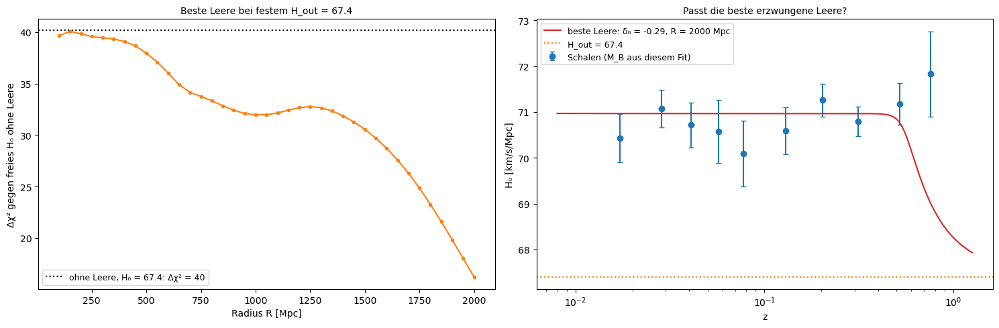

Beste Leere bei H_out = 67.4: δ₀ = -0.29, R = 2000 Mpc, Δχ² = 16.2 gegen freies H₀ ohne Leere (ohne Leere mit 67.4: 40.2); M_B dort -19.323
Δχ² bei R = 300, 600, 1000, 2000 Mpc: 39.4, 36.0, 32.0, 16.2


In [22]:
localvoid.can_explain()

**22. Wie wahrscheinlich ist eine solche Leere in ΛCDM?**

Aus dem Leistungsspektrum mit Planck-Parametern folgt, wie stark der mittlere Dichtekontrast in Kugeln vom Radius R typisch schwankt.

Bei 300 Mpc schwankt die Dichte nur um 2.3 %; die KBC-Leere läge 20 Standardabweichungen tief, mit ihrem Messfehler immer noch 7.2σ. Das lokale H₀ schwankt dort nur um 0.4 %, die Spannung beträgt 8 %. Auf großen Skalen ist das Universum im Standardmodell sehr glatt; deshalb kann eine Leere die Spannung dort nicht erklären.

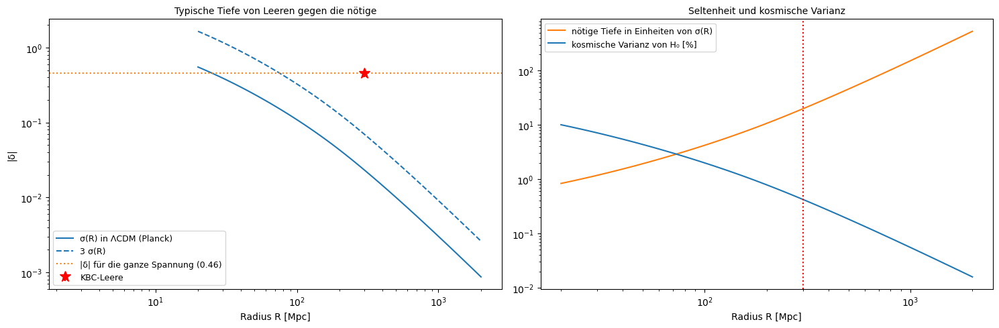

σ(300 Mpc) = 0.0232; nötig δ̄ = -0.459: 20 σ; KBC δ = -0.46: 20 σ, mit Messfehler ±0.06: 7.2 σ (p = 4e-13)
Kosmische Varianz von H₀ in 300 Mpc: 0.42 %, in 150 Mpc: 1.18 %


In [23]:
localvoid.lcdm_probability()

**23. Bayes-Abwägung**

Die Evidenz eines Modells ist die Likelihood, gemittelt über die erlaubten Parameter. Verglichen wird das Modell mit Leere gegen das ohne, mit zwei Annahmen über Tiefe und Radius.

Der Bayes-Faktor spricht gegen eine Leere (ln B = −1.79), aber nicht stark, weil das Modell mit Leere viele fast leere Varianten enthält, die so gut passen wie keine Leere. Tiefen wie die der KBC-Leere haben keine Wahrscheinlichkeit. Ein Modell mit mehr Freiheit hat immer ein besseres bestes χ², verliert aber Evidenz, wenn es seine Wahrscheinlichkeit auf ausgeschlossene Fälle verteilt.

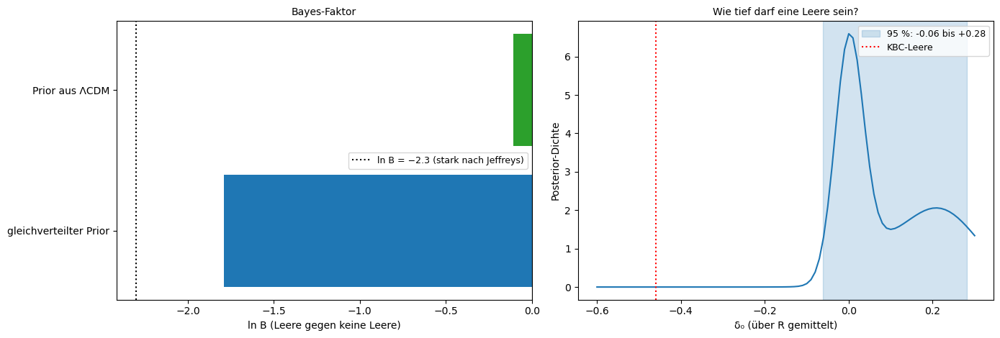

ln B (gleichverteilt) = -1.79, B = 0.167; ln B (ΛCDM-Prior) = -0.109
δ₀ Posterior: Median +0.035, 95 % -0.062 bis +0.282; bestes Δχ² auf dem Gitter -4.5


In [24]:
localvoid.bayes()

**24. Gegen Kenworthy et al. und Haslbauer et al.**

Die erlaubten Leeren neben der Grenze von Kenworthy, Scolnic und Riess (2019) aus älteren Supernovae und der Seltenheit nach Haslbauer et al. (2020) aus einer Simulation.

Die erlaubten Tiefen liegen bei jedem Radius innerhalb von ±0.1, enger als die ältere Grenze (±0.2). Die Supernovae schließen die KBC-Leere hier mit 16 bis 17σ aus, Kenworthy et al. mit 6.2σ, vermutlich wegen der viel größeren Stichprobe bei 0.02 < z < 0.1. ΛCDM schließt sie mit 7.2σ aus, Haslbauer et al. mit 6.0σ.

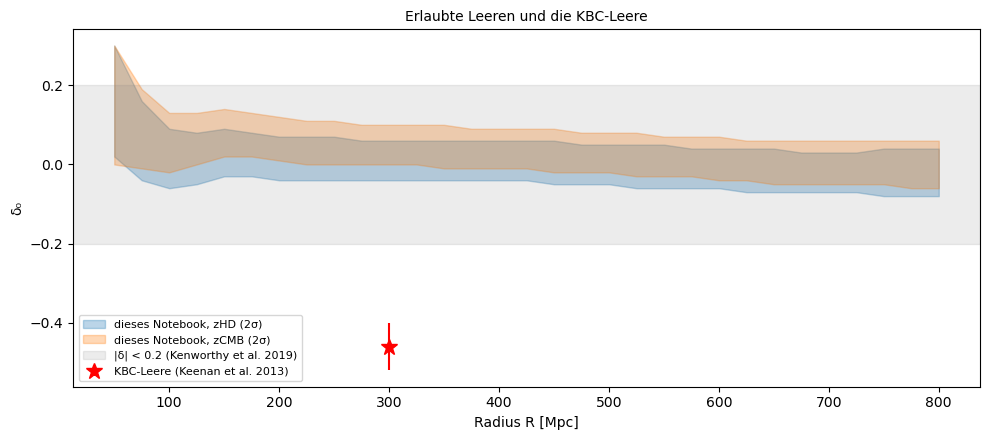

                                      Größe              dieses Notebook                                    Literatur
   Supernovae: KBC-Leere ausgeschlossen mit      16 σ (zHD), 17 σ (zCMB)                6.2 σ (Kenworthy et al. 2019)
Supernovae: erlaubte Tiefe bei 300 Mpc (2σ)              -0.04 bis +0.06 |δ| < 0.20 mit 4–5 σ (Kenworthy et al. 2019)
       ΛCDM: KBC-Leere unwahrscheinlich mit 7.2 σ (Gauß, mit Messfehler)         6.04 σ (Haslbauer et al. 2020, MXXL)
   Leere mit H_out = 67.4 gegen keine Leere                     Δχ² = 16                                            –


In [25]:
localvoid.literature()

**25. Eine eigene N-Körper-Simulation**

Kurz nach dem Urknall schwankte die Dichte nur um 10⁻⁵; die Gravitation hat diese Schwankungen verstärkt, bis das heutige Netz aus Haufen, Filamenten und Leeren entstand. Auf kleinen Skalen hilft nur eine Simulation: Die Dunkle Materie wird auf Teilchen verteilt, deren Bewegung unter der gemeinsamen Gravitation im expandierenden Universum gerechnet wird. Hier laufen zwei Particle-Mesh-Simulationen mit je 256³ Teilchen und den Parametern von Planck 2018, ein großer Würfel (2000 Mpc/h) für Leeren von 300 Mpc und ein kleiner (250 Mpc/h) für das kosmische Netz. Daten werden nicht geladen.

Der große Würfel braucht 30 Zeitschritte in etwa 20 s, der kleine 46 in etwa 30 s (die Teilchenschleifen sind mit numba kompiliert). Im kleinen Würfel ist die Dichte heute schon stark geklumpt: Die dichteste Zelle hat das 1833-Fache des Mittels, 14 % der Zellen sind leer. Ein Teilchen wiegt im großen Würfel so viel wie ein Galaxienhaufen, im kleinen ein Zehntel der Milchstraße mit Halo.

In [26]:
nbody.load()

σ₈ = 0.811; Schallhorizont (Eisenstein & Hu) 150.9 Mpc = 101.7 Mpc/h; Δ² = 1 bei k = 0.251 h/Mpc; D(a = 0.02) = 0.0254, f(z = 0) = 0.527
σ(R) linear: 8 Mpc/h 0.811, 30 Mpc/h 0.268, 100 Mpc/h 0.0654, 300 Mpc = 202 Mpc/h 0.0231


großer Würfel: L = 2000 Mpc/h, 256³ Teilchen zu je 4.17e+13 M☉/h, 30 Schritte in 18 s; δ auf dem Gitter: σ = 0.93, Maximum 63, leere Zellen 0.1%
kleiner Würfel: L = 250 Mpc/h, 256³ Teilchen zu je 8.14e+10 M☉/h, 46 Schritte in 27 s; δ auf dem Gitter: σ = 6.04, Maximum 1833, leere Zellen 14.3%


**26. Das Spektrum am Anfang**

Das Leistungsspektrum sagt, wie stark die Dichte auf jeder Skale schwankt; die Anfangsfelder werden daraus gewürfelt. Verglichen wird das gewürfelte Spektrum mit der Vorgabe.

Zusammen decken die Würfel drei Größenordnungen in k ab, mit den akustischen Wellen zwischen 0.05 und 0.3 h/Mpc. Das gewürfelte Spektrum trifft die Vorgabe auf 1 %, bei großen Skalen streut es, weil dort nur wenige Moden liegen. Nichtlinear wird es heute unter etwa 25 Mpc/h.

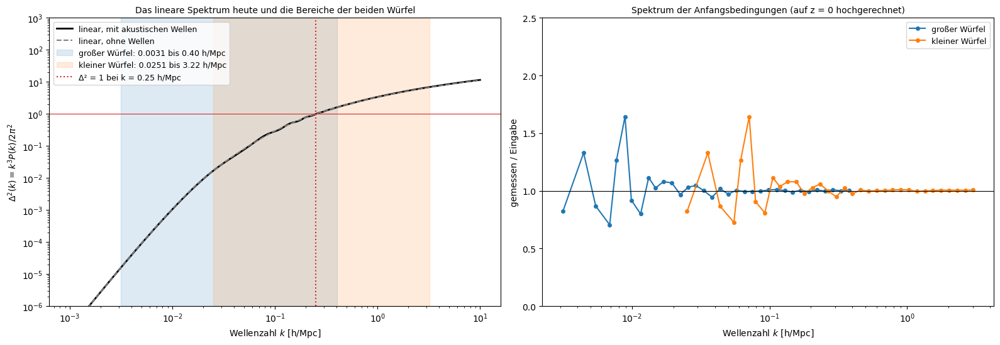

Würfel groß: Anfangsspektrum / Eingabe = 1.009 ± 0.035 (Bins mit 5 k_f < k < 0.3 k_Nyq); Zelle 7.81 Mpc/h


Würfel klein: Anfangsspektrum / Eingabe = 1.012 ± 0.035 (Bins mit 5 k_f < k < 0.3 k_Nyq); Zelle 0.98 Mpc/h
nichtlinear ab k = 0.25 h/Mpc, also auf Skalen unter 2π/k = 25 Mpc/h; σ₈ = 0.811


In [27]:
nbody.initial_spectrum()

**27. Das kosmische Netz entsteht**

Eine Scheibe von 20 Mpc/h Dicke durch den kleinen Würfel bei z = 3, 1 und 0.

Bei z = 3 ist das Netz schon angelegt, aber kontrastarm; bis heute leeren sich die Gebiete dazwischen, und die Materie sammelt sich in Filamenten und Haufen. Der Anteil des Volumens mit weniger als halber mittlerer Dichte wächst von 29 % auf 68 %, enthält aber nur 10 % der Masse; 40 % der Masse stecken in 1.3 % des Volumens.

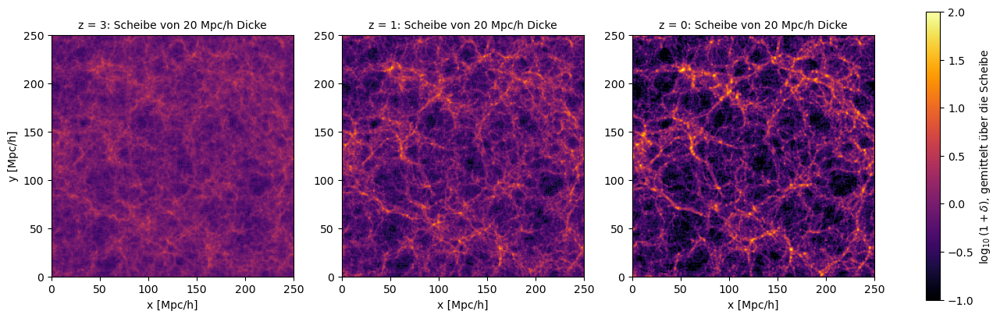

z = 3: δ > 9 in 0.17% des Volumens mit 2.5% der Masse; δ < −0.5 in 29.2% des Volumens mit 9.5% der Masse; dichteste Zelle δ = 145
z = 1: δ > 9 in 0.97% des Volumens mit 20.4% der Masse; δ < −0.5 in 54.2% des Volumens mit 11.6% der Masse; dichteste Zelle δ = 618
z = 0: δ > 9 in 1.33% des Volumens mit 39.6% der Masse; δ < −0.5 in 68.1% des Volumens mit 9.9% der Masse; dichteste Zelle δ = 1833


In [28]:
nbody.cosmic_web()

**28. Wächst die Simulation richtig?**

Das Spektrum am Ende wird durch das Spektrum desselben Anfangsfelds mal dem linearen Wachstumsfaktor geteilt; so fällt die Streuung der Moden heraus, und es bleibt der Fehler des Codes oder echtes nichtlineares Wachstum.

Im großen Würfel wachsen die großen Moden auf 0.3 % genau linear; erst über k = 0.1 h/Mpc kommt nichtlineares Wachstum dazu. Im kleinen Würfel ist es bei k = 1 h/Mpc heute das 5.2-Fache, und die Grenze der linearen Theorie wandert mit der Zeit zu immer größeren Skalen.

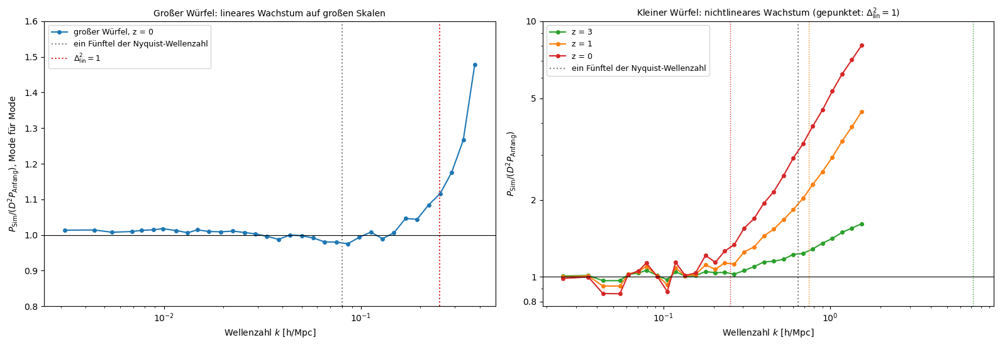

großer Würfel, k < 0.1 h/Mpc: Verhältnis 1.003 ± 0.012 (24 Bins); bei k = 0.2: 1.05
kleiner Würfel z = 3: Verhältnis bei k = 0.1: 0.99, k = 0.3: 1.05, k = 1: 1.40, k = 1.5: 1.6
kleiner Würfel z = 1: Verhältnis bei k = 0.1: 0.96, k = 0.3: 1.23, k = 1: 2.86, k = 1.5: 4.4
kleiner Würfel z = 0: Verhältnis bei k = 0.1: 0.93, k = 0.3: 1.52, k = 1: 5.15, k = 1.5: 8.0


In [29]:
nbody.growth_check()

**29. Der BAO-Peak in der Simulation**

Die Korrelationsfunktion des großen Würfels heute, des Anfangsfelds und der linearen Theorie, mit und ohne akustische Wellen. Die Wellen erzeugen einen Peak beim Schallhorizont um 100 Mpc/h.

Der Peak liegt in Theorie, Anfangsfeld und Simulation bei 101, 101 und 100 Mpc/h. Er wird niedriger und breiter, weil die Teilchen seit dem Anfang im Mittel 10 Mpc/h gewandert sind, verschiebt sich aber nur um 1 %. Deshalb taugt er als Lineal.

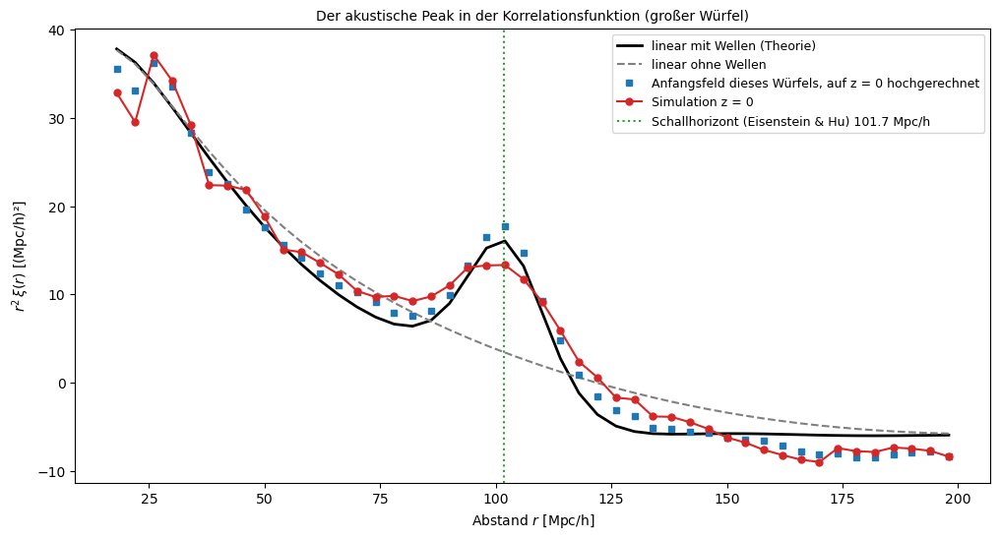

Theorie linear   : Peak bei  100.9 Mpc/h, r²ξ bei 102 Mpc/h =  16.1
Anfangsfeld      : Peak bei  101.1 Mpc/h, r²ξ bei 102 Mpc/h =  17.7
Simulation z = 0 : Peak bei  100.1 Mpc/h, r²ξ bei 102 Mpc/h =  13.3
mittlere Verschiebung der Teilchen seit dem Anfang (linear, 3D): 10.1 Mpc/h


In [30]:
nbody.bao_in_simulation()

**30. Wie stark schwankt die Dichte in Kugeln?**

Die Dichte wird in Kugeln um jeden Gitterpunkt gemittelt; ihre Streuung σ(R) gegen den Radius, für Simulation, Anfangsfeld und lineare Theorie.

Ab etwa 20 Mpc/h liegen alle drei aufeinander, darunter liegt die Simulation darüber: σ₈ ist 0.896 statt 0.814, weil Haufen dichter werden, als die lineare Theorie erlaubt. Bei 300 Mpc schwankt die Dichte nur um 2.3 %, in Simulation und Theorie gleich.

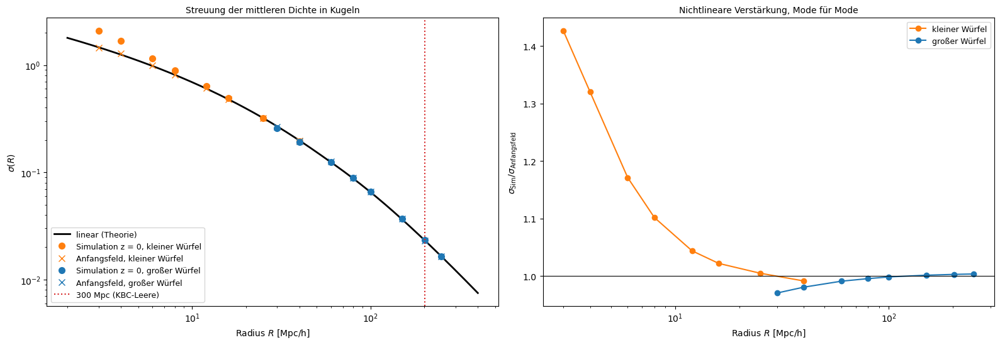

L =    250, R =     3 Mpc/h: σ Simulation 2.0819, Anfangsfeld 1.4596, Theorie 1.4629; Verhältnis 1.426
L =    250, R =     4 Mpc/h: σ Simulation 1.6900, Anfangsfeld 1.2801, Theorie 1.2498; Verhältnis 1.320
L =    250, R =     6 Mpc/h: σ Simulation 1.1575, Anfangsfeld 0.9884, Theorie 0.9802; Verhältnis 1.171
L =    250, R =     8 Mpc/h: σ Simulation 0.8963, Anfangsfeld 0.8136, Theorie 0.8110; Verhältnis 1.102
L =    250, R =    12 Mpc/h: σ Simulation 0.6339, Anfangsfeld 0.6074, Theorie 0.6039; Verhältnis 1.044
L =    250, R =    16 Mpc/h: σ Simulation 0.4922, Anfangsfeld 0.4818, Theorie 0.4792; Verhältnis 1.022
L =    250, R =    25 Mpc/h: σ Simulation 0.3208, Anfangsfeld 0.3193, Theorie 0.3209; Verhältnis 1.005
L =    250, R =    40 Mpc/h: σ Simulation 0.1939, Anfangsfeld 0.1956, Theorie 0.1979; Verhältnis 0.991
L =   2000, R =    30 Mpc/h: σ Simulation 0.2562, Anfangsfeld 0.2640, Theorie 0.2681; Verhältnis 0.970
L =   2000, R =    40 Mpc/h: σ Simulation 0.1909, Anfangsfeld 0.1947, The

In [31]:
nbody.sphere_variance()

**31. Die Verteilung der Dichte in Kugeln**

Histogramme der mittleren Dichte in Kugeln von 8 bis 202 Mpc/h, mit einer Gaußkurve und einer Lognormalverteilung derselben Streuung.

In kleinen Kugeln ist die Verteilung stark schief: Bei 8 Mpc/h ist der häufigste Wert −0.56, also eine Leere, und das Mittel null halten die wenigen sehr dichten Kugeln um Haufen; die Lognormalverteilung trifft die Form. In großen Kugeln wird die Verteilung gaußisch. Die leerste Kugel von 300 Mpc hat nur −0.083.

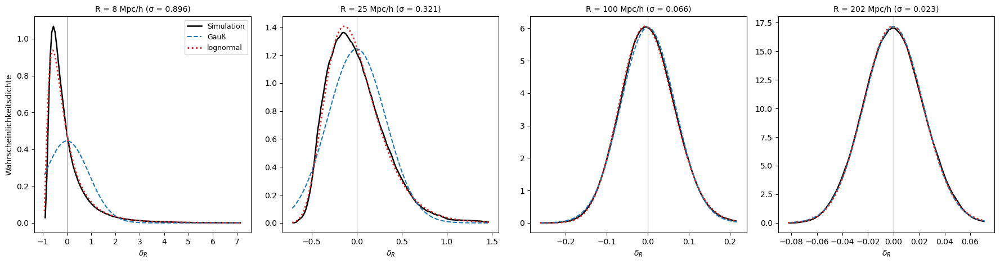

R =     8 Mpc/h: σ = 0.896, Schiefe +3.52, Median -0.267, häufigster Wert -0.559, kleinster Wert -0.931 (-1.0σ)
R =    25 Mpc/h: σ = 0.321, Schiefe +0.96, Median -0.047, häufigster Wert -0.142, kleinster Wert -0.715 (-2.2σ)
R =   100 Mpc/h: σ = 0.066, Schiefe +0.13, Median -0.001, häufigster Wert -0.005, kleinster Wert -0.263 (-4.0σ)
R =   202 Mpc/h: σ = 0.023, Schiefe +0.05, Median -0.000, häufigster Wert -0.001, kleinster Wert -0.083 (-3.6σ)


In [32]:
nbody.sphere_distribution()

**32. Wie selten ist die KBC-Leere?**

Die Verteilung der Dichte in Kugeln von 300 Mpc über alle Punkte des großen Würfels, in Einheiten ihrer Streuung, und die Wahrscheinlichkeit, so tief oder tiefer zu liegen.

Die Verteilung folgt genau der Gaußkurve. Die KBC-Leere mit −0.46 liegt 19.8σ unter dem Mittel, mit ihrem Messfehler 7.1σ (p = 4·10⁻¹³). Die tiefste Leere dieser Größe, die man im ganzen beobachtbaren Universum einmal erwarten kann, hat −0.10.

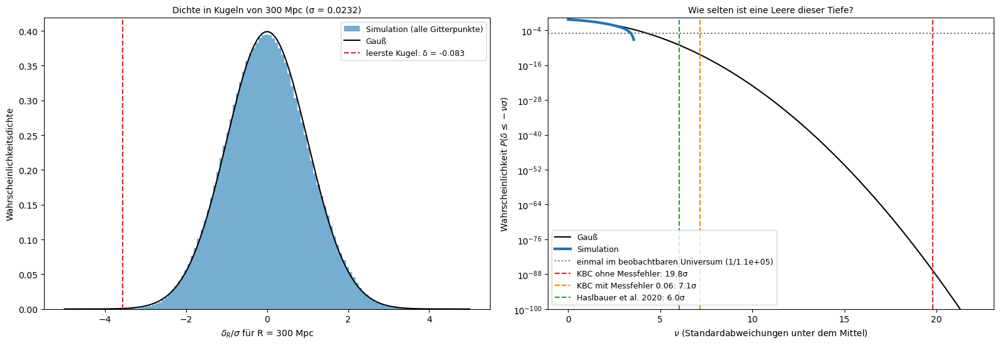

σ(300 Mpc) = 0.0232 (linear 0.0231); Schiefe +0.053; leerste Kugel δ = -0.0827 = -3.56σ; unabhängige Kugeln im Würfel ≈ 231, im beobachtbaren Universum ≈ 1.06e+05
KBC ohne Messfehler: 19.8σ, p = 1.6e-87, erwartete Zahl im beobachtbaren Universum 1.7e-82
KBC mit Messfehler: 7.1σ, p = 4.4e-13, erwartete Zahl im beobachtbaren Universum 4.6e-08
nötige Tiefe für p = 1/1e+05: δ = -0.099


In [33]:
nbody.kbc_rarity()

**33. Wo Leeren dieser Tiefe häufig sind**

Welcher Anteil der Kugeln eine Unterdichte von 46 % oder mehr hat, für Radien von 3 bis 100 Mpc/h, einmal um zufällige Punkte und einmal um Teilchen, also dort, wo Beobachter in Galaxien sitzen.

Bei 8 Mpc/h ist ein Drittel der Kugeln so leer, bei 25 Mpc/h noch 3 %, bei 50 Mpc/h nur 0.01 %, ab 80 Mpc/h keine einzige. Um Teilchen sind Leeren seltener, weil wer in einer Galaxie sitzt, eher in dichter Umgebung sitzt. Leeren dieser Tiefe sind also gewöhnlich, aber nur bis etwa 45 Mpc Radius (1 % der Kugeln bei 30 Mpc/h).

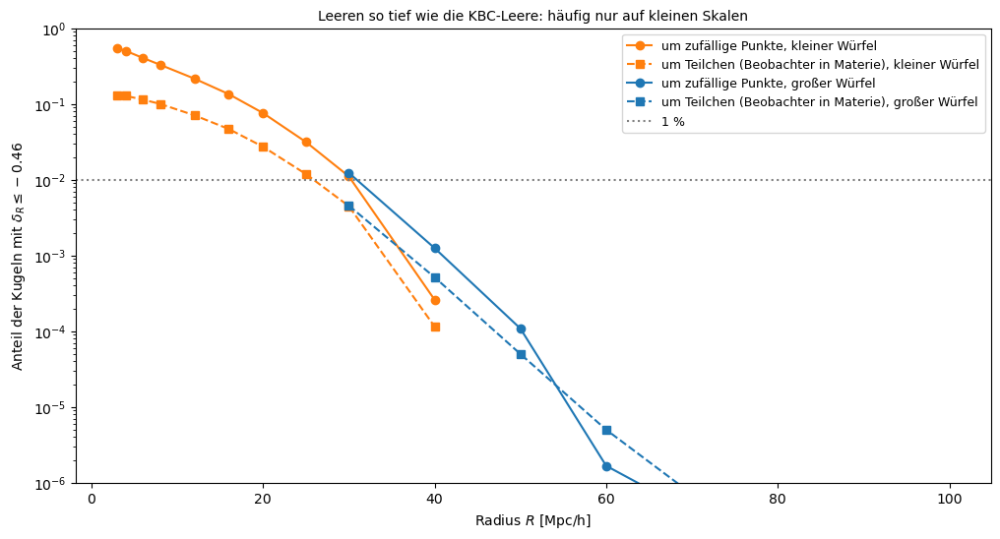

zufällige Punkte      : Anteil 1 % bei R = 30 Mpc/h (45 Mpc); R = 8: 32.96%, R = 16: 13.50%, R = 25: 3.15%, R = 40: 0.13%, R = 60: 0.00%
Beobachter in Materie : Anteil 1 % bei R = 26 Mpc/h (38 Mpc); R = 8: 10.03%, R = 16: 4.68%, R = 25: 1.19%, R = 40: 0.05%, R = 60: 0.00%
R = 8 Mpc/h: Median δ_R um zufällige Punkte -0.267, um Teilchen +0.469
R = 25 Mpc/h: Median δ_R um zufällige Punkte -0.047, um Teilchen +0.099
R = 60 Mpc/h: Median δ_R um zufällige Punkte -0.006, um Teilchen +0.016


In [34]:
nbody.void_environments()

**34. Die lokale Hubble-Konstante**

Für jeden Beobachter im großen Würfel: welches H₀ er aus den Geschwindigkeiten in einer Kugel um sich misst, und wie das mit der Dichte der Kugel zusammenhängt.

Das lokale H₀ schwankt um 3.2 % in 74 Mpc und nur um 0.52 % in 300 Mpc; es folgt der linearen Theorie. Kein Beobachter misst bei 300 Mpc mehr als +2.1 %. Die KBC-Leere verlangt +8.1 %, das sind 16σ.

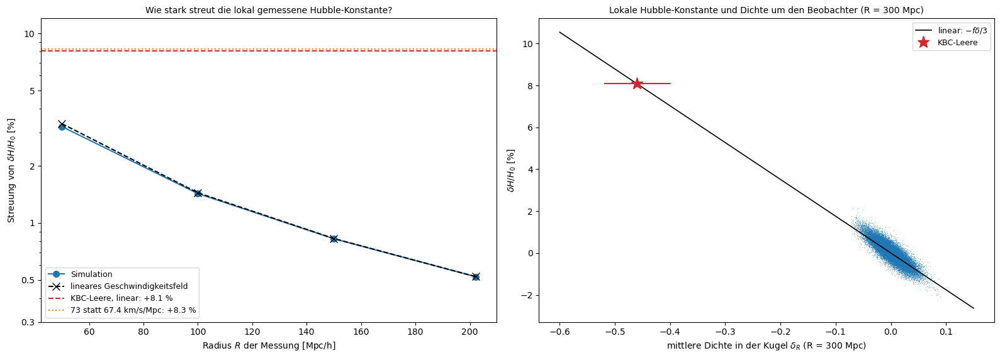

R =    50 Mpc/h ( 74 Mpc): σ(δH/H₀) = 3.225 % (linear 3.342 %), größter Wert +12.77 %
R =   100 Mpc/h (148 Mpc): σ(δH/H₀) = 1.429 % (linear 1.443 %), größter Wert +5.80 %
R =   150 Mpc/h (223 Mpc): σ(δH/H₀) = 0.826 % (linear 0.827 %), größter Wert +3.57 %
R =   202 Mpc/h (300 Mpc): σ(δH/H₀) = 0.521 % (linear 0.521 %), größter Wert +2.13 %
Steigung δH/H₀ gegen δ_R bei 300 Mpc: -0.195 (−f/3 = -0.176); KBC verlangt +8.1 % = 16σ


In [35]:
nbody.local_h0()

**35. Gegen die veröffentlichten Werte**

Die Spannung der KBC-Leere mit ΛCDM aus der eigenen Simulation, der linearen Theorie und der Simulation Millennium-XXL (Haslbauer et al. 2020); dazu die Streuung des lokalen H₀ neben Wu und Huterer (2017).

Die eigene Simulation gibt 7.1σ, fast genau die lineare Theorie (7.2σ), Haslbauer et al. 6.0σ, die die Dichte anders definieren. Die Streuung des lokalen H₀ bei 300 Mpc ist 0.52 %, etwas mehr als die 0.42 % von Wu und Huterer, die tiefer messen. Die Hubble-Spannung braucht 8 %, sechzehnmal mehr.

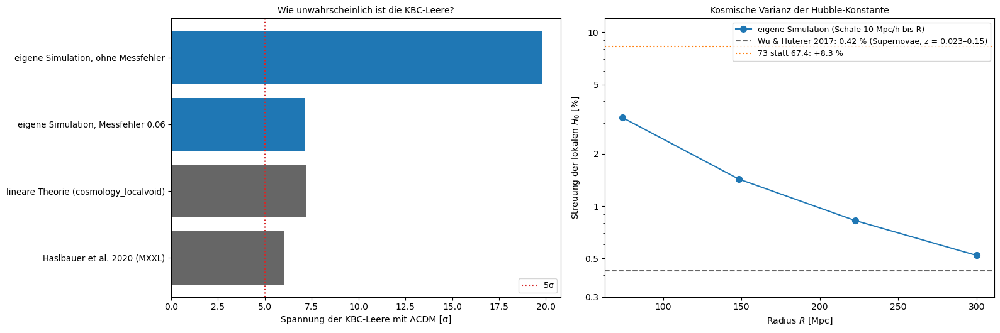

eigene Simulation, ohne Messfehler      :  19.8σ
eigene Simulation, Messfehler 0.06      :   7.1σ
lineare Theorie (cosmology_localvoid)   :   7.2σ
Haslbauer et al. 2020 (MXXL)            :   6.0σ
σ(H₀,lokal) bei 300 Mpc: 0.52 %, Wu & Huterer 0.42 %; nötig für die Spannung: 8.3 % = 16σ


In [36]:
nbody.literature()

**36. Standardsirenen: GW170817**

Am 17. August 2017 maßen LIGO und Virgo die Gravitationswelle zweier verschmelzender Neutronensterne, 1.7 s später sah Fermi einen Gammablitz, elf Stunden danach fanden Teleskope eine Kilonova in der Galaxie NGC 4993. Die Form der Welle verrät die Massen, ihre Amplitude dann die Entfernung, ohne Eichung an Cepheiden; mit der Geschwindigkeit der Galaxie folgt H₀. Holz und Hughes nannten solche Quellen Standardsirenen. Geladen werden die Stichproben der Parameterschätzung aus GWTC-1, für kleine und große Spins, und Stichproben des Priors.

Mit kleinen Spins ist die Entfernung 40 Mpc (+7/−15, 90 %), mit großen 42 Mpc; die Bahn ist gekippt (cos θ = −0.84). Die Galaxie entfernt sich nach Abzug ihrer Eigenbewegung mit 3017 ± 166 km/s.

In [37]:
sirens.load()

kleine Spins: 8078 Stichproben, d = 40.0 +7.3/−15.0 Mpc (90 %), cos θ_JN = -0.84, Himmel fest bei RA = 197.45°, Dec = -23.38°
große  Spins: 4041 Stichproben, d = 41.7 +5.7/−12.7 Mpc (90 %), cos θ_JN = -0.88, Himmel fest bei RA = 197.45°, Dec = -23.38°
Prior: 7109 Stichproben, d von 2.3 bis 75.1 Mpc
Hubble-Geschwindigkeit v_H = v_r − ⟨v_p⟩ = 3017 ± 166 km/s


**37. Entfernung und Neigung aus der Welle**

Die Verteilung der Entfernung für beide Spin-Annahmen neben dem Prior, und jede Stichprobe mit ihrer Entfernung gegen die Neigung der Bahn.

Die Daten ziehen die Entfernung weit unter das, was der Prior bevorzugt, auf 40 Mpc. Entfernung und Neigung sind zu 0.98 korreliert: Eine schräg gesehene Bahn strahlt in unsere Richtung schwächer, und dann muss sie näher sein. Ob die Bahn um 10° oder um 60° gekippt ist, kann die Welle allein nicht sagen.

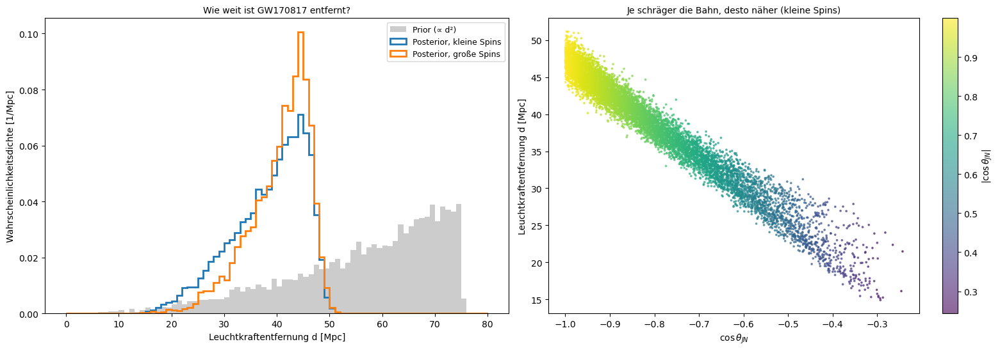

kleine Spins: d = 40.0 Mpc, 68 %: 30.8 bis 45.3, 90 %: 24.9 bis 47.3; Korrelation von d und |cos θ_JN|: +0.98; Anteil mit |cos θ_JN| > 0.9: 0.34
große  Spins: d = 41.7 Mpc, 68 %: 34.6 bis 45.7, 90 %: 29.1 bis 47.5; Korrelation von d und |cos θ_JN|: +0.97; Anteil mit |cos θ_JN| > 0.9: 0.44


In [38]:
sirens.distance_inclination()

**38. Die Galaxie und ihre Geschwindigkeit**

Das Hubble-Diagramm der nächsten 80 Mpc mit den Geraden von Planck und SH0ES; GW170817 einmal mit der gemessenen und einmal mit der um die Eigenbewegung korrigierten Geschwindigkeit.

Die Eigenbewegung macht 9 % der Geschwindigkeit aus. Der Fehler der Entfernung ist viel größer als der der Geschwindigkeit, beide Geraden laufen durch den Fehlerbalken. Grob ist H₀ = 3017/40 = 75 km/s/Mpc, aber die Entfernung allein lässt 66 bis 98 zu.

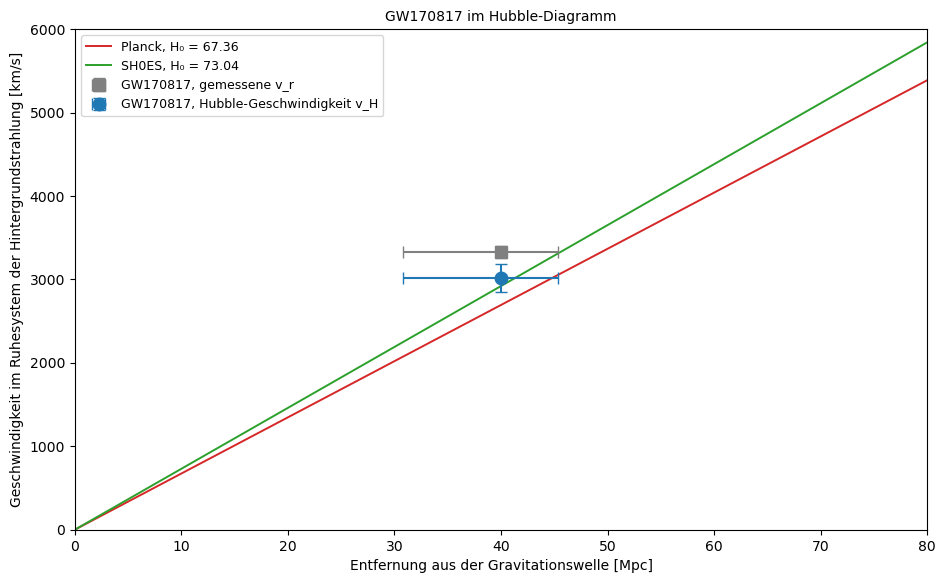

v_H = 3017 ± 166 km/s (Eigenbewegung 9 % von v_r)
grob H₀ = v_H/d: 75.5 beim Median d = 40.0 Mpc, 66.5 bis 97.8 für das 68-%-Intervall der Entfernung
Planck verlangt d = 44.8 Mpc, SH0ES d = 41.3 Mpc


In [39]:
sirens.host_galaxy()

**39. Vom Prior der Entfernung zum Prior auf H₀**

Drei Wege zur Verteilung von H₀: jede Entfernungsstichprobe einfach umgerechnet, die Standardanalyse mit Prior ∝ 1/H₀ und dem Fehler der Geschwindigkeit, und dieselbe mit flachem Prior.

Alle drei steigen bei 60 steil an und haben einen langen Ausläufer zu großen Werten, von den schräg gesehenen, nahen Lösungen. Das Maximum hängt kaum vom Prior ab (67.5 bis 69.2), der Median stark (75.5 bis 79.3). Deshalb nennt man bei einer Sirene das Maximum.

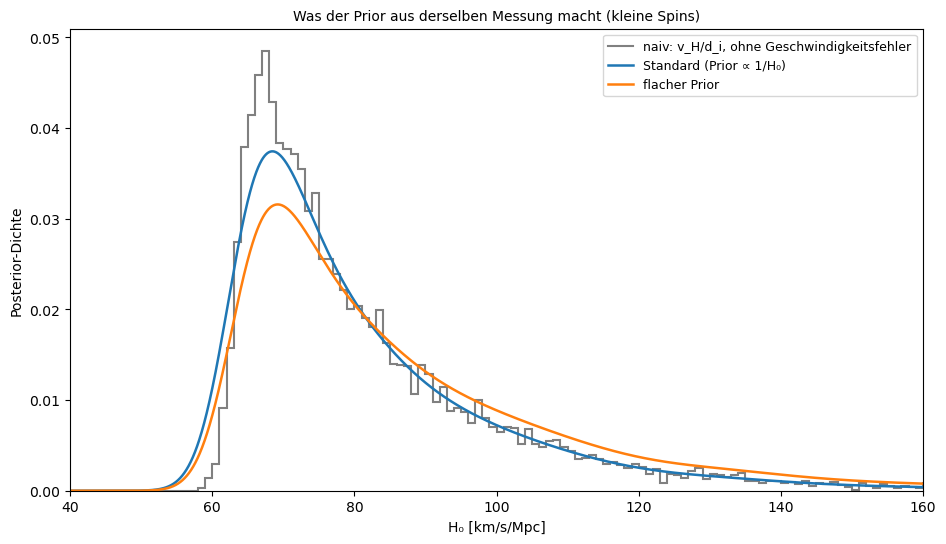

naiv: Maximum bei 67.5, Median 75.5
Standard (Prior ∝ 1/H₀) : MAP 68.5 +18.2/−7.7; Median 75.7 +22.3/−10.0
flacher Prior           : MAP 69.2 +23.4/−8.1; Median 79.3 +27.4/−12.3


In [40]:
sirens.distance_prior()

**40. H₀ aus GW170817**

Die Standardanalyse für kleine und große Spins neben den Bändern von Planck und SH0ES.

Mit kleinen Spins ist H₀ = 68.5 (+18/−8), mit großen 68.2 (+12/−7), nahe am veröffentlichten Wert 70 (+12/−8). Beide Bänder liegen nahe dem Maximum; eine einzelne Sirene ohne Kenntnis des Winkels entscheidet nichts.

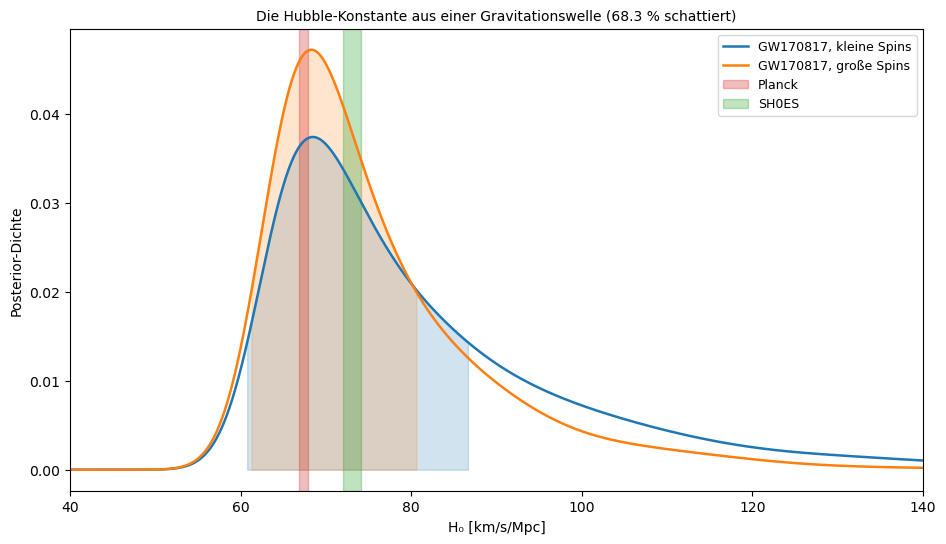

kleine Spins: MAP 68.5 +18.2/−7.7; Median 75.7 +22.3/−10.0; p(73.04)/p(67.36) = 0.87
große  Spins: MAP 68.2 +12.3/−7.0; Median 72.4 +14.9/−7.6; p(73.04)/p(67.36) = 0.81
Abbott et al. 2017: MAP 70.0 +12.0/−8.0


In [41]:
sirens.h0_siren()

**41. H₀ und die Neigung der Bahn**

Die gemeinsame Verteilung von H₀ und der Neigung der Bahn.

Sie bildet ein schräges Band: Kleine H₀ gehören zu Bahnen, die man fast von unten sieht und die weit weg sind, große zu schräg gesehenen. Legt man H₀ auf Planck oder SH0ES fest, verschiebt sich die Neigung; umgekehrt kann eine unabhängige Messung des Winkels H₀ festlegen.

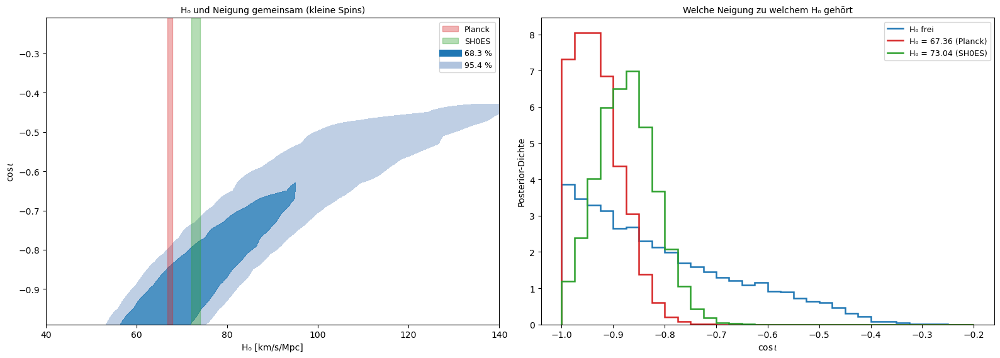

H₀ frei             : cos ι von -0.958 bis -0.631 (68 %), also ι von 129° bis 163°
H₀ = 67.36 (Planck) : cos ι von -0.978 bis -0.883 (68 %), also ι von 152° bis 168°
H₀ = 73.04 (SH0ES)  : cos ι von -0.932 bis -0.819 (68 %), also ι von 145° bis 159°


In [42]:
sirens.h0_inclination()

**42. Der Jet als Winkelmesser**

Radiobeobachtungen des Jets der Kilonova geben den Beobachtungswinkel. Behalten werden nur die Stichproben, deren Winkel und Entfernung dazu passen.

1726 von 8078 Stichproben passen: 44.7 Mpc und 19° Beobachtungswinkel. Damit ist H₀ = 67.1 ± 4.6 km/s/Mpc, unabhängig von der Spin-Annahme, und der Fehler sinkt von 19 auf 7 %. Hotokezaka et al. (2019) erhalten mit einem vollen Modell des Jets 68.9 ± 4.6.

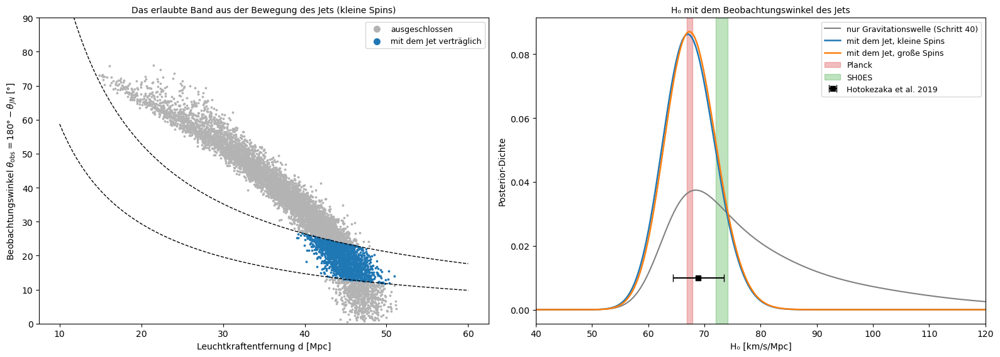

kleine Spins: 1726 von 8078 Stichproben bleiben; d = 44.7 Mpc (68 %: 42.9 bis 46.6), θ_obs = 19.3°; H₀: MAP 67.1 +4.8/−4.5; Median 67.2 +4.7/−4.5
große  Spins: 1111 von 4041 Stichproben bleiben; d = 44.6 Mpc (68 %: 42.8 bis 46.3), θ_obs = 19.2°; H₀: MAP 67.3 +4.7/−4.5; Median 67.5 +4.7/−4.5
Hotokezaka et al. 2019: Median 68.9 +4.6/−4.5


In [43]:
sirens.jet()

**43. Wie viel die Eigenbewegung ausmacht**

H₀ mit dem Jet für verschiedene Annahmen über die Eigenbewegung der Galaxie.

Die Annahmen verschieben H₀ wenig, solange man korrigiert; ohne jede Korrektur springt es aber auf 74, fast auf SH0ES. Mit dem Jet ist die Eigenbewegung der größte einzelne Fehler: 150 km/s Unsicherheit bei 40 Mpc wiegen so viel wie 5 % in der Entfernung.

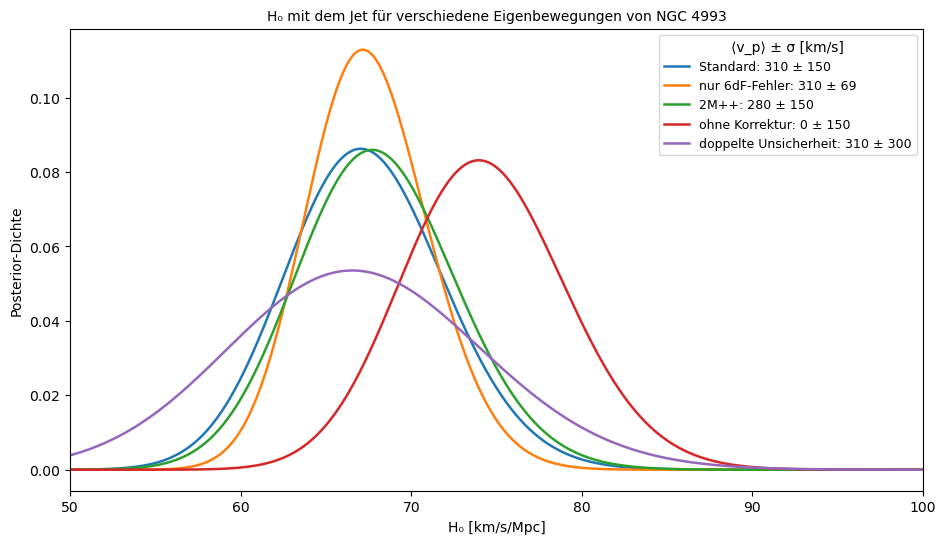

Standard: 310 ± 150               : MAP 67.1 +4.8/−4.5; Median 67.2 +4.7/−4.5; Breite des 68-%-Intervalls 9.3
nur 6dF-Fehler: 310 ± 69          : MAP 67.2 +3.7/−3.4; Median 67.4 +3.7/−3.4; Breite des 68-%-Intervalls 7.1
2M++: 280 ± 150                   : MAP 67.7 +4.8/−4.5; Median 67.9 +4.7/−4.5; Breite des 68-%-Intervalls 9.2
ohne Korrektur: 0 ± 150           : MAP 74.0 +5.0/−4.6; Median 74.2 +4.9/−4.7; Breite des 68-%-Intervalls 9.6
doppelte Unsicherheit: 310 ± 300  : MAP 66.6 +7.5/−7.4; Median 66.7 +7.5/−7.3; Breite des 68-%-Intervalls 14.9


In [44]:
sirens.peculiar_velocity()

**44. Wie viele Sirenen braucht man?**

Simuliert werden N Ereignisse wie GW170817, um Zufallswerte verschoben, und ihre Verteilungen multipliziert, mit und ohne Kenntnis des Winkels.

Ein Ereignis gibt 19 % Fehler, mit dem Jet 7 %. Schon das zweite Ereignis schneidet den Ausläufer weg, danach fällt der Fehler wie 1/√N. Für 2 % braucht man etwa 83 Ereignisse ohne und 12 mit Winkel.

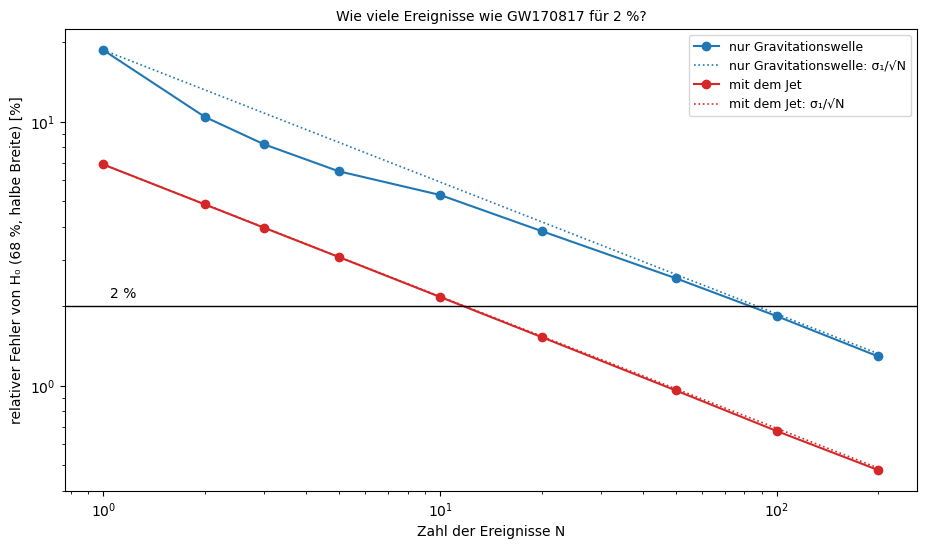

nur Gravitationswelle : N = 1: 18.7 %, N = 2: 10.4 %, N = 3: 8.2 %, N = 5: 6.5 %, N = 10: 5.3 %, N = 20: 3.9 %, N = 50: 2.6 %, N = 100: 1.8 %, N = 200: 1.3 %; 2 % bei N ≈ 83
mit dem Jet           : N = 1: 6.9 %, N = 2: 4.9 %, N = 3: 4.0 %, N = 5: 3.1 %, N = 10: 2.2 %, N = 20: 1.5 %, N = 50: 1.0 %, N = 100: 0.7 %, N = 200: 0.5 %; 2 % bei N ≈ 12


In [45]:
sirens.how_many()

**45. Gegen die veröffentlichten Werte und die anderen Wege**

Die eigenen Werte neben den veröffentlichten Sirenen, den Ergebnissen der GWTC-3-Kosmologie aus 47 Ereignissen ohne Licht, und neben Planck und SH0ES.

Alle Sirenen liegen zwischen 67 und 70 km/s/Mpc, mit Fehlern von 4.5 bis 18. Mit dem Jet ist der eigene Wert 1.2σ von SH0ES und nahe an Planck. Die dunklen Sirenen sind noch ungenauer als das eine helle Ereignis mit Jet; für eine Entscheidung mit 3σ müsste der Fehler unter etwa 2 km/s/Mpc fallen.

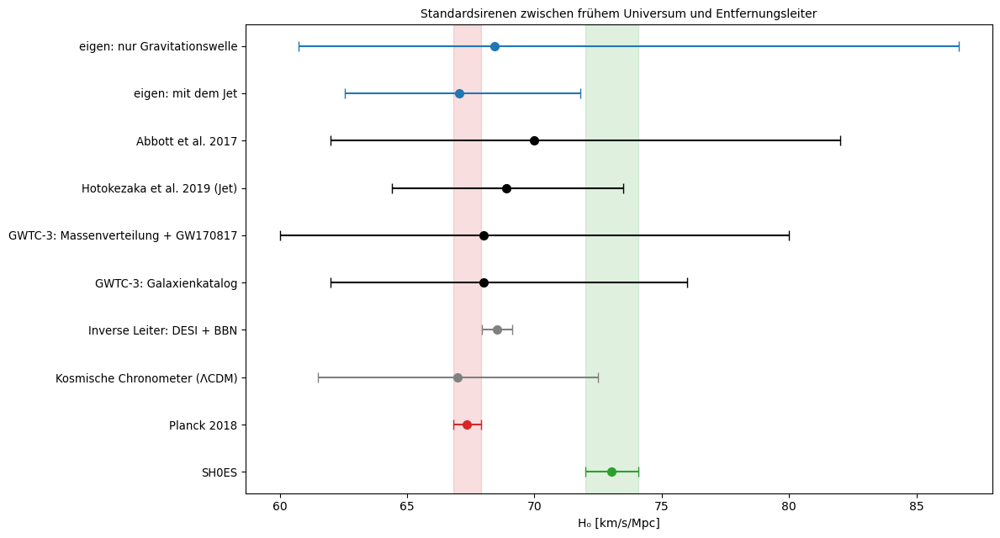

eigen: nur Gravitationswelle  : H₀ = 68.5 +18.2/−7.7; gegen Planck +0.1 σ, gegen SH0ES -0.3 σ
eigen: mit dem Jet            : H₀ = 67.1 +4.8/−4.5; gegen Planck -0.1 σ, gegen SH0ES -1.2 σ


In [46]:
sirens.literature()

**46. Kosmische Chronometer**

Supernovae sind Kerzen bekannter Helligkeit, die BAO ein Lineal bekannter Länge; beide brauchen eine Eichung. Jimenez und Loeb schlugen 2002 einen dritten Weg vor: Man misst die Zeit zwischen zwei Rotverschiebungen, denn H(z) = −1/(1 + z) · dz/dt. Die Zeit liest man am Alter der massivsten passiv alternden Galaxien ab, die fast gleichzeitig entstanden sind und seither nur altern. Geladen werden 15 solche Messungen (Moresco et al.) mit den Fehlern der Sternmodelle, dazu die BAO von DESI und die Supernovae von Pantheon+.

15 Messungen zwischen z = 0.18 und 1.97 mit 5 bis 27 % Fehler; dazu 13 BAO-Werte und 1590 Supernovae über z = 0.01.

In [47]:
chronometers.load()

Chronometer: 15 Messungen bei z = 0.1791 bis 1.965, Fehler 5 bis 27 %
DESI: 13 BAO-Werte; Pantheon+: 1590 Supernovae mit z > 0.01
Kovarianz: Determinante 4.560e+33, Bedingungszahl 144


**47. Die Messungen**

H(z) mit den Fehlern aus der Tabelle, neben ΛCDM mit H₀ von Planck (67.36) und von SH0ES (73.04); daneben die Wachstumsgeschwindigkeit des Skalenfaktors, H/(1 + z).

Die meisten Punkte liegen zwischen beiden Kurven oder näher an Planck; χ² ist 6.2 gegen Planck und 14.8 gegen 73 bei 15 Werten, die Tabellenfehler sind also eher vorsichtig. Die Wachstumsgeschwindigkeit fällt bis z ≈ 0.6 und steigt danach: Ihr Minimum markiert den Beginn der Beschleunigung, die Punkte deuten es an.

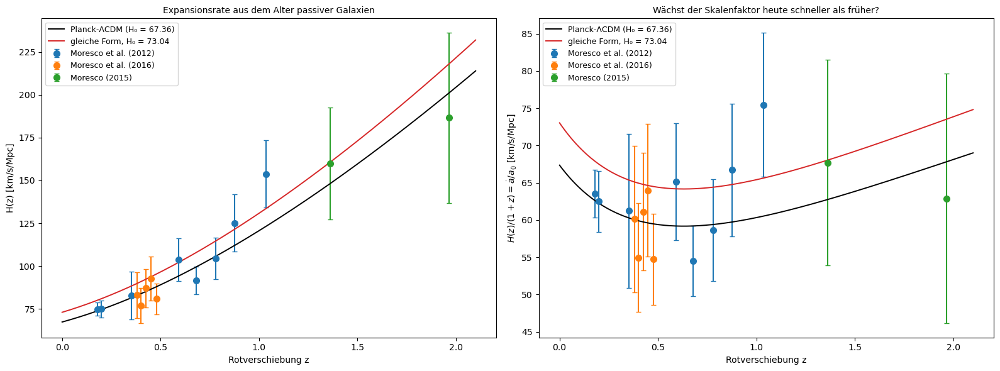

gegen Planck    : χ² (nur Diagonale) = 6.2 bei 15 Werten, mittlere Abweichung +0.11 σ
gegen H₀ = 73.04: χ² (nur Diagonale) = 14.8 bei 15 Werten, mittlere Abweichung -0.61 σ
z = 0.1791: H =   74.9 ±  3.8 ( 5.1 %)  Moresco et al. (2012)
z = 0.1993: H =   75.0 ±  4.9 ( 6.5 %)  Moresco et al. (2012)
z = 0.3519: H =   82.8 ± 13.9 (16.9 %)  Moresco et al. (2012)
z = 0.3802: H =   83.0 ± 13.5 (16.3 %)  Moresco et al. (2016)
z = 0.4004: H =   77.0 ± 10.2 (13.2 %)  Moresco et al. (2016)
z = 0.4247: H =   87.1 ± 11.2 (12.9 %)  Moresco et al. (2016)
z = 0.4497: H =   92.8 ± 12.9 (13.9 %)  Moresco et al. (2016)
z = 0.4783: H =   80.9 ±  9.0 (11.2 %)  Moresco et al. (2016)
z = 0.5929: H =  103.8 ± 12.5 (12.0 %)  Moresco et al. (2012)
z = 0.6797: H =   91.6 ±  8.0 ( 8.7 %)  Moresco et al. (2012)
z = 0.7812: H =  104.5 ± 12.2 (11.7 %)  Moresco et al. (2012)
z = 0.8754: H =  125.1 ± 16.7 (13.3 %)  Moresco et al. (2012)
z = 1.0370: H =  153.7 ± 19.7 (12.8 %)  Moresco et al. (2012)
z = 1.3630: H =  160.

In [48]:
chronometers.measurements()

**48. Der Fehlerhaushalt und die Kovarianz**

Die relativen Fehler jedes Punktes nach Quelle: Statistik und Metallizität, die Anfangsmassenfunktion der Sterne (IMF) und das Modell der Sternpopulationen; daneben die Korrelationsmatrix, die die gemeinsamen Modellfehler erzeugen.

Der Tabellenfehler liegt im Mittel bei 13 %, das Modell der Sternpopulationen trägt 5 % bei, die IMF fast nichts. Die Punkte sind im Median zu 0.13 korreliert, die beiden genauesten bei z = 0.18 und 0.20 am stärksten, weil dort der gemeinsame Modellfehler am meisten zählt.

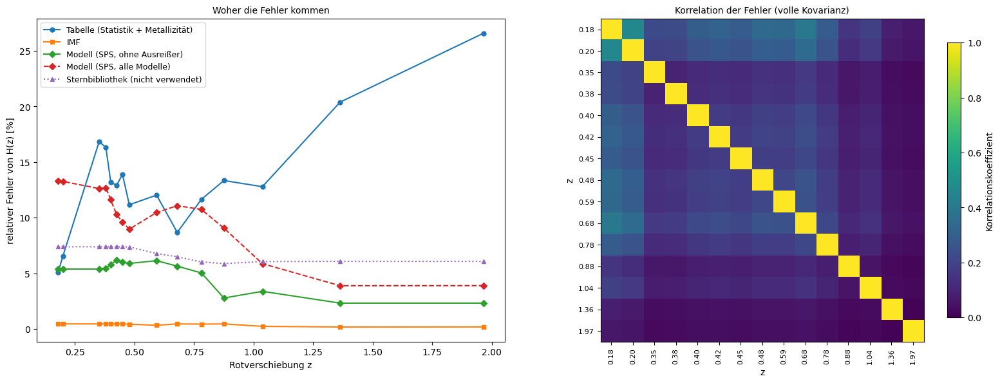

H/H_Planck gemittelt, nur Diagonale   : 1.005 ± 0.027
H/H_Planck gemittelt, volle Kovarianz : 1.008 ± 0.058
Korrelationen außerhalb der Diagonale: 0.01 bis 0.47, Median 0.13
mittlere relative Fehler: Tabelle 13.4 %, IMF 0.41 %, SPS 4.9 % (mit allen Modellen 9.8 %)


In [49]:
chronometers.error_budget()

**49. Wie genau muss die Uhr gehen?**

Das Alter des Universums bei jeder Rotverschiebung für H₀ = 67.36 und 73.04, und die Zeit, die zwischen z ± 0.05 vergeht.

Heute ist das Universum 13.8 oder 12.7 Gyr alt; die Galaxien bei z = 1.97 sind höchstens drei Milliarden Jahre alt. Zwischen z = 0.15 und 0.25 vergeht gut eine Milliarde Jahre, und die beiden H₀ unterscheiden sich darin um 85 Myr; bei z = 1.5 nur um 19 Myr. Die Uhr muss also auf wenige Prozent genau gehen.

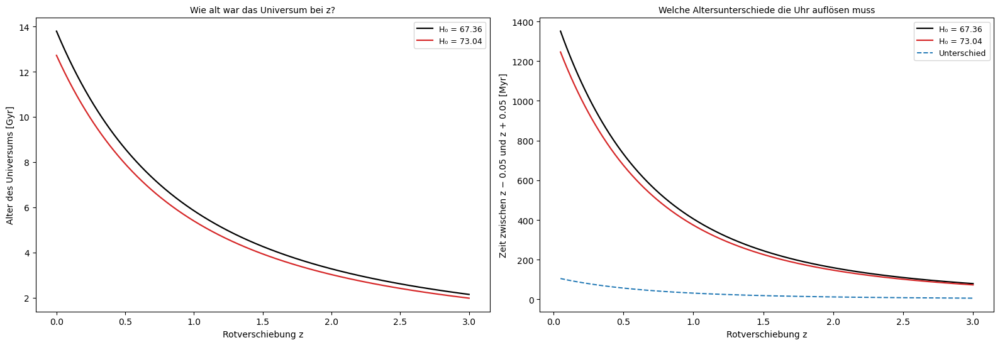

H₀ = 67.36: Alter heute 13.80 Gyr, bei z = 0.5 8.58 Gyr, bei z = 1.97 3.33 Gyr
H₀ = 73.04: Alter heute 12.72 Gyr, bei z = 0.5 7.92 Gyr, bei z = 1.97 3.07 Gyr
z = 0.2: Δt = 1092 Myr (Planck), 1007 Myr (73.04), Unterschied 85 Myr; 5 % von Δt sind 55 Myr
z = 0.5: Δt = 732 Myr (Planck), 675 Myr (73.04), Unterschied 57 Myr; 5 % von Δt sind 37 Myr
z = 1.0: Δt = 405 Myr (Planck), 374 Myr (73.04), Unterschied 32 Myr; 5 % von Δt sind 20 Myr
z = 1.5: Δt = 245 Myr (Planck), 226 Myr (73.04), Unterschied 19 Myr; 5 % von Δt sind 12 Myr


In [50]:
chronometers.clock_precision()

**50. H₀ und Ω_m aus den Uhren in ΛCDM**

H(z) in flachem ΛCDM an die 15 Messungen angepasst, mit voller Kovarianz und nur mit der Diagonale.

H₀ = 67.0 ± 5.5 und Ω_m = 0.34; Planck liegt 0.1σ, SH0ES 1.1σ entfernt. Die erlaubten Bereiche sind lange, schräge Ellipsen, weil sich H₀ und Ω_m ausgleichen. Ohne die Korrelationen fällt der Fehler auf ± 3.8, zu optimistisch.

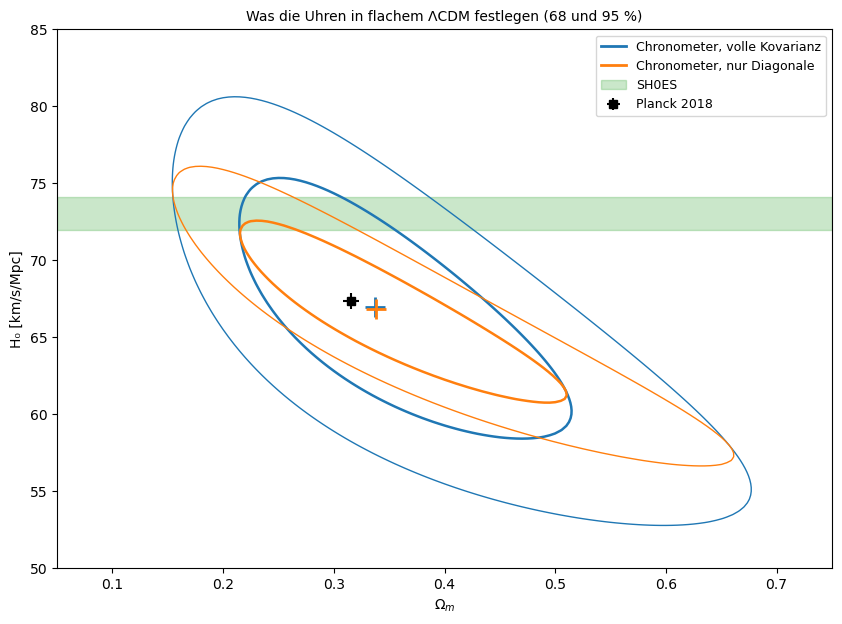

volle Kovarianz : H₀ = 66.99 (68 %: 61.5 bis 72.5, also ± 5.5), Ω_m = 0.337, χ² = 6.11 bei 13 Freiheitsgraden
nur Diagonale   : H₀ = 66.84 (68 %: 63.0 bis 70.5, also ± 3.8), Ω_m = 0.338, χ² = 6.11 bei 13 Freiheitsgraden
Abstand zu SH0ES: 1.1 σ, zu Planck: -0.1 σ


In [51]:
chronometers.lcdm_fit()

**51. H₀ ohne Modell: ein Gauß-Prozess**

Ein Gauß-Prozess legt eine glatte Kurve durch die Messungen, ohne ein kosmologisches Modell anzunehmen; seine Glattheit wird aus den Daten gewählt. Bei z = 0 gibt er H₀.

Die gewählte Kurve ist sehr glatt, fast eine Parabel. Ohne Modell ist H₀ = 64.3 ± 5.9, etwas unter dem ΛCDM-Fit, weil der Prozess ohne Vorwissen zu null hin gezogen wird. Bei z = 1 ist H = 120 ± 9 km/s/Mpc.

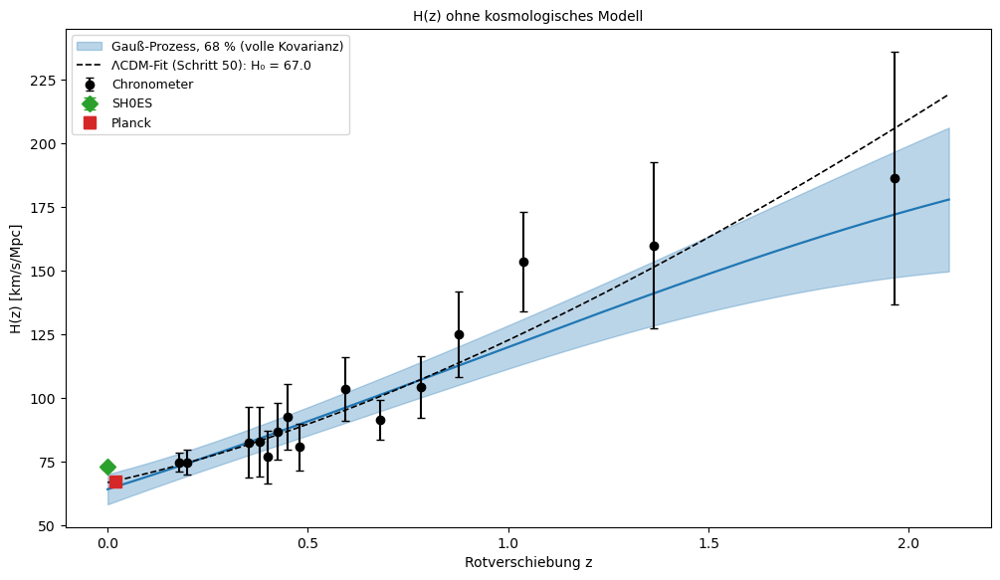

volle Kovarianz : σ_f = 143 km/s/Mpc, ℓ = 2.71; H₀ = 64.34 ± 5.93, H(1) = 120.2 ± 8.5
nur Diagonale   : σ_f = 143 km/s/Mpc, ℓ = 2.72; H₀ = 64.19 ± 4.68, H(1) = 119.9 ± 6.7


In [52]:
chronometers.gaussian_process()

**52. Wann die Beschleunigung begann**

Aus Stichproben des Gauß-Prozesses folgt der Verzögerungsparameter q(z); wo er das Vorzeichen wechselt, begann die Beschleunigung.

In ΛCDM ist q heute −0.5 und wird bei z ≈ 0.6 positiv. Der Gauß-Prozess lässt das offen: Nur 46 % seiner Stichproben wechseln das Vorzeichen, wenn, dann bei z = 0.6 (0.3 bis 0.9). Die Ableitung einer Kurve aus 15 verrauschten Punkten ist viel unsicherer als die Kurve selbst.

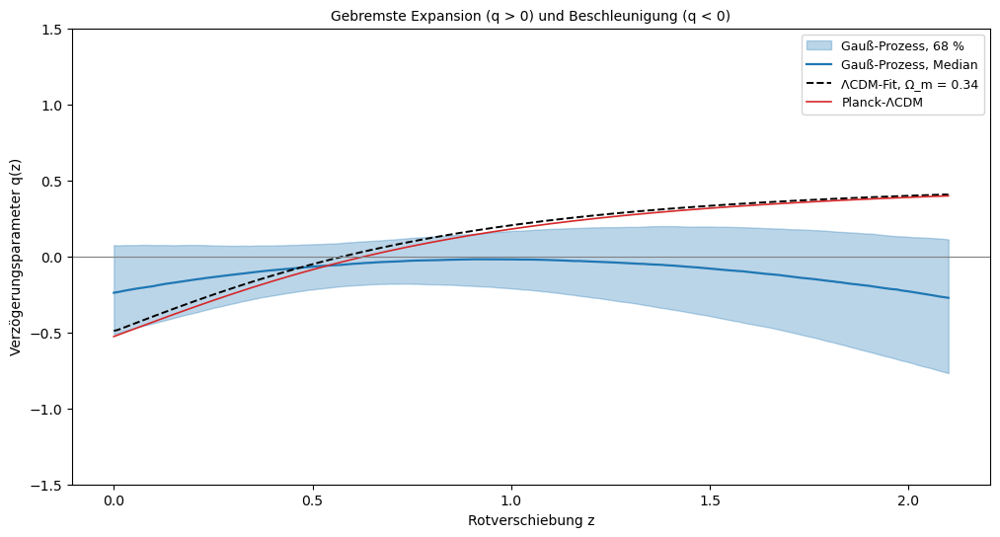

Gauß-Prozess: q₀ = -0.24 (-0.51 bis 0.07); Vorzeichenwechsel in 46 % der Stichproben, z_t = 0.60 (0.30 bis 0.90)
ΛCDM-Fit: Ω_m = 0.337 (0.253 bis 0.445), z_t = 0.58 (0.36 bis 0.81), q₀ = -0.49
Planck-ΛCDM: z_t = 0.63, q₀ = -0.53


In [53]:
chronometers.acceleration_onset()

**53. Die Uhr eicht das Lineal, Punkt für Punkt**

Die BAO messen D_H / r_d, die Uhr misst H(z) = c / D_H. Zusammen geben sie das Lineal r_d ohne die Physik des frühen Universums.

Fünf Stichproben von DESI geben r_d zwischen 146 und 158 Mpc, im Mittel 149 ± 9 Mpc: 0.2σ neben Planck (147.1) und 1.1σ über den 139 Mpc, die die BAO mit H₀ = 73 verlangen würden.

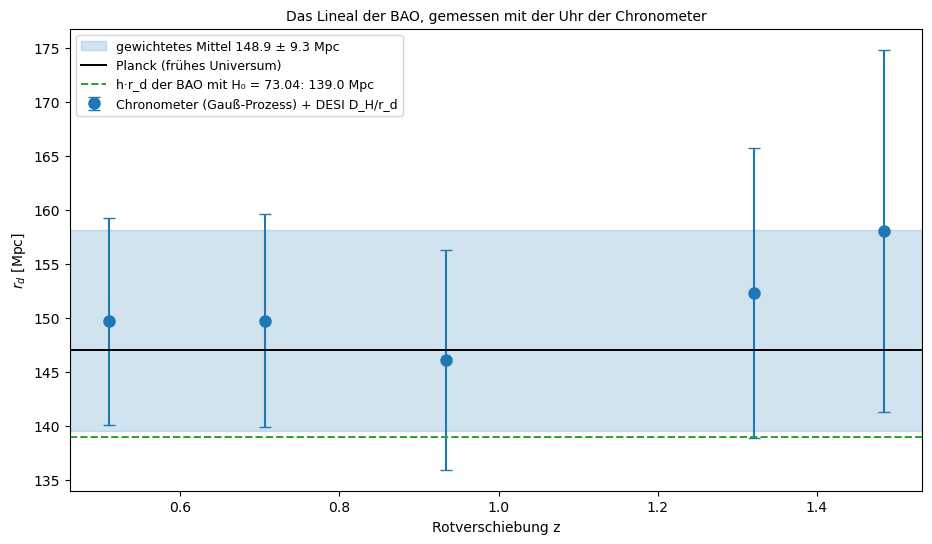

z = 0.510: H =   91.6 km/s/Mpc, r_d =  149.7 ±  9.6 Mpc
z = 0.706: H =  102.9 km/s/Mpc, r_d =  149.8 ±  9.9 Mpc
z = 0.934: H =  116.3 km/s/Mpc, r_d =  146.2 ± 10.2 Mpc
z = 1.321: H =  138.8 km/s/Mpc, r_d =  152.3 ± 13.4 Mpc
z = 1.484: H =  148.0 km/s/Mpc, r_d =  158.1 ± 16.8 Mpc
Mittel: r_d = 148.9 ± 9.3 Mpc; Planck 147.09 (+0.2 σ), mit H₀ = 73.04 nötig 139.0 (+1.1 σ)


In [54]:
chronometers.calibrate_ruler()

**54. Uhren und BAO zusammen in ΛCDM**

H₀, Ω_m und r_d gemeinsam an Uhren und BAO angepasst, und zusätzlich an die Form des Supernova-Diagramms.

Uhren und BAO geben r_d = 148 ± 8 Mpc und H₀ = 68.7 ± 3.9; die Supernovae ändern wenig, weil die BAO Ω_m schon festlegen. Der Wert liegt bei Planck und 1.1σ unter SH0ES.

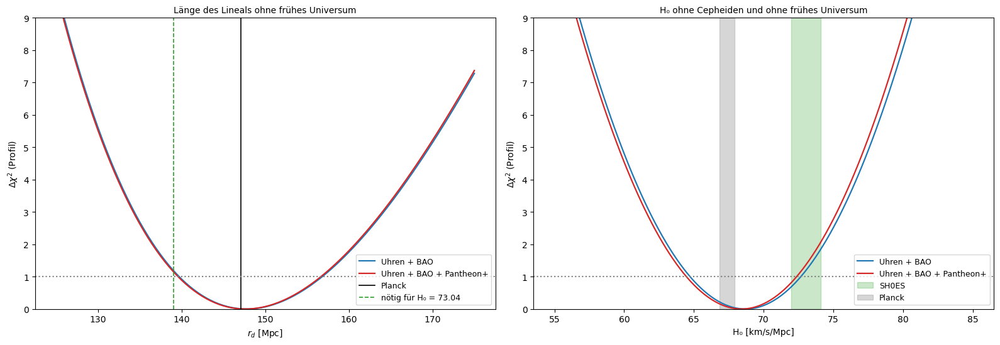

Uhren + BAO             : r_d = 147.8 (140.0 bis 156.5), H₀ = 68.70 (64.8 bis 72.5), Ω_m = 0.298, h r_d = 101.52, χ² = 16.6
Uhren + BAO + Pantheon+ : r_d = 147.6 (140.0 bis 156.5), H₀ = 68.41 (64.5 bis 72.2), Ω_m = 0.304, h r_d = 101.00, χ² = 1422.4
Uhren + BAO: r_d gegen Planck +0.1 σ, gegen das für H₀ = 73 nötige +1.1 σ


In [55]:
chronometers.with_bao()

**55. Die Uhr eicht die Kerzen**

Uhren und Supernovae zusammen: Die Supernovae legen die Form fest, die Uhren den Maßstab. Daraus folgt, wie hell eine Supernova sein muss (M_B), verglichen mit dem Wert aus Cepheiden.

H₀ = 67.2 ± 3.8 und M_B = −19.44 ± 0.12. Die Cepheiden geben −19.25: Mit der Uhr geeicht wären die Supernovae 0.19 mag heller, 1.5σ, genau so viel, wie die Lücke zwischen den beiden Entfernungsleitern verlangt.

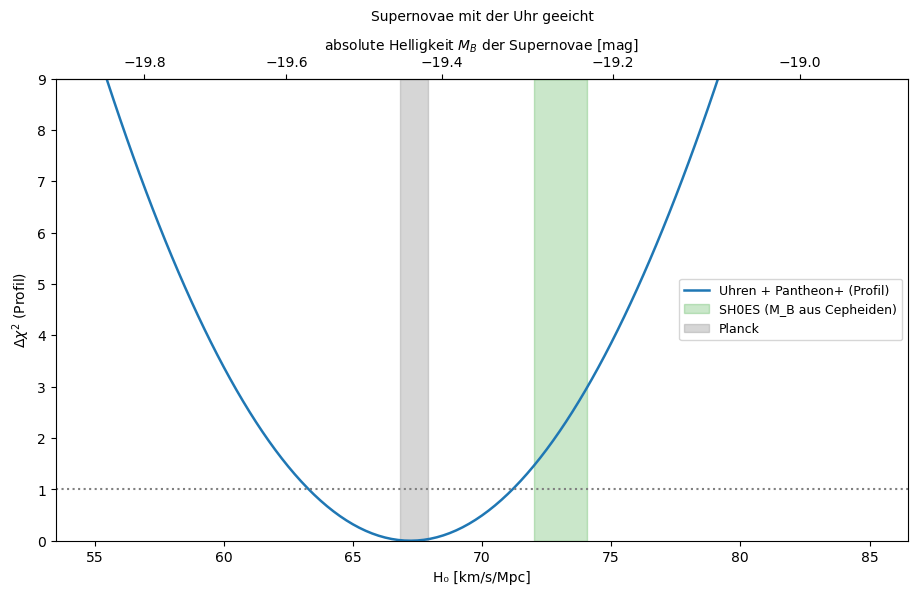

Uhren + Pantheon+: H₀ = 67.23 (63.5 bis 71.0), Ω_m = 0.332, χ² = 1409.0
M_B = -19.439 ± 0.121 mag; Cepheiden -19.249 ± 0.03 → Unterschied -0.190 mag (-1.5 σ)


In [56]:
chronometers.calibrate_candles()

**56. Gegen Planck, SH0ES und die anderen Wege**

Die eigenen Werte von H₀ und r_d neben Planck, SH0ES, DESI mit Nukleosynthese und Heavens, Jimenez und Verde (2014).

Alle eigenen H₀ liegen bei 64 bis 69, 0.0 bis 0.5σ von Planck und 1.1 bis 1.5σ von SH0ES; r_d liegt bei 148 bis 149 Mpc. Heavens et al. kamen mit älteren Daten ohne die korrelierten Modellfehler auf 142.8 ± 3.7 Mpc. Die Uhren bevorzugen Planck, aber ihre Fehler sind noch zu groß für eine Entscheidung.

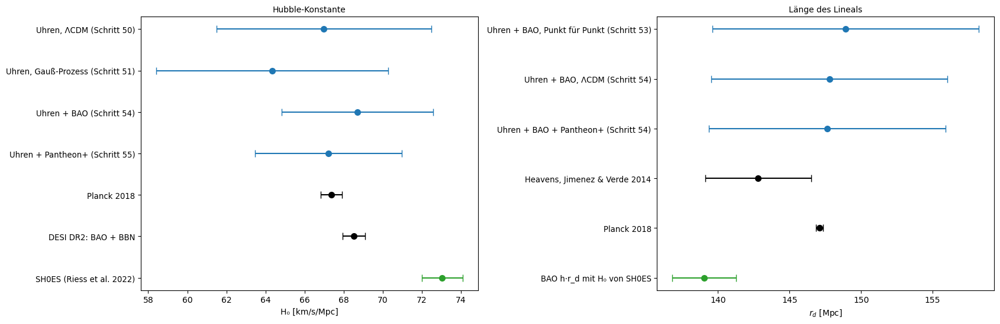

Uhren, ΛCDM (Schritt 50)          : H₀ = 66.99 ± 5.50; gegen Planck -0.1 σ, gegen SH0ES -1.1 σ
Uhren, Gauß-Prozess (Schritt 51)  : H₀ = 64.34 ± 5.93; gegen Planck -0.5 σ, gegen SH0ES -1.4 σ
Uhren + BAO (Schritt 54)          : H₀ = 68.70 ± 3.88; gegen Planck +0.3 σ, gegen SH0ES -1.1 σ
Uhren + Pantheon+ (Schritt 55)    : H₀ = 67.23 ± 3.75; gegen Planck -0.0 σ, gegen SH0ES -1.5 σ
Uhren + BAO, Punkt für Punkt (Schritt 53) : r_d = 148.9 ± 9.3 Mpc; gegen Planck +0.2 σ, gegen 139.0 Mpc +1.0 σ; Abstand der Hypothesen in eigenen Fehlern: 0.9
Uhren + BAO, ΛCDM (Schritt 54)            : r_d = 147.8 ± 8.2 Mpc; gegen Planck +0.1 σ, gegen 139.0 Mpc +1.0 σ; Abstand der Hypothesen in eigenen Fehlern: 1.0
Uhren + BAO + Pantheon+ (Schritt 54)      : r_d = 147.6 ± 8.2 Mpc; gegen Planck +0.1 σ, gegen 139.0 Mpc +1.0 σ; Abstand der Hypothesen in eigenen Fehlern: 1.0


In [57]:
chronometers.literature()

**57. Baryonische akustische Oszillationen**

Im heißen Plasma des frühen Universums lief um jede Überdichte eine Schallwelle nach außen, bis die Baryonen etwa 380 000 Jahre nach dem Urknall vom Licht frei kamen. Dann blieb eine Schale im Abstand r_d ≈ 147 Mpc stehen, aus der später Galaxien wuchsen: Paare von Galaxien im Abstand von 147 Mpc sind heute etwas häufiger. Das ist ein eingebautes Lineal. Geladen werden die 13 BAO-Messungen von DESI DR2 mit ihrer Kovarianz, Pantheon+ und eine komprimierte Likelihood der Hintergrundstrahlung.

DESI misst 13 Werte bei z = 0.3 bis 2.33. Die eigene Rechnung des Schallhorizonts trifft Planck genau (r_d = 147.09 Mpc).

In [58]:
bao.load()

DESI DR2: 13 Messwerte bei z = 0.295 bis 2.33; Arten: DV_over_rs 1, DM_over_rs 6, DH_over_rs 6
Pantheon+: 1590 Lichtkurven mit z > 0.01 (von 1701); CMB-Likelihood: 100 θ* = 1.041 ± 0.00026, ω_b = 0.02223 ± 0.00015, ω_cb = 0.14208 ± 0.0012
Eichfaktoren: z* × 0.99818, z_d × 1.0384
Planck-ΛCDM: r_d = 147.09 Mpc (Planck 147.09), r* = 144.43 Mpc (144.43), 100 θ* = 1.04110 (1.04110)


**58. Die Messungen von DESI DR2**

Die 13 Messwerte in Einheiten von r_d, quer zur Sichtlinie (D_M) und längs (D_H), mit den Kurven von Planck-ΛCDM; darunter jeder Wert geteilt durch die Vorhersage.

Die Fehler liegen zwischen 0.7 und 4 %. Die meisten Punkte liegen 1 bis 4 % unter Planck, am weitesten D_H bei z = 0.5 und 0.7. Kein Punkt weicht mehr als 2.6σ ab, aber insgesamt ist χ² = 30 bei 13 Werten: Planck-ΛCDM passt nicht gut.

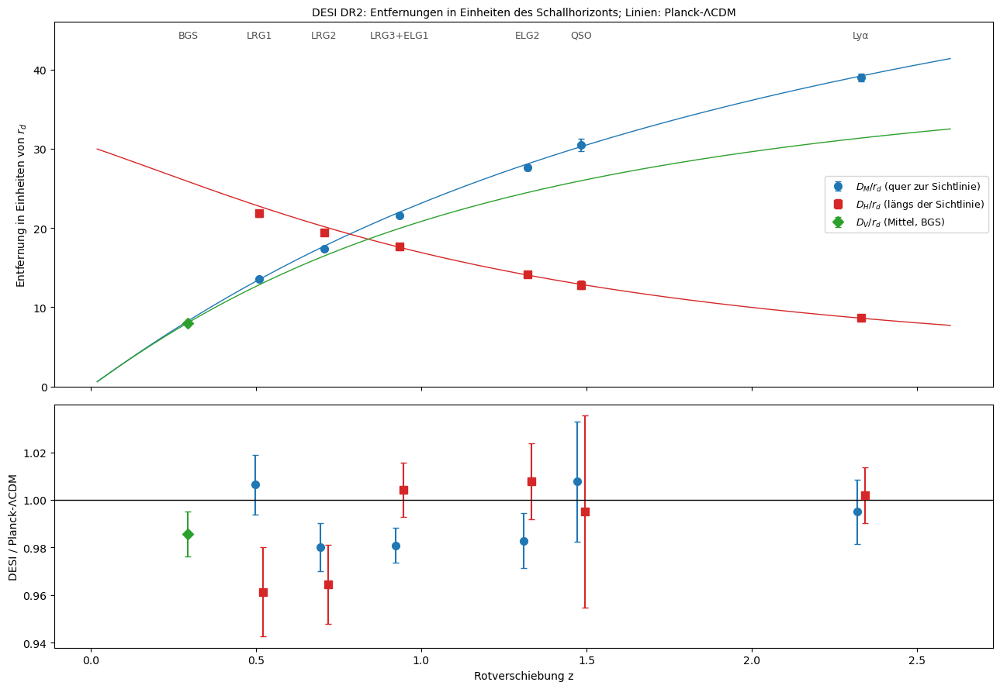

χ² gegen Planck-ΛCDM: 30.0 bei 13 Werten
BGS        z = 0.295: DV/r_d = 7.942 ± 0.076 (0.986)
LRG1       z = 0.510: DM/r_d = 13.588 ± 0.168 (1.006), DH/r_d = 21.863 ± 0.429 (0.961), Korrelation -0.45
LRG2       z = 0.706: DM/r_d = 17.351 ± 0.180 (0.980), DH/r_d = 19.455 ± 0.334 (0.965), Korrelation -0.40
LRG3+ELG1  z = 0.934: DM/r_d = 21.576 ± 0.162 (0.981), DH/r_d = 17.641 ± 0.201 (1.004), Korrelation -0.35
ELG2       z = 1.321: DM/r_d = 27.601 ± 0.325 (0.983), DH/r_d = 14.176 ± 0.225 (1.008), Korrelation -0.40
QSO        z = 1.484: DM/r_d = 30.512 ± 0.764 (1.008), DH/r_d = 12.817 ± 0.518 (0.995), Korrelation -0.49
Lyα        z = 2.330: DH/r_d = 8.632 ± 0.101 (1.002), DM/r_d = 38.989 ± 0.532 (0.995), Korrelation -0.43


In [59]:
bao.measurements()

**59. Alcock-Paczynski: die Form ohne Maßstab**

Das Verhältnis D_M / D_H hängt nicht vom Lineal r_d ab und nicht von H₀, nur von der Form der Expansion, also von Ω_m. Eine Kugel sieht nur im richtigen Modell rund aus.

Allein aus diesem Verhältnis folgt Ω_m = 0.298 ± 0.017, ohne Lineal und ohne H₀; Planck (0.315) liegt 1σ entfernt.

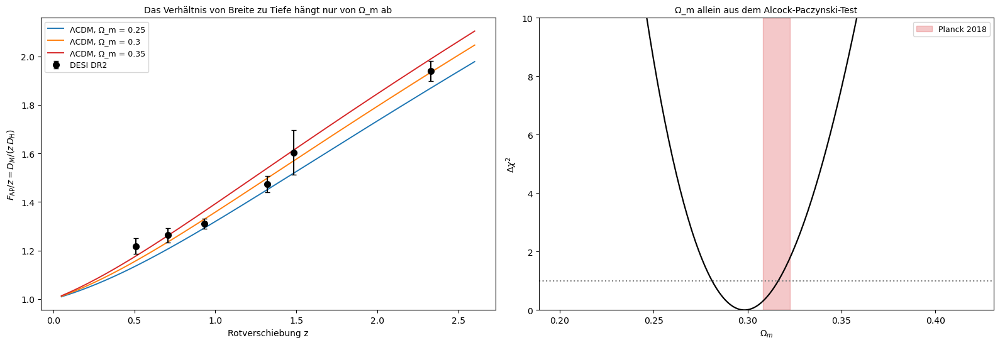

z = 0.510: F_AP = 0.6215 ± 0.0171 (2.8 %)
z = 0.706: F_AP = 0.8918 ± 0.0208 (2.3 %)
z = 0.934: F_AP = 1.2230 ± 0.0192 (1.6 %)
z = 1.321: F_AP = 1.9470 ± 0.0451 (2.3 %)
z = 1.484: F_AP = 2.3806 ± 0.1359 (5.7 %)
z = 2.330: F_AP = 4.5170 ± 0.0969 (2.1 %)
Ω_m = 0.298 ± 0.017, χ² = 5.86 bei 6 Werten und 1 Parameter


In [60]:
bao.alcock_paczynski()

**60. BAO und Supernovae im selben Diagramm**

Beide Messungen werden in Entfernungen in Mpc umgerechnet: die BAO mit r_d von Planck, die Supernovae mit der Helligkeit aus Cepheiden; alles geteilt durch Planck-ΛCDM.

Die beiden Leitern liegen um 8.9 % auseinander: die Supernovae bei 0.91, die BAO bei 0.99. Innerhalb jeder Leiter ist die Form fast flach. Die Hubble-Spannung ist also ein Unterschied in der Eichung der beiden Leitern, nicht in ihrer Form.

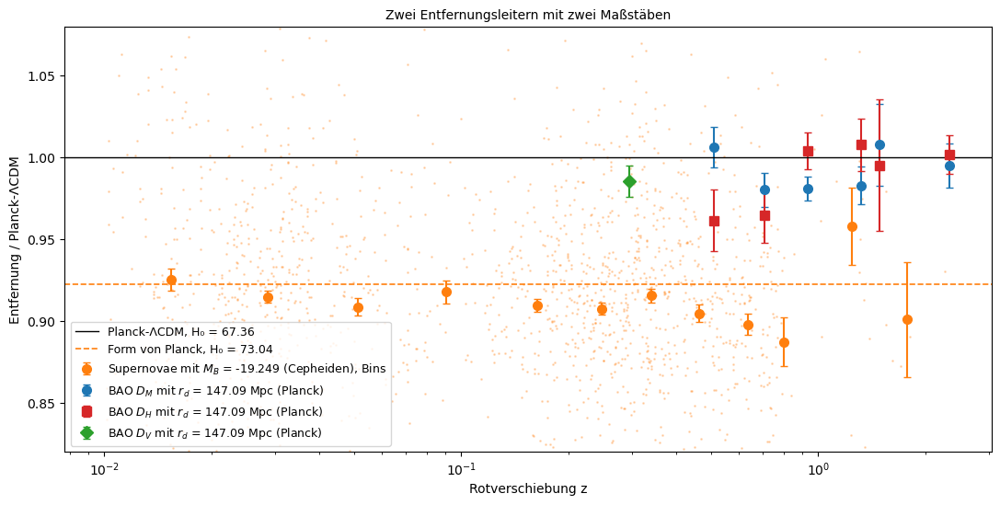

Supernovae, z > 0.1: mittleres Verhältnis 0.9083; BAO: 0.9887
Verhältnis der beiden Leitern: 1.0885; 67.36/73.04 = 0.9222


In [61]:
bao.bao_and_sne()

**61. Ω_m und h·r_d nur aus den BAO**

Alle 13 Werte hängen nur von Ω_m und dem Produkt h·r_d ab; beide werden angepasst.

Ω_m = 0.297 ± 0.009 und h·r_d = 101.6 ± 0.7 Mpc, genau wie bei DESI. Planck liegt knapp außerhalb der 95-%-Kontur.

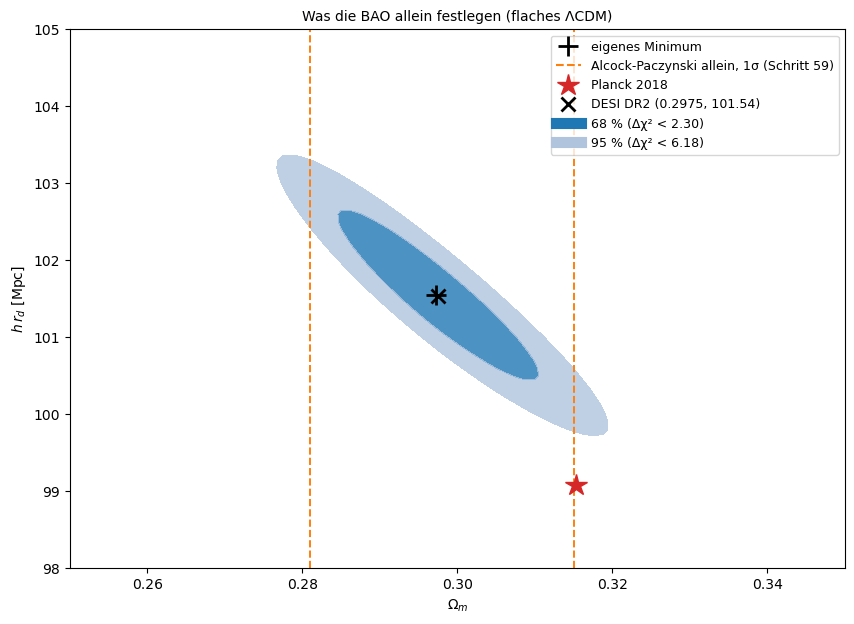

Ω_m = 0.2972 ± 0.0086, h r_d = 101.55 ± 0.74 Mpc, Korrelation -0.92, χ² = 10.28 bei 13 − 2 Freiheitsgraden
DESI DR2: Ω_m = 0.2975 ± 0.0086, h r_d = 101.54 ± 0.73 Mpc, Korrelation −0.92; Planck: h r_d = 99.08 Mpc


In [62]:
bao.omega_m_hrd()

**62. Der Schallhorizont r_d**

Der Schallhorizont als Integral der Schallgeschwindigkeit bis zur Rekombination (z⋆ ≈ 1090) und bis zum Ende des Zugs der Photonen an den Baryonen (z_d ≈ 1060), mit der Näherung von Aubourg et al. (2015) zum Vergleich.

r⋆ = 144.4 Mpc, r_d = 147.1 Mpc, 1.8 % mehr, weil die Baryonen nach der Entkopplung des Lichts noch kurz mitgezogen werden. Die Näherungsformel trifft das Integral auf 0.02 %. Mehr Materie und mehr Baryonen machen r_d kleiner.

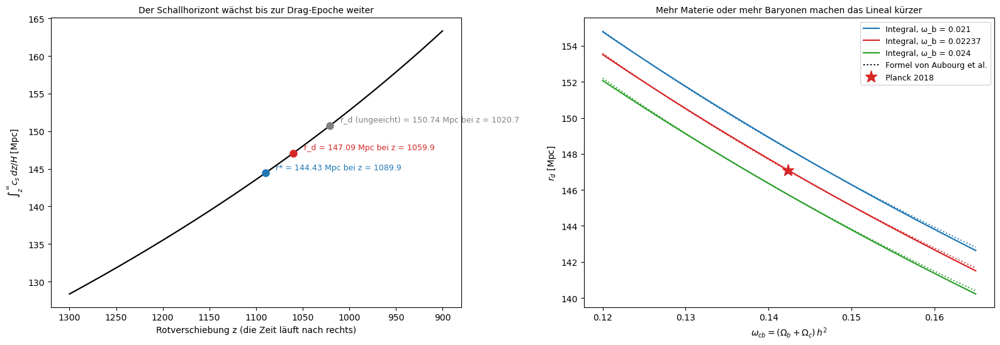

z* = 1089.92, z_d = 1059.94 (Näherung ungeeicht 1020.7); r* = 144.43 Mpc, r_d = 147.09 Mpc (+1.8 %)
r_d ungeeicht 150.74 Mpc (+2.5 %), Aubourg 147.06 Mpc, Planck 147.09
Empfindlichkeit: d ln r_d / d ln ω_cb = -0.257, d ln r_d / d ln ω_b = -0.130 (Aubourg: −0.254, −0.128)


In [63]:
bao.sound_horizon()

**63. Die inverse Entfernungsleiter**

BAO mit der Baryonendichte aus der Nukleosynthese (BBN) ergeben ein Lineal in Mpc und damit H₀, ohne Hintergrundstrahlung und ohne Cepheiden; zusätzlich mit dem Winkel des Schallhorizonts θ⋆ aus der Hintergrundstrahlung.

H₀ = 68.5 ± 0.6, mit θ⋆ 68.5 ± 0.5, wie bei DESI; der Abstand zu SH0ES ist 3.7 bis 4.0σ. Eine Leiter, die bei der Nukleosynthese beginnt, kommt nicht auf 73.

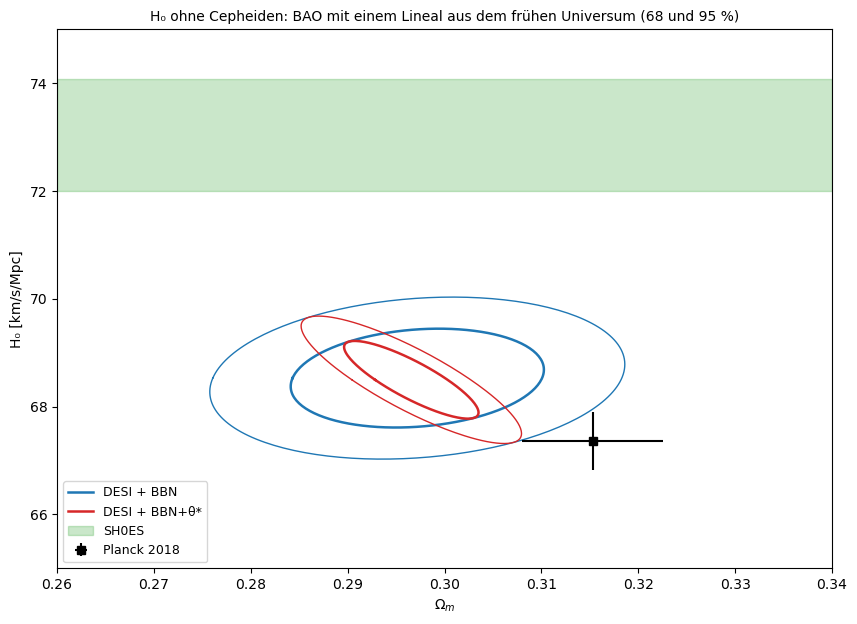

BAO+BBN    : H₀ = 68.53 ± 0.60, Ω_m = 0.2972 ± 0.0086, ω_b = 0.02218, r_d = 148.18 Mpc, χ² = 10.28; gegen SH0ES 3.7 σ
BAO+BBN+θ* : H₀ = 68.50 ± 0.48, Ω_m = 0.2966 ± 0.0046, ω_b = 0.02217, r_d = 148.30 Mpc, χ² = 10.29; gegen SH0ES 4.0 σ
DESI DR2: BAO+BBN 68.51 ± 0.58 (Ω_m 0.2977 ± 0.0086); BAO+BBN+θ* 68.45 ± 0.47 (Ω_m 0.2967 ± 0.0045)


In [64]:
bao.inverse_ladder()

**64. Der Buckel in der Verteilung der Galaxien**

Das Leistungsspektrum der Materie mit Baryonen, und daraus die Korrelationsfunktion, für drei Dichten der Baryonen.

Mit Baryonen schwingt das Spektrum mit der Periode 2π / r_d; die Wellen sind umso stärker, je mehr Baryonen es gibt, und werden zu kleinen Skalen gedämpft. In der Korrelationsfunktion wird daraus ein Buckel bei 149 Mpc (Planck) oder 140 Mpc (mehr Baryonen). Fast ohne Baryonen gibt es keinen Buckel.

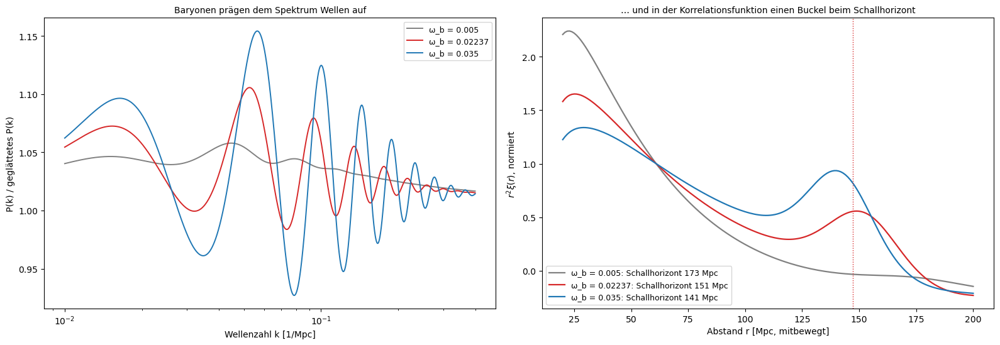

ω_b = 0.005: Schallhorizont nach Eisenstein & Hu 173.0 Mpc, Buckel von r²ξ bei 121 Mpc
ω_b = 0.02237: Schallhorizont nach Eisenstein & Hu 150.9 Mpc, Buckel von r²ξ bei 149 Mpc
ω_b = 0.035: Schallhorizont nach Eisenstein & Hu 141.3 Mpc, Buckel von r²ξ bei 140 Mpc
zum Vergleich r_d aus Schritt 62: 147.09 Mpc


In [65]:
bao.galaxy_bump()

**65. BAO gegen Hintergrundstrahlung in ΛCDM**

ΛCDM allein an die Hintergrundstrahlung angepasst, und die Vorhersage für Ω_m und h·r_d mit der Messung der BAO verglichen.

Die Hintergrundstrahlung legt eine sehr genaue Beziehung zwischen beiden fest, aber nicht jede einzeln, und gibt H₀ = 67.3 ± 0.6. Zu den BAO ist der Abstand 1.8σ; DESI findet mit der vollen Likelihood 2.3σ.

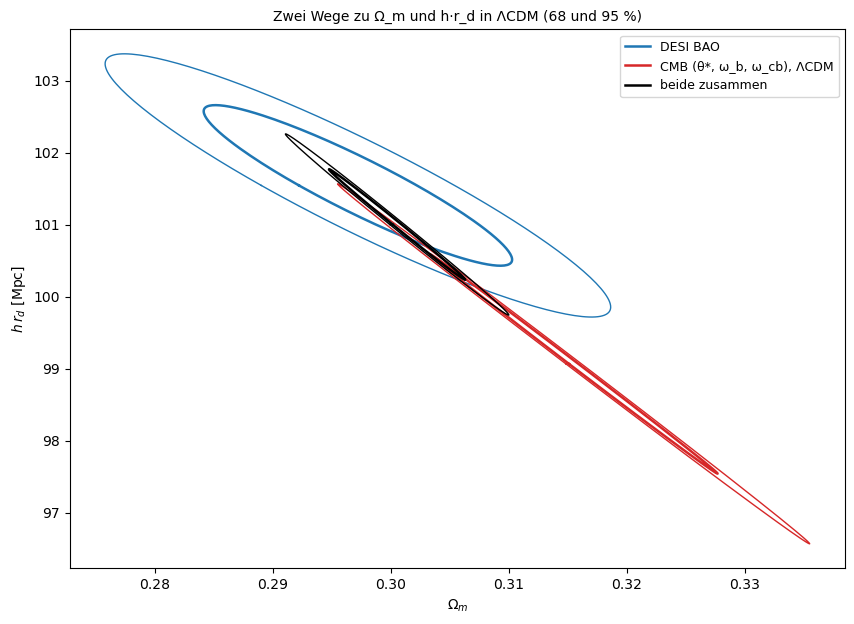

CMB allein: H₀ = 67.26 ± 0.58, Ω_m = 0.3155 ± 0.0080, h r_d = 99.07 ± 1.01
Abstand BAO – CMB: Δχ² = 5.11 bei 2 Freiheitsgraden → 1.8 σ (DESI mit voller CMB: 2.3 σ)
DESI + CMB: H₀ = 68.36 ± 0.30, Ω_m = 0.3005 ± 0.0038, χ² = 15.05 (DESI mit voller CMB: 68.17 ± 0.28, 0.3027 ± 0.0036)


In [66]:
bao.bao_vs_cmb()

**66. Drei Messungen von Ω_m**

Ω_m in flachem ΛCDM aus jeder Messung allein: Alcock-Paczynski, BAO, Hintergrundstrahlung und Supernovae.

0.298, 0.297, 0.316 und 0.331. Keine Spannung ist für sich groß (BAO gegen Supernovae 1.8σ), aber die BAO liegen allein am unteren Rand. Das ist der Ansatzpunkt für eine Dunkle Energie, die sich mit der Zeit ändert.

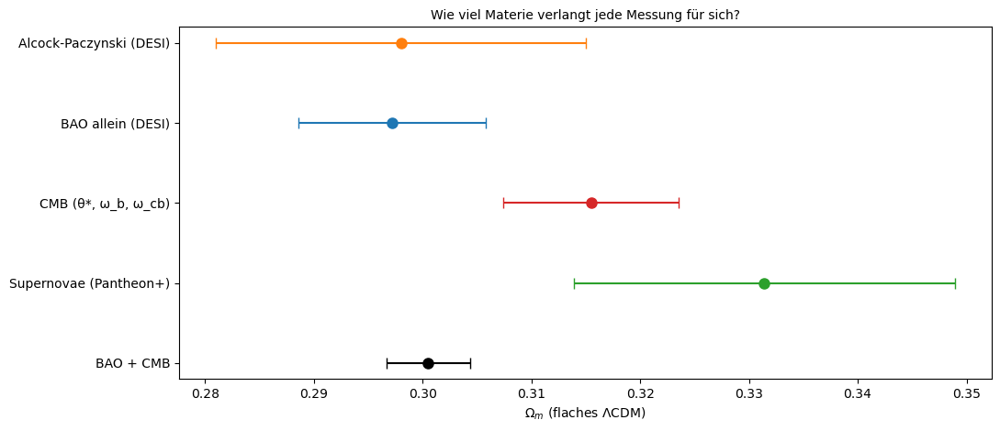

Alcock-Paczynski (DESI)   : Ω_m = 0.2980 ± 0.0170
BAO allein (DESI)         : Ω_m = 0.2972 ± 0.0086
CMB (θ*, ω_b, ω_cb)       : Ω_m = 0.3155 ± 0.0080
Supernovae (Pantheon+)    : Ω_m = 0.3314 ± 0.0175
BAO + CMB                 : Ω_m = 0.3005 ± 0.0038
BAO allein (DESI) gegen CMB (θ*, ω_b, ω_cb): 1.6 σ
BAO allein (DESI) gegen Supernovae (Pantheon+): 1.8 σ
CMB (θ*, ω_b, ω_cb) gegen Supernovae (Pantheon+): 0.8 σ
Supernovae: χ² = 1402.9 bei 1590 Lichtkurven; DESI Tabelle V: DESI 0.2975, CMB 0.3169; Pantheon+ (Brout et al. 2022): 0.334 ± 0.018


In [67]:
bao.three_omega_m()

**67. Dunkle Energie mit w₀ und w_a**

Statt einer kosmologischen Konstante (w = −1) eine Dunkle Energie, deren Zustandsgleichung sich ändert: w(a) = w₀ + w_a (1 − a). Verglichen wird das beste Modell mit ΛCDM für vier Kombinationen der Daten.

Das w₀w_a-Modell trifft die niedrigen D_H bei z = 0.5 und 0.7 besser. Es wird mit 1.7σ (DESI allein) bis 2.3σ (mit Hintergrundstrahlung) bevorzugt, wie bei DESI. Mit der vollen statt der komprimierten Likelihood wäre die Bevorzugung etwas stärker.

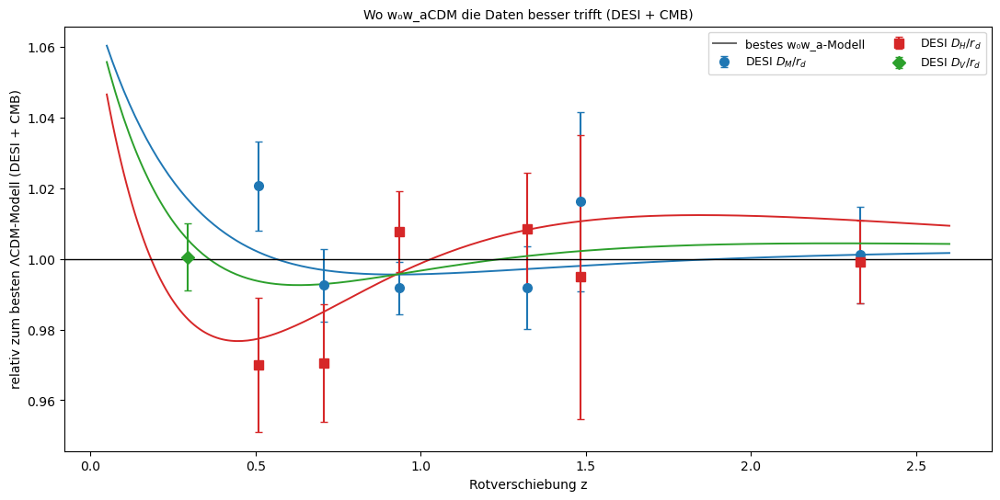

Kombination           χ²(ΛCDM)  χ²(w₀w_a)    Δχ²     σ     w₀      w_a     DESI Tab. VI
DESI                     10.28       5.62   -4.66   1.7  -0.180  -2.708     -4.7 (1.7 σ)
DESI+CMB                 15.05       7.12   -7.93   2.3  -0.448  -1.634     -8.0 (2.4 σ)
DESI+Pantheon+         1416.15    1411.27   -4.88   1.7  -0.890  -0.211     -4.9 (1.7 σ)
DESI+CMB+Pantheon+     1420.84    1413.33   -7.52   2.3  -0.854  -0.519     -10.7 (2.8 σ)
DESI Tab. VI mit voller CMB: DESI+CMB −12.5 (3.1 σ), DESI+CMB+Pantheon+ −10.7 (2.8 σ); DESI+(θ*, ω_b, ω_cb)CMB −8.0 (2.4 σ). Der Wert für DESI+CMB+Pantheon+ stammt aus der vollen CMB.


In [68]:
bao.w0wa()

**68. Welche Werte von w₀ und w_a erlaubt sind (MCMC)**

Eine Markov-Kette tastet die erlaubten Werte von w₀ und w_a ab, für DESI mit Hintergrundstrahlung und zusätzlich mit Supernovae.

Ohne Supernovae ist der Bereich ein langes Band, das an die Grenzen des Priors stößt (w₀ = −0.45 ± 0.22). Die Supernovae schneiden ein kleines Stück nahe ΛCDM heraus: w₀ = −0.85 ± 0.05, w_a = −0.55 ± 0.22, H₀ = 67.5. Das trifft die Werte von DESI.

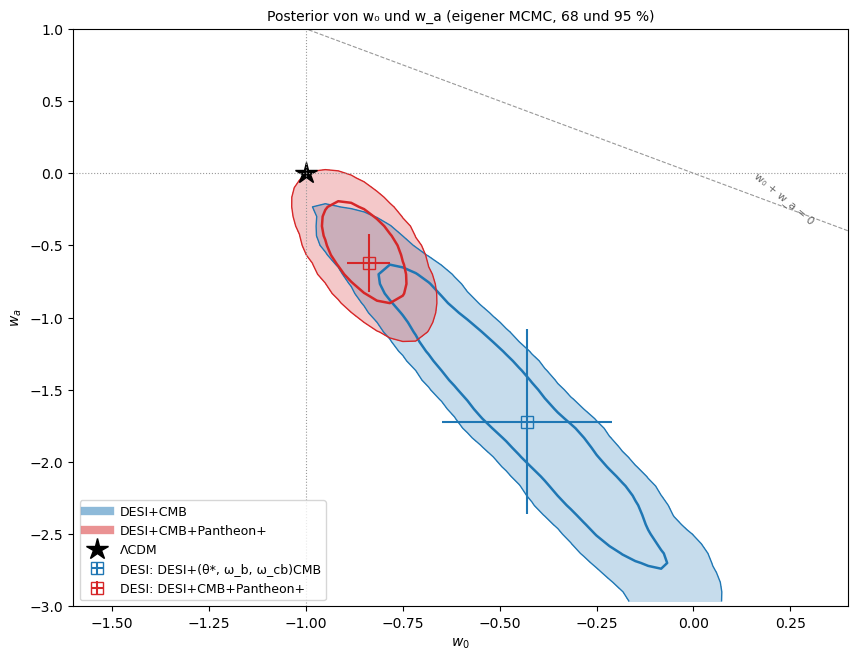

DESI+CMB: Akzeptanz 24 %, w₀ = -0.446 ± 0.223, w_a = -1.67 ± 0.64, H₀ = 63.87 ± 2.03, Ω_m = 0.3504 ± 0.0229; Anteil mit w₀ > −1 und w_a < 0: 99 %
DESI+CMB+Pantheon+: Akzeptanz 27 %, w₀ = -0.847 ± 0.054, w_a = -0.55 ± 0.22, H₀ = 67.47 ± 0.57, Ω_m = 0.3114 ± 0.0055; Anteil mit w₀ > −1 und w_a < 0: 100 %
DESI Tabelle V: DESI+(θ*, ω_b, ω_cb)CMB w₀ = −0.43 ± 0.22, w_a = −1.72 ± 0.64, Ω_m = 0.353 ± 0.022, H₀ = 63.7 +1.7/−2.2; DESI+CMB+Pantheon+ w₀ = −0.838 ± 0.055, w_a = −0.62 +0.22/−0.19, Ω_m = 0.3114 ± 0.0057, H₀ = 67.51 ± 0.59
Rechenzeit der Ketten: 26 s


In [69]:
bao.w0wa_mcmc()

**69. Was w₀ und w_a für die Dunkle Energie bedeuten**

Aus den Stichproben der Kette: w(z) und die Dichte der Dunklen Energie relativ zu heute.

Heute ist w ≈ −0.85, früher lag w unter −1. Die Kreuzung liegt bei z ≈ 0.4; dort hatte die Dichte der Dunklen Energie ihr Maximum, 7 % über heute, und fällt seither. Ein w unter −1 ist für einfache Modelle eines Feldes schwer zu erreichen; deshalb ist der Befund so umstritten.

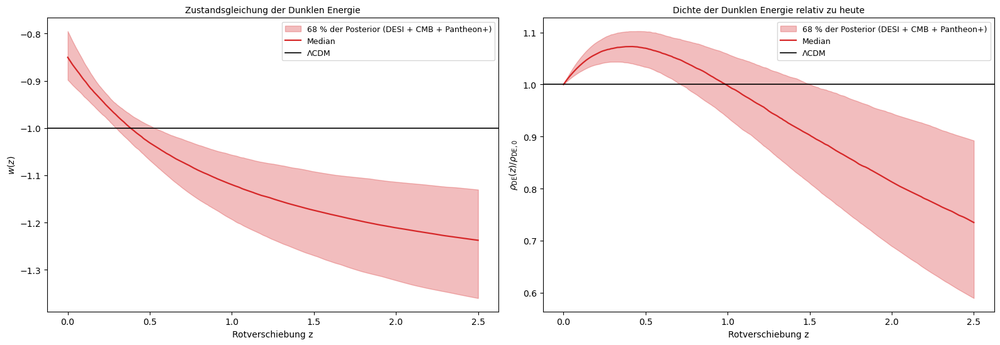

bestes Modell: w₀ = -0.854, w_a = -0.519; w = −1 bei z = 0.39; Maximum der Dichte bei z = 0.39 (1.071 × heute); früh (z = 2.5) w = -1.22
Kreuzung in den Stichproben: Median z = 0.38, 68 % zwischen 0.29 und 0.53
Dichte bei z = 0.5: 1.070 × heute (1.034 bis 1.102)


In [70]:
bao.w0wa_meaning()

**70. Gegen DESI DR2 und die Entfernungsleiter**

Die eigenen Ergebnisse neben den Tabellen von DESI DR2, Planck und SH0ES.

Die eigenen Werte von H₀ treffen DESI jeweils auf 0.2 km/s/Mpc; Ω_m und h·r_d stimmen fast exakt. Alle liegen zwischen 67.5 und 68.5, 3.7 bis 4.7σ unter SH0ES.

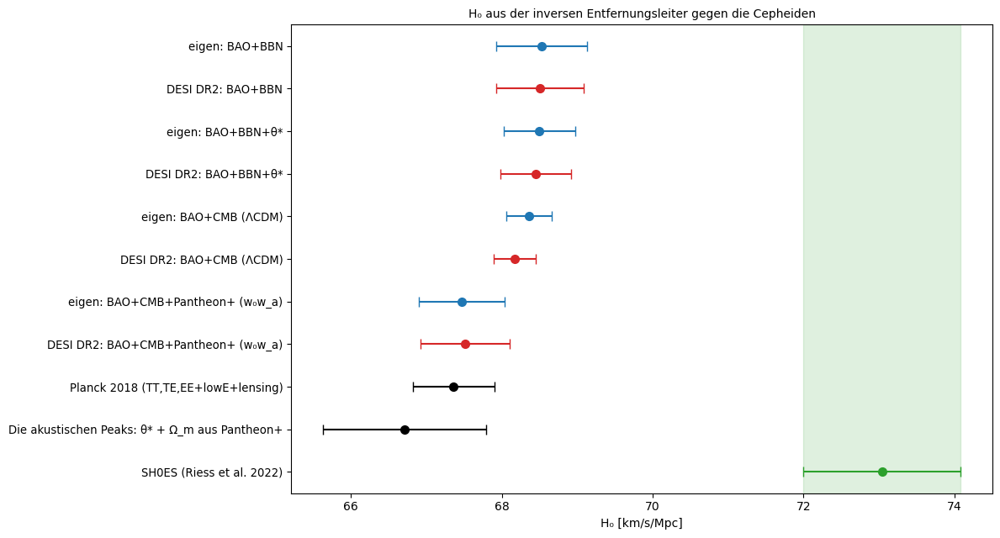

BAO allein:  Ω_m 0.2972 ± 0.0086 (DESI 0.2975 ± 0.0086), h r_d 101.55 ± 0.74 (101.54 ± 0.73)
BAO+BBN                     : H₀ = 68.53 ± 0.60 (DESI 68.51 ± 0.58), gegen SH0ES 3.7 σ
BAO+BBN+θ*                  : H₀ = 68.50 ± 0.48 (DESI 68.45 ± 0.47), gegen SH0ES 4.0 σ
BAO+CMB (ΛCDM)              : H₀ = 68.36 ± 0.30 (DESI 68.17 ± 0.28), gegen SH0ES 4.3 σ
BAO+CMB+Pantheon+ (w₀w_a)   : H₀ = 67.47 ± 0.57 (DESI 67.51 ± 0.59), gegen SH0ES 4.7 σ
DESI+CMB                    : w₀ = -0.446 ± 0.223, w_a = -1.67 ± 0.64
DESI+CMB+Pantheon+          : w₀ = -0.847 ± 0.054, w_a = -0.55 ± 0.22


In [71]:
bao.literature()

**71. Die akustischen Peaks der Hintergrundstrahlung**

Etwa 380 000 Jahre nach dem Urknall verbanden sich Elektronen und Protonen zu Wasserstoff, und das Licht lief seitdem frei; es erreicht uns, um den Faktor 1090 gedehnt, als Mikrowellenstrahlung von 2.7255 K. Ihre Temperatur schwankt um etwa 100 μK, ein Abbild der Dichteschwankungen von damals. Schallwellen im Plasma haben diesen Flecken bevorzugte Größen gegeben, die akustischen Peaks im Leistungsspektrum. Geladen werden das Spektrum von Planck 2018 mit dem besten Modell und vier Felder von 20° × 20° aus den Planck-Karten bei 100 und 143 GHz, fern der Milchstraße.

Das Spektrum reicht von ℓ = 2 bis 2508. Die vier Felder schwanken um 96 bis 113 μK; einige Lücken in den Karten sind gefüllt.

In [72]:
cmbpeaks.load()

Spektrum: ℓ = 2 bis 2508 (2507 Werte), 83 Bins, bestes Modell bis ℓ = 2508
Nordpol         (l, b) = (0, 90): 400×400 Pixel, Streuung 100 GHz 101.0 μK, 143 GHz 101.8 μK, gefüllte Lücken 384
Südpol          (l, b) = (0, -90): 400×400 Pixel, Streuung 100 GHz 100.8 μK, 143 GHz 101.6 μK, gefüllte Lücken 114
Nord, l = 150°  (l, b) = (150, 62): 400×400 Pixel, Streuung 100 GHz  96.3 μK, 143 GHz  97.6 μK, gefüllte Lücken 0
Süd, l = 210°   (l, b) = (210, -62): 400×400 Pixel, Streuung 100 GHz 112.9 μK, 143 GHz 112.9 μK, gefüllte Lücken 0
Dehnung der ARC-Projektion im Mittel über das Feld: 0.12 %
Mit den Planck-Werten: z* = 1091.91, r_s = 144.26 Mpc, D_M = 13873 Mpc, 100 θ* = 1.03983


**72. Ein Stück Himmel bei 100 und 143 GHz**

Das Feld am galaktischen Nordpol bei beiden Frequenzen und ihre halbe Differenz, alle mit derselben Farbskala.

Bei beiden Frequenzen sieht man dieselben warmen und kalten Flecken von etwa 1° und kleinere darin. Die Karten streuen um etwa 100 μK, die halbe Differenz nur um 10 bis 13 μK, und die Frequenzen sind zu 0.98 korreliert. Gleiche Stärke bei beiden Frequenzen ist das Kennzeichen der Hintergrundstrahlung; Rauschen oder Staub wären verschieden.

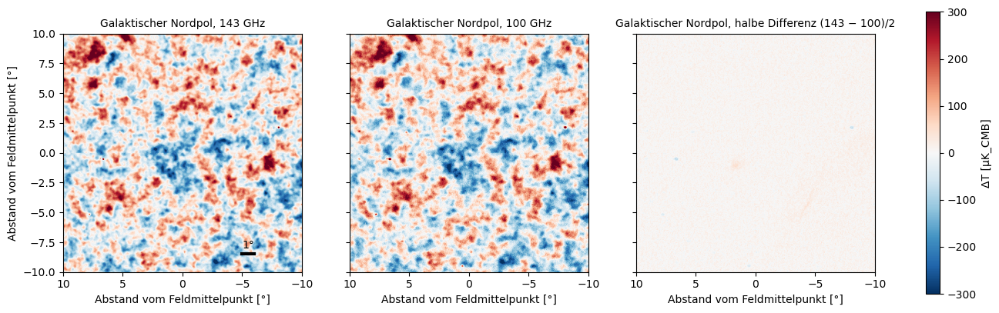

Nordpol        : Streuung 143 GHz 101.8 μK, 100 GHz 101.0 μK, halbe Differenz 11.2 μK, Korrelation 0.9756
Südpol         : Streuung 143 GHz 101.6 μK, 100 GHz 100.8 μK, halbe Differenz 11.1 μK, Korrelation 0.9761
Nord, l = 150° : Streuung 143 GHz  97.6 μK, 100 GHz  96.3 μK, halbe Differenz  9.8 μK, Korrelation 0.9797
Süd, l = 210°  : Streuung 143 GHz 112.9 μK, 100 GHz 112.9 μK, halbe Differenz 12.7 μK, Korrelation 0.9745


In [73]:
cmbpeaks.sky_patch()

**73. Das Leistungsspektrum von Planck**

Das Spektrum zerlegt die Karte in Wellen nach dem Multipol ℓ; ℓ ≈ 180° / Winkel. Gezeigt sind Planck für jedes ℓ, in Bins und das beste ΛCDM-Modell.

Der erste Peak liegt bei ℓ ≈ 220, Flecken von 0.8°; vier weitere folgen bis ℓ ≈ 1500, darüber der Dämpfungsschwanz. Das Modell mit sechs Parametern beschreibt 2500 Multipole im Rahmen der Fehler (χ²/N = 0.78).

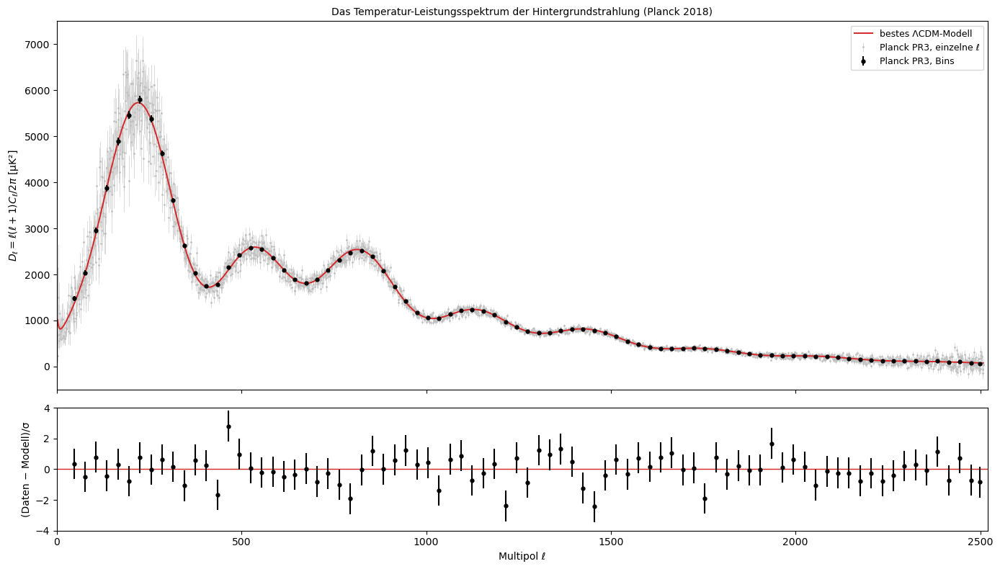

höchster Bin: ℓ = 225, D = 5793 μK²; das entspricht Flecken von etwa 0.80°
Quadrupol ℓ = 2: gemessen 226 (−132/+533) μK², Modell 1017 μK²
Bins gegen bestes Modell: χ² = 65.1 bei 83 Bins (χ²/N = 0.78)


In [74]:
cmbpeaks.planck_spectrum()

**74. Strahl, Pixel und Rauschen**

Das Teleskop verschmiert die Karte (Strahl), die Pixel ebenfalls; beides dämpft die Leistung bei großem ℓ. Gezeigt sind die Spektren des Feldes ohne und mit Korrektur und das Kreuzspektrum der beiden Frequenzen, dessen Rauschen sich heraushebt.

Bei ℓ = 2000 ist bei 100 GHz weniger als 1 % der Leistung übrig. Nach der Korrektur folgen die Spektren dem Modell bis ℓ ≈ 1000; darüber steigt das Rauschen in jeder einzelnen Karte über das Signal, nur das Kreuzspektrum bleibt brauchbar.

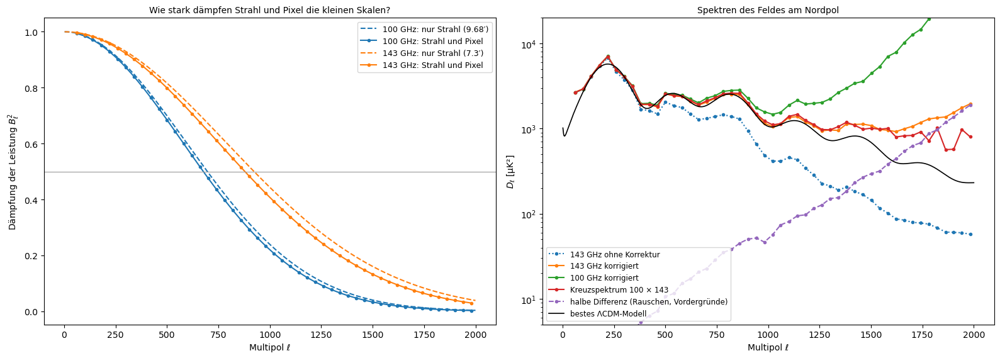

Strahl allein halbiert die Leistung bei ℓ = 696 (100 GHz) und ℓ = 923 (143 GHz)
ℓ ≈  501: 143 korrigiert   2560, Kreuz   2562, halbe Differenz     11, Modell  2451 μK²
ℓ ≈  982: 143 korrigiert   1152, Kreuz   1234, halbe Differenz     46, Modell  1126 μK²
ℓ ≈ 1502: 143 korrigiert   1083, Kreuz   1012, halbe Differenz    296, Modell   682 μK²
ℓ ≈ 1902: 143 korrigiert   1546, Kreuz    572, halbe Differenz   1369, Modell   251 μK²


In [75]:
cmbpeaks.beam_noise()

**75. Punktquellen**

Radiogalaxien erscheinen als helle Punkte und erhöhen die Leistung bei großem ℓ. Ein angepasster Filter sucht sie, und sie werden maskiert.

In den vier Feldern findet der Filter neun Quellen mit 290 bis 880 μK. Ohne sie fällt der Überschuss bei ℓ = 1900 von 2.00 auf 1.55: Die hellsten Quellen machen etwa 40 % aus. Den Rest erklären vermutlich schwächere Quellen unter der Schwelle und der infrarote Hintergrund staubiger Galaxien.

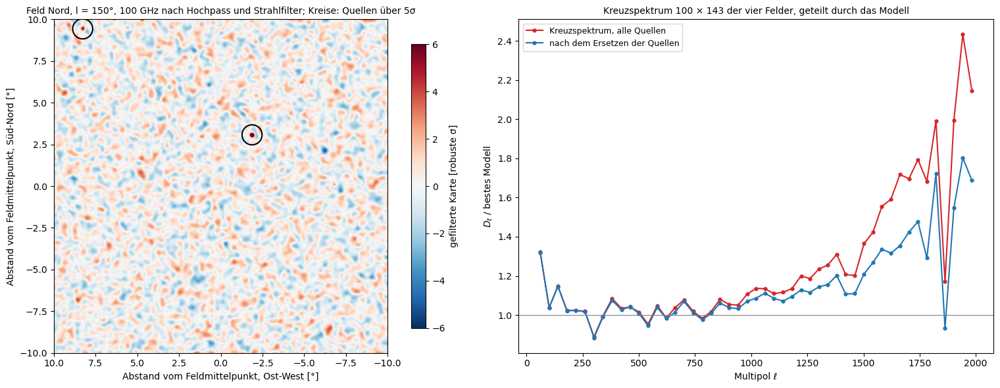

Nordpol        : 3 Quellen; Spitzen bei 100 / 143 GHz [μK]: 571/452, 584/477, 331/317
Südpol         : 3 Quellen; Spitzen bei 100 / 143 GHz [μK]: 468/413, 362/287, 481/543
Nord, l = 150° : 2 Quellen; Spitzen bei 100 / 143 GHz [μK]: 884/777, 333/312
Süd, l = 210°  : 1 Quellen; Spitzen bei 100 / 143 GHz [μK]: 412/444
ℓ ≈  501: Kreuzspektrum / Modell 1.02 mit Quellen, 1.01 ohne
ℓ ≈  982: Kreuzspektrum / Modell 1.11 mit Quellen, 1.07 ohne
ℓ ≈ 1502: Kreuzspektrum / Modell 1.36 mit Quellen, 1.21 ohne
ℓ ≈ 1902: Kreuzspektrum / Modell 2.00 mit Quellen, 1.55 ohne


In [76]:
cmbpeaks.point_sources()

**76. Kosmische Varianz und ein Test des Verfahrens**

Bei kleinem ℓ gibt es am ganzen Himmel nur wenige Wellen; das begrenzt jede Messung (kosmische Varianz). Dazu wird das Verfahren an 24 simulierten Feldern geprüft.

Bis ℓ ≈ 1000 begrenzt die kosmische Varianz auch Planck, darüber Rauschen und Strahl. Die Simulationen treffen das Eingangsspektrum ab ℓ = 400 auf 0.3 bis 0.6 %; darunter liegen sie 3 % zu hoch, weil das Feld kaum größer ist als die Wellen.

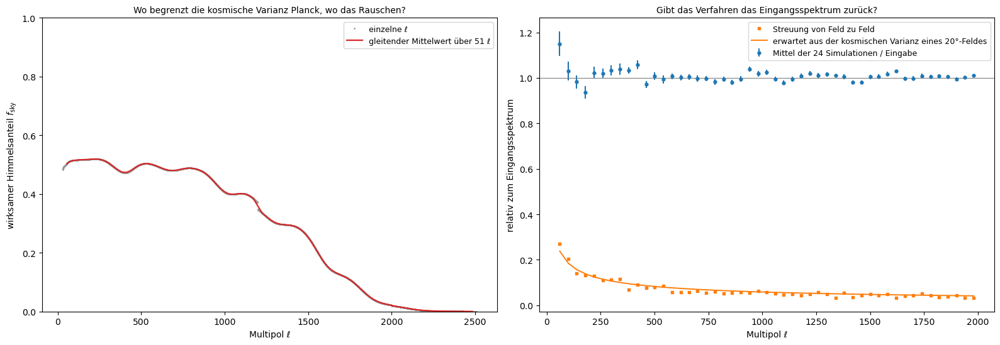

Planck ℓ =   30– 800: Fehler / kosmische Varianz  1.42, f_sky = 0.50
Planck ℓ =  800–1300: Fehler / kosmische Varianz  1.58, f_sky = 0.40
Planck ℓ = 1300–1800: Fehler / kosmische Varianz  2.19, f_sky = 0.21
Planck ℓ = 1800–2508: Fehler / kosmische Varianz 13.04, f_sky = 0.01
Simulationen ℓ =   40– 400: Mittel/Eingabe 1.027 ± 0.011, Streuung/erwartet 1.00
Simulationen ℓ =  400–1200: Mittel/Eingabe 1.003 ± 0.003, Streuung/erwartet 0.89
Simulationen ℓ = 1200–2000: Mittel/Eingabe 1.006 ± 0.002, Streuung/erwartet 0.92
wirksamer Himmelsanteil eines Feldes: 0.0073


In [77]:
cmbpeaks.cosmic_variance()

**77. Das eigene Spektrum aus vier Feldern**

Das Kreuzspektrum der vier Felder ohne die Quellen, angepasst mit dem Modell von Planck, das um einen Faktor α in ℓ verschoben werden darf, plus einem Term für Punktquellen.

Die ersten drei Peaks sind deutlich zu sehen. Die Eichung stimmt mit Planck auf 1 %, und die Verschiebung ergibt den Winkel des Schallhorizonts 100 θ⋆ = 1.0434 ± 0.0029, aus nur 3 % des Himmels und 0.8σ neben Planck.

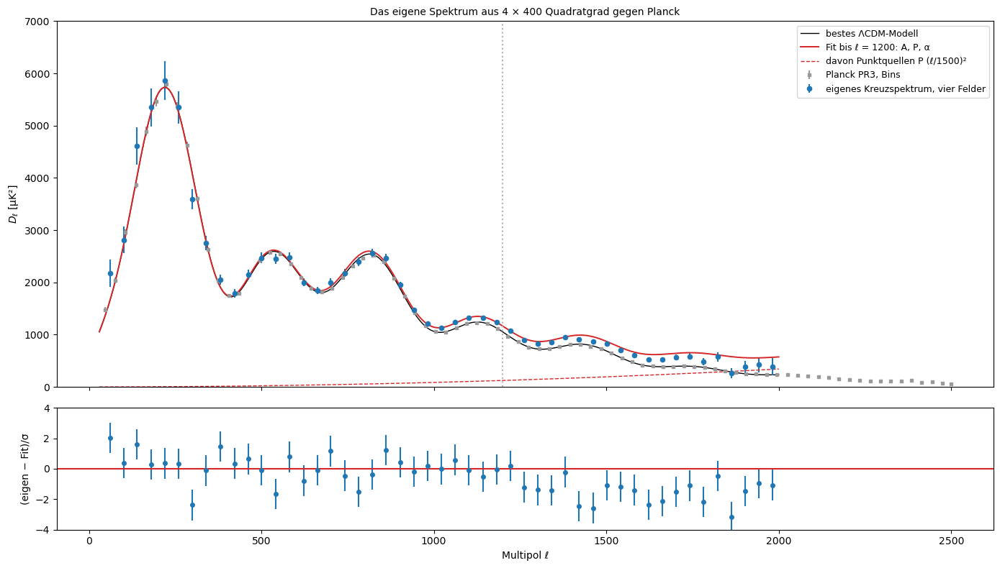

Fit bis ℓ = 1200: A = 1.000 ± 0.012, P = 193 ± 42 μK², α = 1.0022 ± 0.0027; χ² = 25.7 bei 26 Freiheitsgraden
eigenes 100 θ* = 1.0434 ± 0.0029 (Planck 1.04110)
  α = 1 fest        : A = 0.998, P =  188, α = 1.0000 ± 0.0000, χ² = 26.4 bei 27
  ohne Punktquellen : A = 1.038, P =    0, α = 1.0007 ± 0.0026, χ² = 46.4 bei 27
  bis ℓ = 2000      : A = 1.014, P =  123, α = 1.0012 ± 0.0022, χ² = 40.8 bei 46


In [78]:
cmbpeaks.own_spectrum()

**78. Lage und Höhe der Peaks**

Kubische Fits um jeden Peak und jedes Tal des Planck-Spektrums.

Die Peaks liegen bei ℓ = 221, 534, 815, 1122 und 1417, auf ±2 bis ±3.5 genau, wie im Modell; auch die Höhen stimmen auf weniger als 1 %. Der sechste Peak bei ℓ ≈ 1720 liegt schon im steil fallenden Dämpfungsschwanz und lässt sich nicht genau bestimmen.

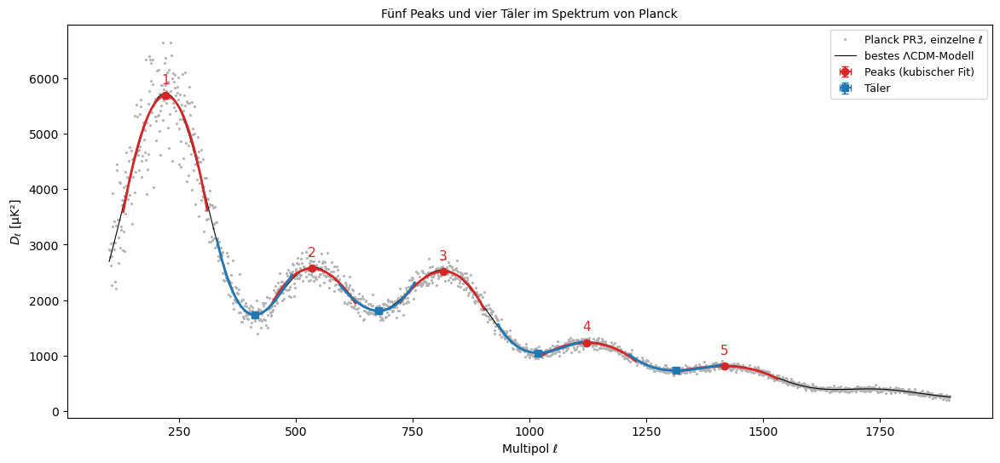

 Nr.   ℓ (Planck)      ℓ (Modell)   D (Planck) [μK²]   D (Modell)
Peak 1:   221.0 ±  3.3     219.6       5691 ±  55       5677
Peak 2:   534.0 ±  3.3     536.3       2571 ±  18       2567
Peak 3:   815.3 ±  2.8     812.7       2519 ±  14       2525
Peak 4:  1122.1 ±  3.1    1126.2       1230 ±   6       1229
Peak 5:  1416.7 ±  3.5    1421.1        807 ±   4        810
Tal  1:   411.8 ±  2.0     411.4       1736 ±  16       1735
Tal  2:   677.2 ±  3.0     673.5       1807 ±  12       1815
Tal  3:  1017.5 ±  2.1    1018.3       1049 ±   6       1049
Tal  4:  1313.7 ±  3.1    1314.9        729 ±   4        726
H2 = 0.4518 ± 0.0055 (Modell 0.4521),  H3 = 0.4425 ± 0.0051 (Modell 0.4447)


In [79]:
cmbpeaks.peaks()

**79. Der Abstand der Peaks**

Die Peaks liegen ungefähr bei ℓ_n = ℓ_A (n − φ); der Abstand ℓ_A = π / θ⋆ misst den Winkel des Schallhorizonts.

ℓ_A = 298. Die Peaks liegen fast gleichmäßig, aber mit einem Zickzack, das auch das Modell zeigt; roh macht das θ⋆ um 1.3 % zu groß. Am Modell geeicht bleibt 100 θ⋆ = 1.0458 ± 0.0038, 1.2σ über Planck.

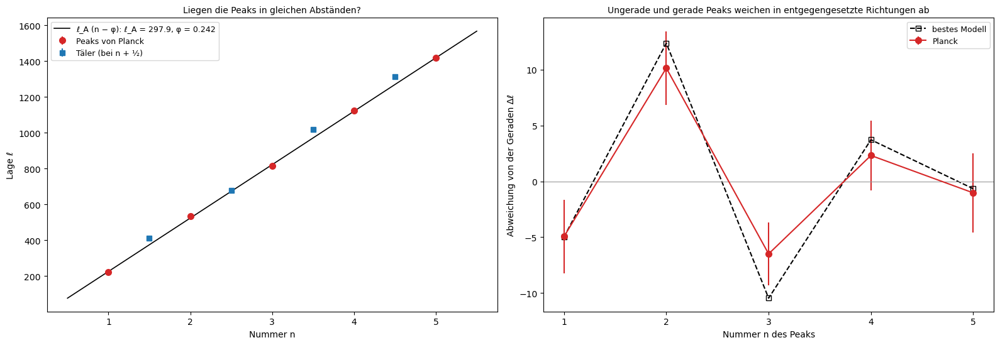

Planck: ℓ_A = 297.95 ± 1.08, φ = 0.242;  bestes Modell: ℓ_A = 299.28, φ = 0.249;  Hu et al.: φ ≈ 0.269
100 θ* roh π/ℓ_A = 1.0544 (das sind 0.604°); geeicht = 1.0458 ± 0.0038 (Planck 1.04110)
für das beste Modell gibt π/ℓ_A 100 θ* = 1.0497 statt 1.04110: Fehler der Geraden +0.83 %


In [80]:
cmbpeaks.peak_spacing()

**80. Der Schallhorizont**

Wie weit eine Schallwelle bis zur Rekombination laufen konnte, aus der Schallgeschwindigkeit im Plasma; sie sinkt, je mehr Baryonen das Plasma beschweren.

Früh ist die Schallgeschwindigkeit c/√3, bei der Rekombination nur noch 0.45 c. Der Schallhorizont wächst auf 144.3 Mpc; mit der Entfernung zur letzten Streuung (13 873 Mpc) folgt 100 θ⋆ = 1.0398, 0.12 % neben Planck.

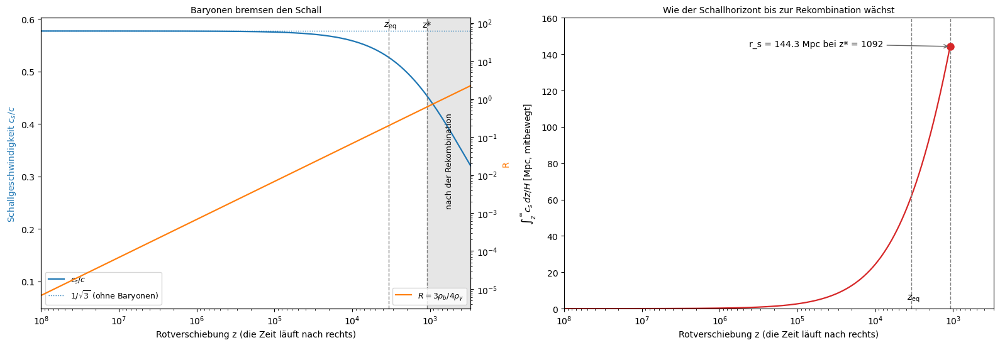

z* = 1091.91 (Näherung) gegen 1089.92 (Planck); z_eq = 3417; bei z*: R = 0.622, c_s = 0.453 c
r_s = 144.26 Mpc (Planck 144.43 ± 0.26), D_M = 13873 Mpc, 100 θ* = 1.03983 (Planck 1.0411)
mit z* von Planck: r_s = 144.43 Mpc, 100 θ* = 1.04110
ohne Baryonen in c_s: r_s = 161.7 Mpc (+12 %); vor z_eq entstanden 43 % von r_s


In [81]:
cmbpeaks.sound_horizon()

**81. Die Schablone: θ⋆ aus dem ganzen Spektrum**

Ändert sich θ⋆, rücken alle Peaks gemeinsam in ℓ. Das beste Modell wird als Schablone verschoben und an das ganze Spektrum angepasst, für drei Bereiche von ℓ.

100 θ⋆ = 1.04116 ± 0.00045, auf 0.04 % genau und 0.3σ neben Planck. Ganz unabhängig ist das nicht, weil die Schablone das beste Modell ist; der Fit prüft nur, ob das Spektrum gegen das Modell verschoben ist.

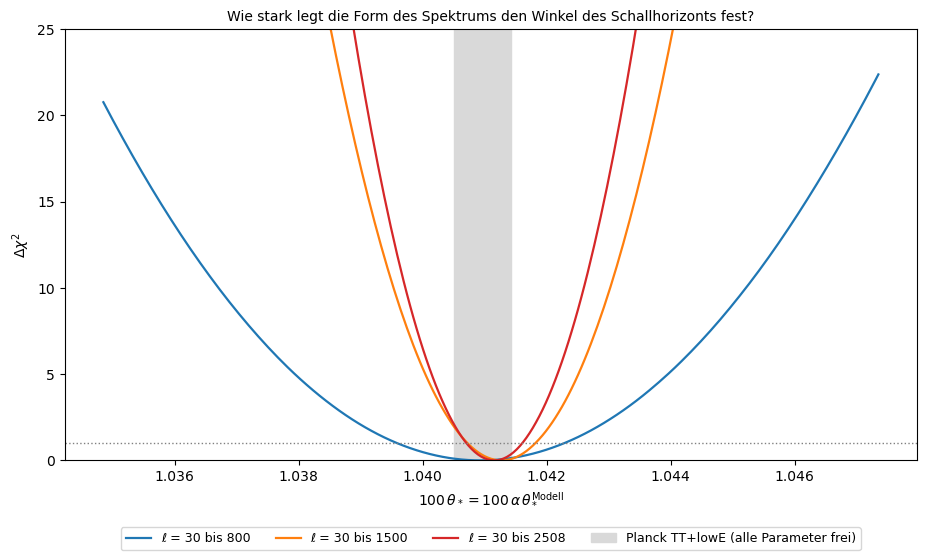

ℓ bis  800: α = 0.99984 ± 0.00130, 100 θ* = 1.04093 ± 0.00135, A = 0.9991, χ² = 845 bei 771 Werten
ℓ bis 1500: α = 1.00016 ± 0.00053, 100 θ* = 1.04127 ± 0.00055, A = 0.9998, χ² = 1560 bei 1471 Werten
ℓ bis 2508: α = 1.00005 ± 0.00043, 100 θ* = 1.04116 ± 0.00045, A = 1.0000, χ² = 2550 bei 2479 Werten
Planck TT+lowE: 100 θ* = 1.04097 ± 0.00046; Abstand +0.3 σ


In [82]:
cmbpeaks.template()

**82. Baryonen und Materie aus den Peakhöhen**

Mehr Baryonen machen den ersten Peak höher als den zweiten, mehr Materie hebt den dritten. Die Formeln von Hu et al. (2001) werden nach der Dichte der Baryonen und der Materie aufgelöst.

ω_b = 0.0229 ± 0.0007 und ω_m = 0.140 ± 0.003, 0.8σ und 1.0σ neben Planck. Die Formeln selbst sind nur auf einige Prozent genau und kennen den Spektralindex nicht genau; das ist hier der größte Fehler.

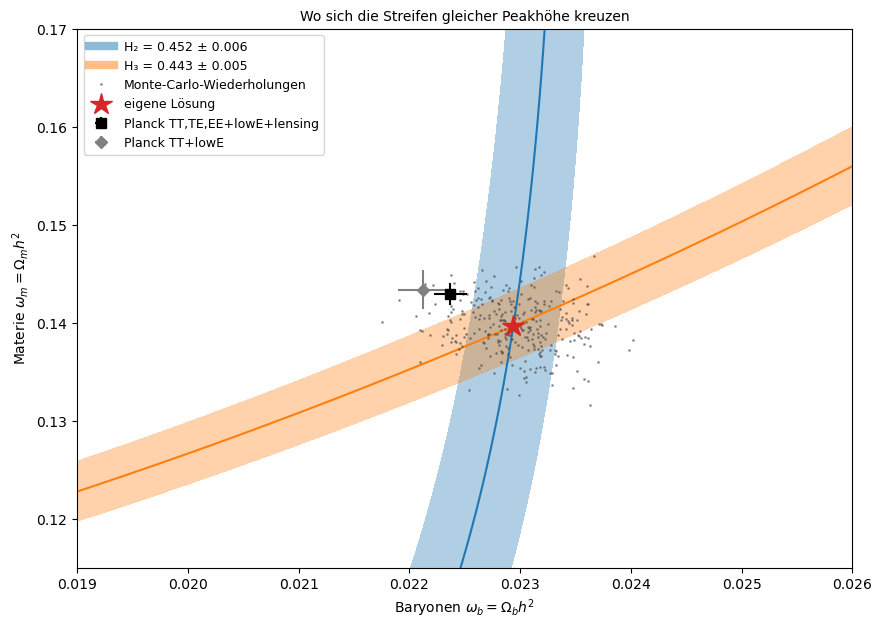

Formeln am besten Modell: H₂ um +1.8 %, H₃ um +1.5 % daneben
ω_b = 0.02294 ± 0.00039 (stat.) ± 0.00057 (Formel), Planck 0.02237
ω_m = 0.1397 ± 0.0027 (stat.) ± 0.0018 (Formel), Planck 0.143
mit n_s = 0.955: ω_b = 0.02269, ω_m = 0.1424
mit n_s = 0.975: ω_b = 0.02319, ω_m = 0.1370


In [83]:
cmbpeaks.baryons_matter()

**83. H₀ aus dem Winkel des Schallhorizonts**

θ⋆ = Schallhorizont / Entfernung; bei bekannten Dichten hängt die Entfernung nur noch an H₀. Gesucht ist das H₀, das den gemessenen Winkel trifft, mit Dichten von Planck, aus den eigenen Peakhöhen oder mit Ω_m aus Supernovae.

Mit den Dichten von Planck folgt 67.8, mit den eigenen 69.7 ± 1.7, mit Ω_m aus Pantheon+ 66.7 ± 1.1. Für 73 müsste θ⋆ 1.5 % größer sein als gemessen.

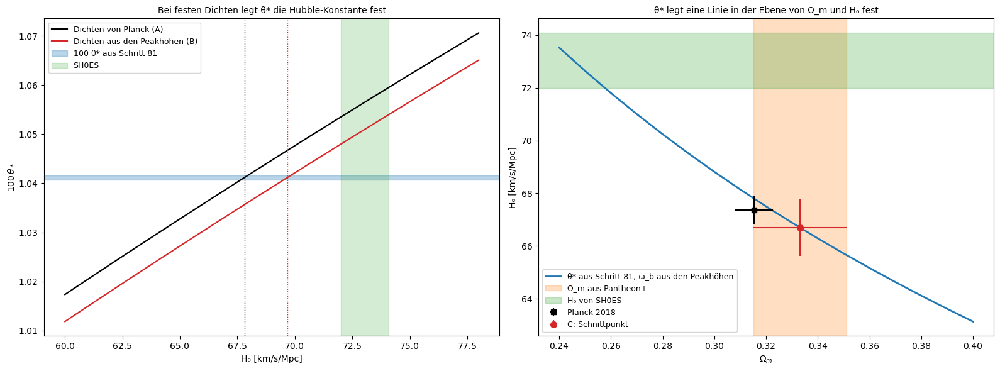

A (Dichten von Planck):       H₀ = 67.80 km/s/Mpc  (Planck selbst 67.36 ± 0.54)
B (Dichten aus Peakhöhen):    H₀ = 69.67 ± 1.03 (stat.) ± 1.32 (Formel)
C (ω_b, Ω_m aus Pantheon+):   H₀ = 66.71 ± 1.08
Ω_m h³ entlang der Linie: 0.0954 bis 0.1007 (Planck 0.0963)
mit dem z* von Planck statt der Näherung, Dichten von Planck: H₀ = 67.38


In [84]:
cmbpeaks.h0_cmb()

**84. Gegen Planck 2018 und SH0ES**

Die eigenen Werte von θ⋆, Schallhorizont, Dichten und H₀ neben Planck 2018 und der Entfernungsleiter.

Alle eigenen H₀ liegen zwischen 66.7 und 70.4, unter dem Band von SH0ES. θ⋆ stimmt aus der Schablone mit Planck überein, aus den eigenen Karten auf 0.8σ und aus dem Abstand der Peaks auf 1.2σ; die Dichten liegen 0.8σ und 1.0σ neben Planck.

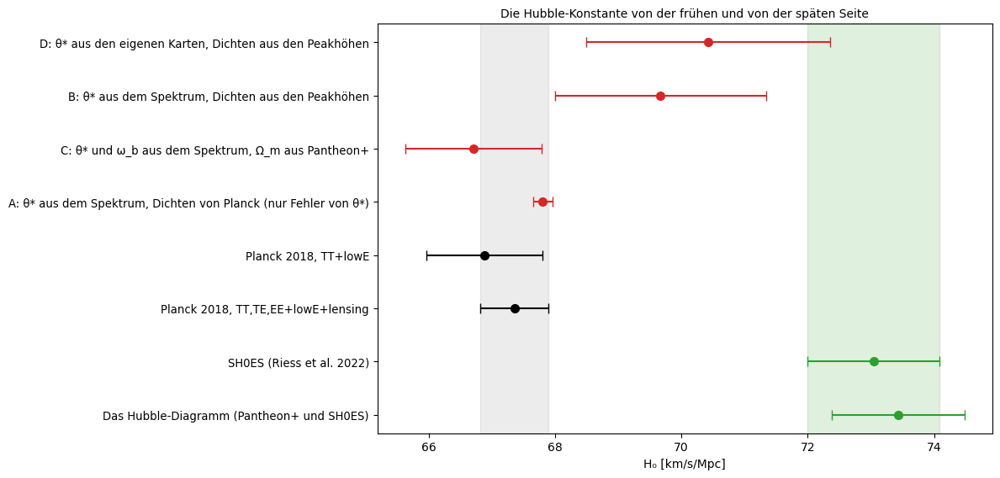

Größe         eigen                          Planck 2018 (TT,TE,EE+lowE+lensing)
100 θ*        1.04116 ± 0.00045 (Schablone)     1.0411 ± 0.00031  (TT+lowE 1.04097 ± 0.00046)
              1.0434 ± 0.0029 (eigene Karten)
              1.0458 ± 0.0038 (Abstand der Peaks)
z*            1091.9 (Näherung)                   1089.92 ± 0.25
r_s [Mpc]     144.26 (mit Planck-Dichten)        144.43 ± 0.26
ω_b           0.02294 ± 0.00069                0.02237 ± 0.00015
ω_m           0.1397 ± 0.0032                  0.143 ± 0.0011
D: H₀ = 70.43 ± 1.93: gegen SH0ES 1.2 σ, gegen Planck +1.5 σ
B: H₀ = 69.67 ± 1.67: gegen SH0ES 1.7 σ, gegen Planck +1.3 σ
C: H₀ = 66.71 ± 1.08: gegen SH0ES 4.2 σ, gegen Planck -0.5 σ


In [85]:
cmbpeaks.literature()

**85. Was müsste sich ändern, damit 73 herauskommt?**

Bei gemessenem θ⋆ verlangt H₀ = 73 einen kleineren Schallhorizont oder eine andere Materiedichte; dazu der Einfluss zusätzlicher Neutrinoarten.

Mit ΛCDM passt 73 nur bei Ω_m = 0.24, 5σ unter Pantheon+. Mit der Materiedichte von Planck müsste der Schallhorizont um 1.5 % schrumpfen. Jede zusätzliche Neutrinoart hebt H₀ bei festen Dichten um etwa 11; für 73 genügte N_eff ≈ 3.5, was die Peakhöhen allerdings verändern würde. Eine Lösung müsste also das frühe Universum ändern.

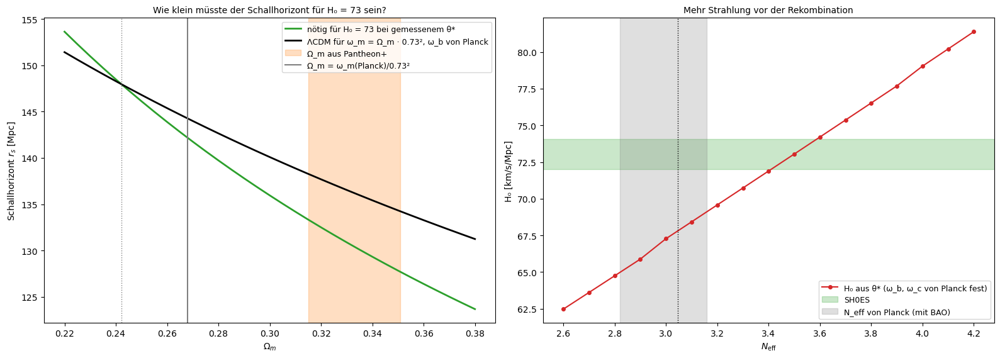

H₀ = 73 passt in ΛCDM zu θ* bei Ω_m = 0.242 (ω_m = 0.1292; Planck 0.143)
bei Ω_m = 0.333 aus Pantheon+: r_s nötig 130.4 Mpc, ΛCDM gibt 136.2 Mpc (-4.3 %)
Ω_m = 0.242 liegt 5.0 σ unter Pantheon+
mit ω_m von Planck: Ω_m = 0.268 (3.6 σ unter Pantheon+), r_s nötig 142.2 statt 144.3 Mpc (-1.5 %)
Ω_m = 0.333 und H₀ = 73 verlangen ω_m = 0.1777, 24 % mehr als Planck aus den Peakhöhen
N_eff für H₀ = 73: 3.50, also 3.0 σ über dem Wert von Planck; r_s dann 142.1 Mpc


In [86]:
cmbpeaks.what_if_73()

**86. Die Nukleosynthese im Urknall**

In der ersten Sekunde war das Universum heißer als 10 Milliarden Kelvin; Protonen und Neutronen wandelten sich ständig ineinander um, und jedes Deuteron zerbrach sofort an einem Photon. Erst nach etwa drei Minuten überlebte Deuterium, und in wenigen Minuten ging fast jedes Neutron in Helium-4 über; übrig blieben Spuren von Deuterium, Helium-3 und Lithium-7. Hier läuft ein eigenes Reaktionsnetz mit zwölf Reaktionen. Geladen werden die Kernreaktionsraten in zwei Kompilationen (PRIMAT und NACRE II) und Ergebnisse des vollständigen Codes PRyMordial zum Vergleich.

Die beiden Kompilationen unterscheiden sich bei T = 0.8·10⁹ K kaum, außer bei d(d,n)³He: NACRE II ist dort 4 % kleiner. Der Hintergrund (Temperatur gegen Zeit) braucht 2 s, ein Lauf des Netzwerks unter einer halben Sekunde.

In [87]:
bbn.load()

12 Reaktionen in zwei Kompilationen, T₉ = 0.001 bis 10; Ergebnistabelle von PRyMordial: 1300 Zeilen (ω_b 0.005 bis 0.040, ΔN_eff -3 bis 7)
Reaktion          PRIMAT    NACRE II Verhältnis  Fehlerfaktor PRIMAT   (bei T₉ = 0.8)
n(p,γ)d        2.697e+04   2.697e+04     1.0000               1.0044
d(p,γ)³He          263.1       262.7     0.9985               1.0220
d(d,n)³He      1.095e+07   1.047e+07     0.9563               1.0110
d(d,p)t        9.455e+06    9.31e+06     0.9846               1.0110
t(p,γ)⁴He           1849        1849     1.0000               1.2000
t(d,n)⁴He      5.207e+08   5.176e+08     0.9941               1.0030
t(α,γ)⁷Li          118.4       122.6     1.0354               1.0431
³He(n,p)t       4.87e+08   4.948e+08     1.0160               1.0144
³He(d,p)⁴He    6.382e+07       6e+07     0.9401               1.0120
³He(α,γ)⁷Be        5.375       5.167     0.9614               1.0240
⁷Be(n,p)⁷Li    1.707e+09   1.761e+09     1.0318               1.0204
⁷Li(p,α)⁴He    1

Hintergrund 2.1 s, ein Lauf 0.46 s; η₁₀ = 273.76 ω_b
Reaktion      Q [MeV]           α    β         γ   (Rückreaktion aus dem detaillierten Gleichgewicht)
n(p,γ)d         2.225   4.716e+09  1.5   -25.815
d(p,γ)³He       5.493   1.634e+10  1.5   -63.749
d(d,n)³He       3.269       1.732  0.0   -37.933
d(d,p)t         4.033       1.735  0.0   -46.797
t(p,γ)⁴He      19.814   2.611e+10  1.5  -229.930
t(d,n)⁴He      17.589       5.535  0.0  -204.115
t(α,γ)⁷Li       2.467   1.113e+10  1.5   -28.633
³He(n,p)t       0.764       1.002  0.0    -8.864
³He(d,p)⁴He    18.353       5.545  0.0  -212.978
³He(α,γ)⁷Be     1.587   1.113e+10  1.5   -18.415
⁷Be(n,p)⁷Li     1.644       1.002  0.0   -19.082
⁷Li(p,α)⁴He    17.346        4.69  0.0  -201.296


**87. Temperatur und Zeit in den ersten Minuten**

Die Temperatur der Photonen und der Neutrinos über der Zeit. Wenn Elektronen und Positronen zerstrahlen, heizen sie die Photonen, die Neutrinos aber nicht mehr.

Bis etwa 1 s sind beide Temperaturen gleich, danach trennen sie sich. Am Ende ist das Verhältnis genau (11/4)^(1/3) = 1.401: Die Entropie der Elektronen und Positronen ist ganz bei den Photonen angekommen. Bei 0.1 MeV ist das Universum 119 s alt.

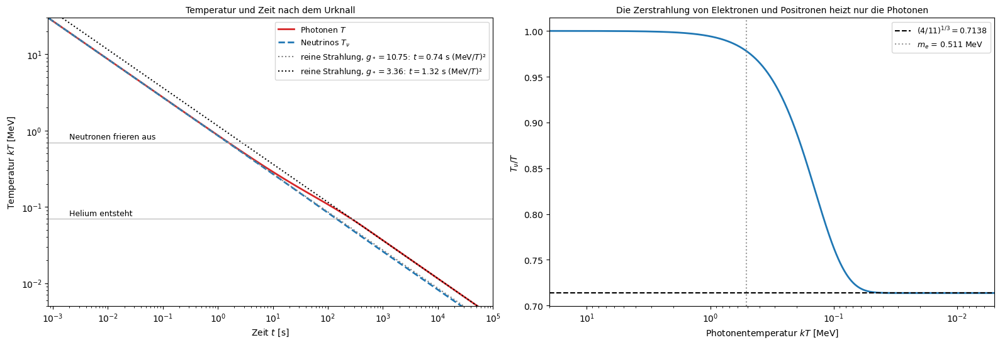

T =  1.00 MeV ( 11.60·10⁹ K): t =      0.7 s, T_ν/T = 0.9941
T =  0.50 MeV (  5.80·10⁹ K): t =      3.1 s, T_ν/T = 0.9771
T =  0.10 MeV (  1.16·10⁹ K): t =    119.2 s, T_ν/T = 0.7630
T =  0.07 MeV (  0.81·10⁹ K): t =    265.4 s, T_ν/T = 0.7253
T =  0.01 MeV (  0.12·10⁹ K): t =  13203.4 s, T_ν/T = 0.7138
am Ende T/T_ν = 1.40102, erwartet (11/4)^(1/3) = 1.40102; einfache Formel bei 0.1 MeV: 132 s


In [88]:
bbn.temperature_time()

**88. Neutronen und Protonen**

Schwache Reaktionen wandeln Neutronen und Protonen ineinander um, solange sie schneller sind als die Expansion. Gezeigt sind die Raten, die Expansionsrate H und der Anteil der Neutronen.

Bei 0.66 MeV (1.7 s) werden die Raten langsamer als H, die Neutronen frieren aus, bei einem Anteil von 0.21 statt 0.13 im Gleichgewicht. Danach sinkt der Anteil weiter, schneller als durch den Zerfall allein, weil die schwachen Reaktionen noch eine Weile nachwirken. Fast alle übrigen Neutronen enden in Helium-4.

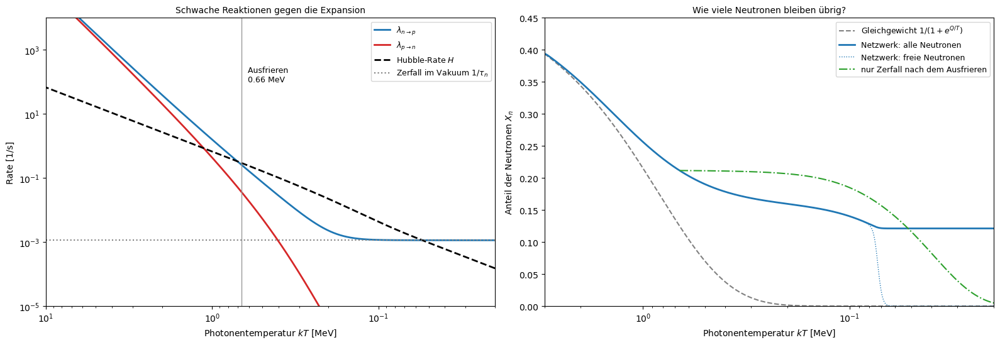

Ausfrieren (λ_np + λ_pn = H): T = 0.664 MeV, t = 1.71 s; X_n = 0.2116, im Gleichgewicht wären es 0.1248
T = 1.000 MeV: t =    0.7 s, X_n = 0.2563
T = 0.300 MeV: t =    9.1 s, X_n = 0.1686
T = 0.100 MeV: t =  119.2 s, X_n = 0.1404
T = 0.072 MeV: t =  246.8 s, X_n = 0.1225
Zerfall allein vom Ausfrieren bis zur Hälfte des Heliums: X_n = 0.1601; 2 X_n = 0.2449, Y_p (Born) = 0.2425


In [89]:
bbn.neutrons_protons()

**89. Der Engpass beim Deuterium**

Deuterium ist schwach gebunden; solange es viel mehr Photonen als Baryonen gibt (etwa 10⁹ zu 1), zerbricht es sofort. Gezeigt sind das Gleichgewicht nach Saha für drei Baryonendichten und das Netzwerk.

Erst unter 0.08 MeV überlebt Deuterium; sein Maximum (0.6 % der Masse) liegt bei 246 s, genau wenn die Hälfte des Heliums entstanden ist. Der Engpass hängt nur logarithmisch an der Baryonendichte.

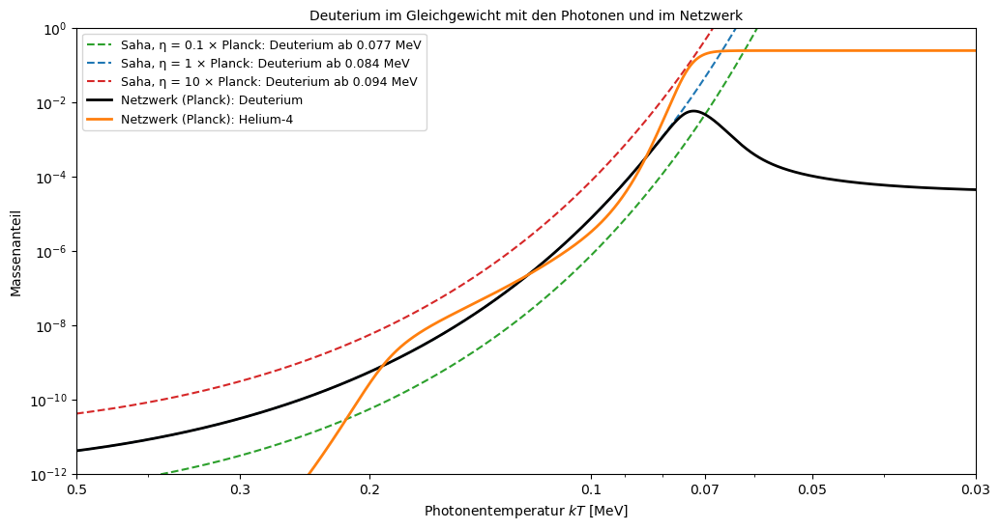

Netzwerk: Deuterium am häufigsten bei T = 0.0725 MeV (t = 246 s), Massenanteil 5.74e-03; die Hälfte des Heliums steht bei T = 0.0724 MeV (t = 247 s)
B_d/T dort: 30.7; ln(1/η) = 21.2
η =  0.1 × Planck: Saha-Deuterium erreicht 10⁻³ der Neutronen bei T = 0.0769 MeV (t = 217 s)
η =    1 × Planck: Saha-Deuterium erreicht 10⁻³ der Neutronen bei T = 0.0845 MeV (t = 176 s)
η =   10 × Planck: Saha-Deuterium erreicht 10⁻³ der Neutronen bei T = 0.0937 MeV (t = 139 s)


In [90]:
bbn.deuterium_bottleneck()

**90. Das Netzwerk: die ersten zwanzig Minuten**

Die Massenanteile der acht Kerne über der Zeit.

Bis etwa 200 s ändern sich nur Neutronen und Protonen; zwischen 200 und 300 s läuft fast alles ab, Helium-4 springt auf 0.24. Mit allen Korrekturen ergeben sich bei der Baryonendichte von Planck Y_p = 0.2469, D/H = 2.45·10⁻⁵, ³He/H = 1.04·10⁻⁵ und ⁷Li/H = 5.5·10⁻¹⁰; Lithium entsteht zu 95 % als Beryllium-7.

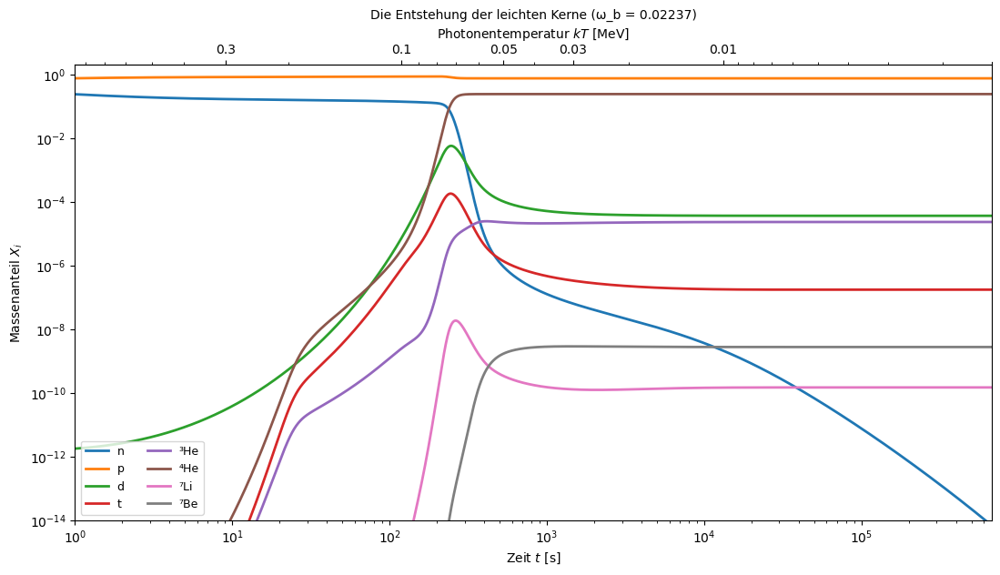

d   : höchster Massenanteil 5.74e-03 bei t =    246 s, am Ende 3.65e-05
t   : höchster Massenanteil 1.82e-04 bei t =    244 s, am Ende 1.75e-07
³He : höchster Massenanteil 2.46e-05 bei t =    412 s, am Ende 2.33e-05
⁷Li : höchster Massenanteil 1.86e-08 bei t =    263 s, am Ende 1.49e-10
⁷Be : höchster Massenanteil 2.89e-09 bei t =   1415 s, am Ende 2.76e-09
Born:       Y_p = 0.24245, D/H = 2.4108e-05, ³He/H = 1.0350e-05, ⁷Li/H = 5.483e-10
korrigiert: Y_p = 0.24692, D/H = 2.4467e-05, ³He/H = 1.0398e-05, ⁷Li/H = 5.517e-10; ⁷Li stammt zu 95% aus ⁷Be
PRIMAT (Pitrou et al. 2021, ω_b = 0.02242, τ_n = 879.4 s): Y_p = 0.24721, D/H = 2.439e-05, ³He/H = 1.039e-05, ⁷Li/H = 5.464e-10


In [91]:
bbn.network()

**91. Prüfung gegen einen vollständigen Code**

Das eigene Netzwerk gegen PRIMAT (Pitrou et al.) und PRyMordial, mit denselben Einstellungen.

Helium stimmt auf 0.00006, Deuterium und Helium-3 auf 0.03 %, Lithium auf 1.5 %. Mit zusätzlichen Neutrinoarten weicht Helium um 0.0002 bis 0.0003 ab, weil die Korrekturen für drei Arten bestimmt sind.

        eigen Born  Pitrou 2018 Born     Abw. | eigen korr.  Pitrou 2021     Abw.
Yp         0.24262           0.24262 +0.00000 |     0.24715      0.24721 -0.00006
DH         2.43349           2.42300   +0.43% |     2.43885      2.43900   -0.01%
He3H       1.03840           1.06900   -2.86% |     1.03867      1.03900   -0.03%
Li7H       5.42547           5.63500   -3.72% |     5.54565      5.46400   +1.49%


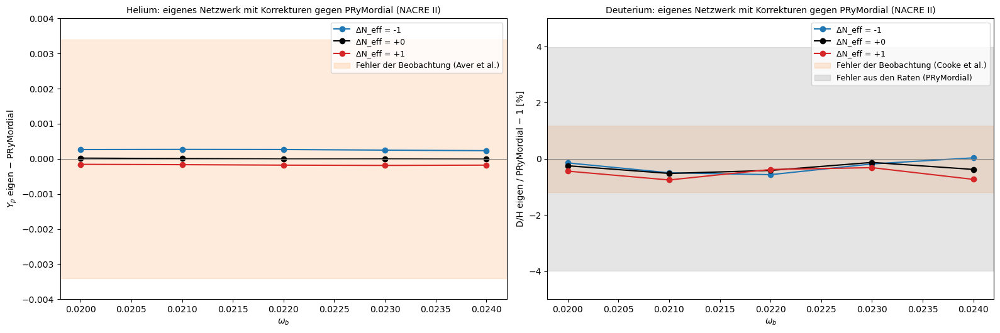

ΔN_eff = -1: Y_p +0.00023 bis +0.00027, D/H -0.56 % bis +0.04 %
ΔN_eff = +0: Y_p -0.00001 bis +0.00002, D/H -0.52 % bis -0.13 %
ΔN_eff = +1: Y_p -0.00019 bis -0.00016, D/H -0.75 % bis -0.31 %


In [92]:
bbn.code_check()

**92. Das Schramm-Diagramm**

Die vier Häufigkeiten über dem Verhältnis von Baryonen zu Photonen, η, mit den Beobachtungen und dem Wert von Planck.

Helium ändert sich über eine Größenordnung in η kaum, Deuterium fällt steil und ist deshalb das Barometer der Baryonen; es trifft die Messung bei η₁₀ = 6.0, nahe Planck (6.1). Lithium trifft das Spite-Plateau alter Sterne nur bei η₁₀ = 1.8 oder 3.4, weit weg; bei Planck liegt es 3.5-mal darüber.

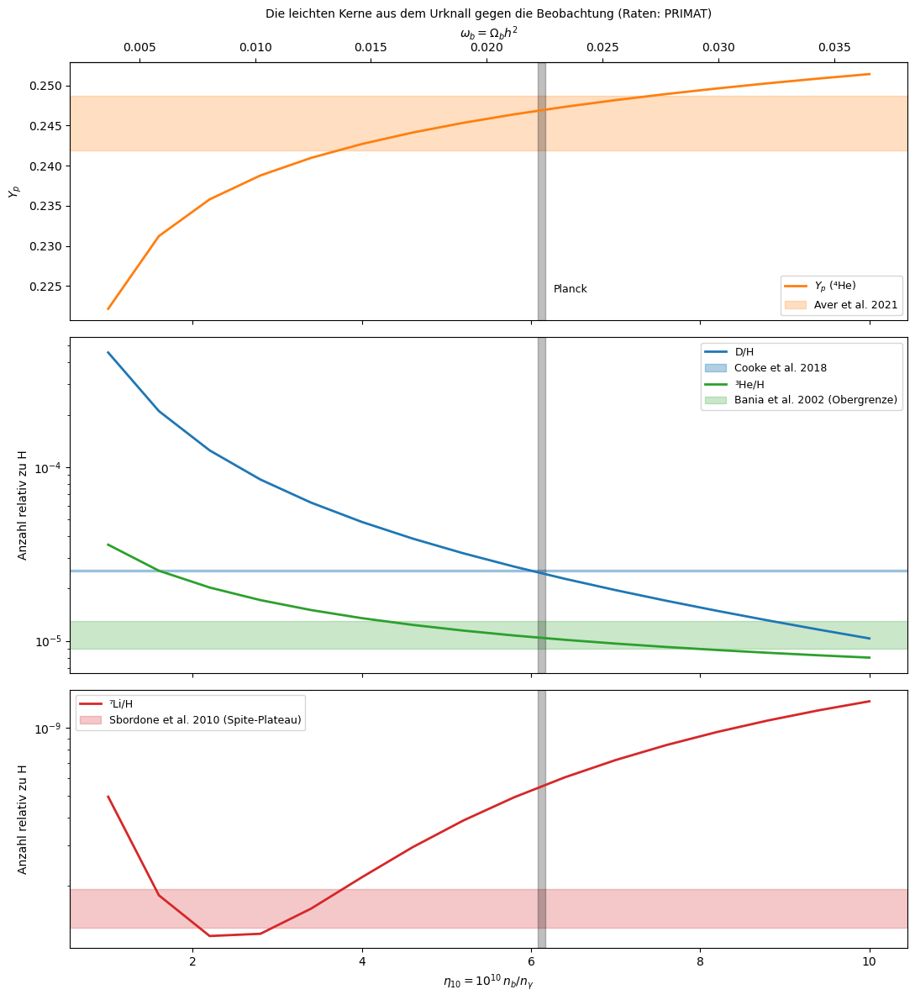

Y_p   : Beobachtung getroffen bei η₁₀ = 5.18 (ω_b = 0.0189); Spanne über η₁₀ = 1 bis 10: 0.222 bis 0.251
D/H   : Beobachtung getroffen bei η₁₀ = 6.01 (ω_b = 0.0220); Spanne über η₁₀ = 1 bis 10: 1.03e-05 bis 0.000456
³He/H : Beobachtung getroffen bei η₁₀ = 5.57 (ω_b = 0.0204); Spanne über η₁₀ = 1 bis 10: 8.01e-06 bis 3.57e-05
⁷Li/H : Beobachtung getroffen bei η₁₀ = 1.79 (ω_b = 0.0066), 3.40 (ω_b = 0.0124); Spanne über η₁₀ = 1 bis 10: 1.19e-10 bis 1.31e-09
Planck: η₁₀ = 6.124


In [93]:
bbn.schramm()

**93. Welche Reaktionen den Fehler bestimmen**

Jede der zwölf Raten wird um ihren Fehler erhöht, und die Änderung der Häufigkeiten notiert; dazu ein Monte Carlo über alle Raten.

Für Deuterium zählen d(p,γ)³He, d(d,n)³He und d(d,p)t; der Fehler aus der Kernphysik ist 1.1 %, fast so groß wie der der Messung. Beim Lithium führen ³He(α,γ)⁷Be und ⁷Be(n,p)⁷Li (3.3 %), bei Helium fast nur die Lebensdauer des Neutrons.

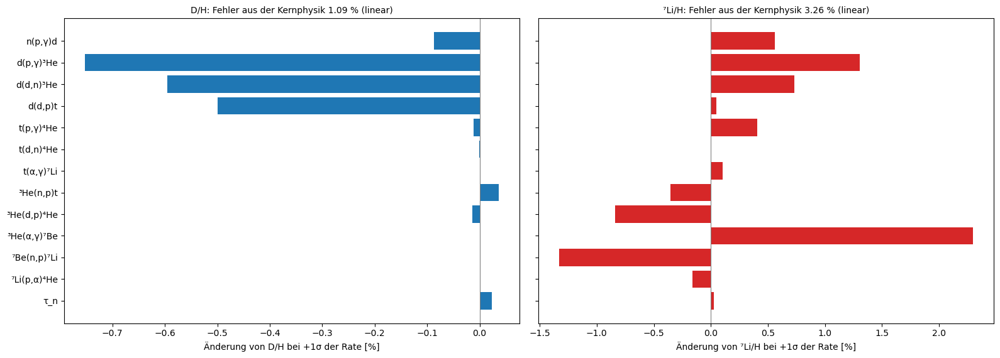

d(p,γ)³He   : D/H -0.75 % (1σ), Empfindlichkeit -0.358
d(d,n)³He   : D/H -0.60 % (1σ), Empfindlichkeit -0.549
d(d,p)t     : D/H -0.50 % (1σ), Empfindlichkeit -0.462
n(p,γ)d     : D/H -0.09 % (1σ), Empfindlichkeit -0.193
³He(n,p)t   : D/H +0.04 % (1σ), Empfindlichkeit +0.025
Fehler aus der Kernphysik, linear: D/H 1.09 %, ³He/H 1.25 %, ⁷Li/H 3.26 %, Y_p 0.00010 (davon τ_n 0.00010)
Monte Carlo (60): D/H 1.07 %, ⁷Li/H 3.19 %, Y_p 0.00008


In [94]:
bbn.reaction_errors()

**94. Die Baryonendichte aus Deuterium**

D/H auf einem feinen Gitter der Baryonendichte ω_b; gesucht ist der Wert, der die Messung trifft.

ω_b = 0.02193 ± 0.00021, 1.7σ unter Planck (0.02237); Pitrou et al. finden dasselbe. Umgekehrt sagt das Netzwerk bei der Dichte von Planck 2σ zu wenig Deuterium voraus.

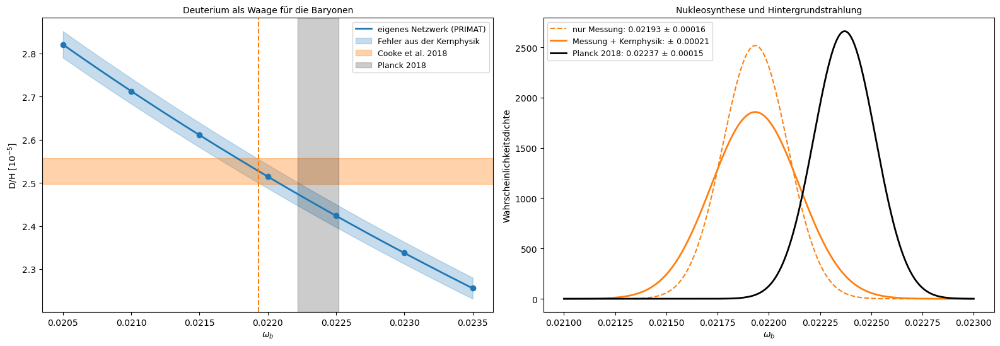

D/H ∝ ω_b^-1.643; D/H bei ω_b von Planck = 2.4467e-05 (+2.0σ gegen Cooke et al.)
ω_b aus D/H = 0.02193 ± 0.00016 (Messung) ± 0.00015 (Kernphysik) = 0.02193 ± 0.00021; η₁₀ = 6.004
gegen Planck: -1.7σ


In [95]:
bbn.baryon_density()

**95. Zwei Sätze von Raten**

Die Raten der Reaktionen, die Deuterium bilden oder verbrennen, in PRIMAT und NACRE II, und die Baryonendichte mit jeder Variante.

Mit NACRE II wird ω_b = 0.02224, nur 0.5σ unter Planck. Fast der ganze Unterschied kommt von d(d,n)³He, das in NACRE II 4 % kleiner ist, fast das Vierfache des angegebenen Fehlers. Ob es eine Spannung gibt, hängt also an einer einzigen umstrittenen Rate.

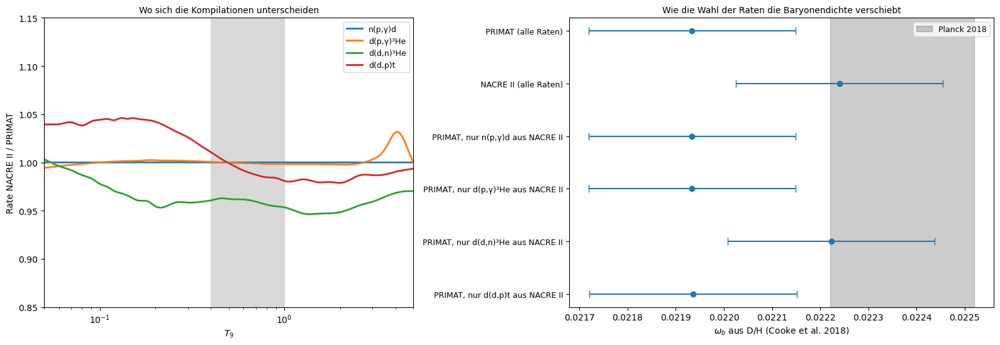

n(p,γ)d     : NACRE II / PRIMAT im Fenster T₉ = 0.4–1.0: 1.0000
d(p,γ)³He   : NACRE II / PRIMAT im Fenster T₉ = 0.4–1.0: 0.9993
d(d,n)³He   : NACRE II / PRIMAT im Fenster T₉ = 0.4–1.0: 0.9594
d(d,p)t     : NACRE II / PRIMAT im Fenster T₉ = 0.4–1.0: 0.9923
PRIMAT (alle Raten)                   : ω_b = 0.02193 (-1.7σ gegen Planck)
NACRE II (alle Raten)                 : ω_b = 0.02224 (-0.5σ gegen Planck)
PRIMAT, nur n(p,γ)d aus NACRE II      : ω_b = 0.02193 (-1.7σ gegen Planck)
PRIMAT, nur d(p,γ)³He aus NACRE II    : ω_b = 0.02193 (-1.7σ gegen Planck)
PRIMAT, nur d(d,n)³He aus NACRE II    : ω_b = 0.02222 (-0.6σ gegen Planck)
PRIMAT, nur d(d,p)t aus NACRE II      : ω_b = 0.02194 (-1.7σ gegen Planck)


In [96]:
bbn.rate_sets()

**96. Helium und die Zahl der Neutrinoarten**

Mehr Neutrinoarten lassen das Universum schneller expandieren, die Neutronen frieren früher aus, und es entsteht mehr Helium. Helium und Deuterium zusammen bestimmen die Zahl der Neutrinoarten N_eff und die Baryonendichte.

Helium wächst um 0.013 pro Neutrinoart. Zusammen folgt N_eff = 2.96 ± 0.24, passend zu Planck und zu drei Arten; eine vierte ist ausgeschlossen. Die Unsicherheit der Neutronenlebensdauer (Speicher gegen Strahl) verschiebt Helium um 0.6 Messfehler.

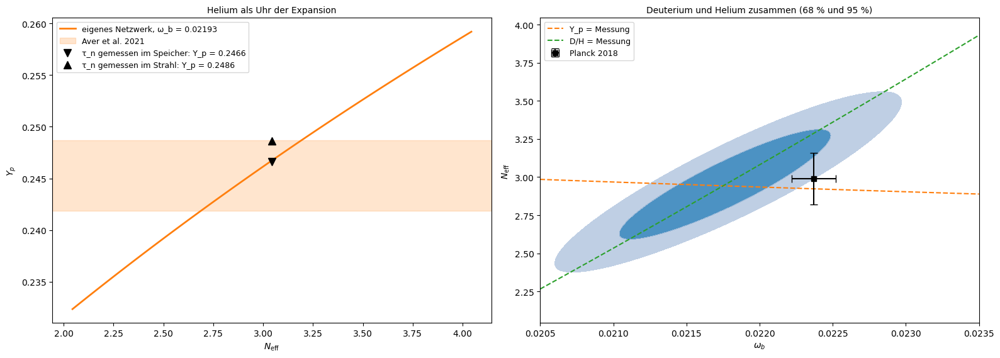

bei ω_b = 0.022: dY_p/dN_eff = 0.0134, d ln(D/H)/dN_eff = 0.136
τ_n: Speicher 877.75 s → Y_p = 0.24660, Strahl 887.7 s → Y_p = 0.24862, Unterschied 0.00202
D/H + Y_p: N_eff = 2.96 ± 0.24, ω_b = 0.02178 ± 0.00047; χ²_min = 0.00; gegen Planck (N_eff 2.99 ± 0.17): -0.1σ


In [97]:
bbn.helium_neutrinos()

**97. Das Lithiumproblem**

Lithium-7 über der Baryonendichte mit dem Spite-Plateau, und wie stark die beiden wichtigsten Raten sich ändern müssten, damit es passt.

Bei der Dichte aus Deuterium sagt das Netzwerk 3.35-mal so viel Lithium voraus wie gemessen, 6σ. Dafür müsste ³He(α,γ)⁷Be auf ein Viertel sinken oder ⁷Be(n,p)⁷Li auf das Vierfache steigen; beide sind auf 2 % gemessen. Die Kernphysik löst das Problem nicht; vermutlich haben die alten Sterne Lithium zerstört.

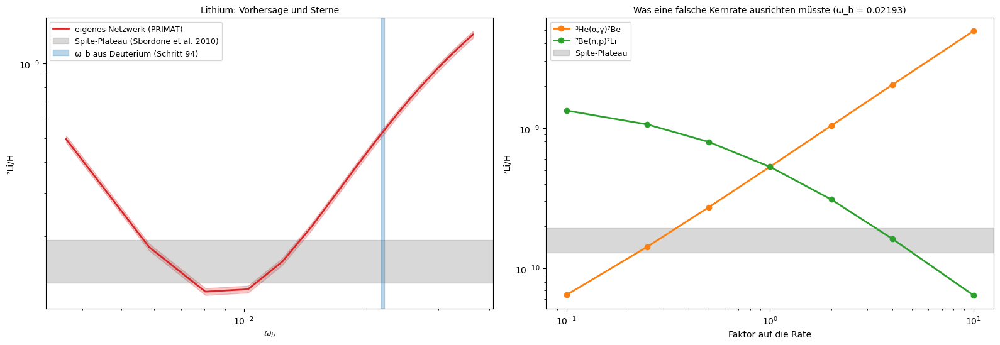

⁷Li/H bei ω_b aus D/H: 5.296e-10 ± 3.3 % (Kernphysik); Spite-Plateau 1.58e-10: Faktor 3.35, 6.0σ
³He(α,γ)⁷Be : ⁷Li/H ∝ Rate^+0.95; nötiger Faktor 0.28, gemessener Fehlerfaktor bei T₉ = 0.5: 1.024
⁷Be(n,p)⁷Li : ⁷Li/H ∝ Rate^-0.66; nötiger Faktor 4.10, gemessener Fehlerfaktor bei T₉ = 0.5: 1.020


In [98]:
bbn.lithium()

**98. Gegen die veröffentlichten Werte**

Alle Werte der Baryonendichte mit Fehlern: eigene, veröffentlichte und Planck.

Die eigenen Werte liegen dort, wo die veröffentlichten mit denselben Raten liegen: mit PRIMAT 1.7σ unter Planck, mit NACRE II 0.5σ. Die Nukleosynthese nach drei Minuten und die Hintergrundstrahlung nach 380 000 Jahren messen fast dieselbe Menge gewöhnlicher Materie, ein starker Test des Standardmodells.

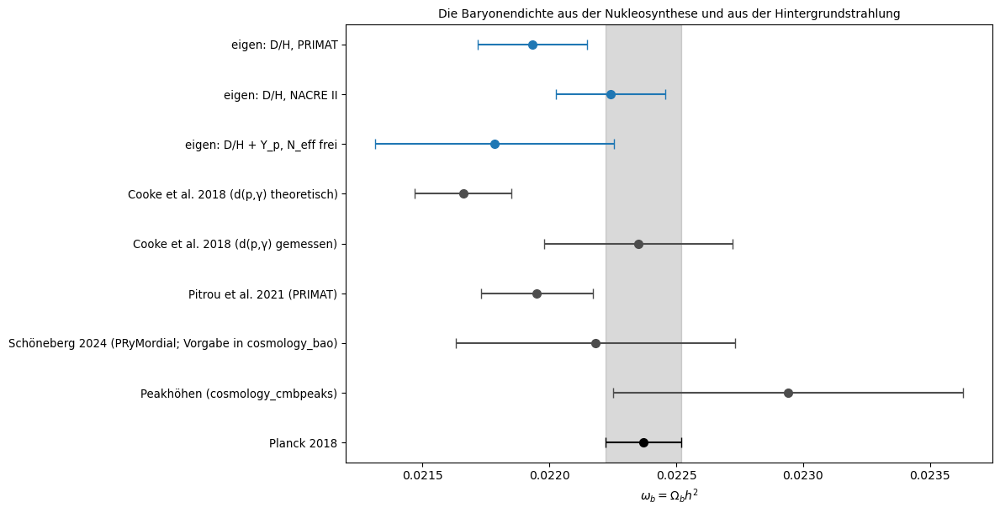

eigen: D/H, PRIMAT                                     : ω_b = 0.02193 ± 0.00021; gegen Planck -1.7σ
eigen: D/H, NACRE II                                   : ω_b = 0.02224 ± 0.00021; gegen Planck -0.5σ
eigen: D/H + Y_p, N_eff frei                           : ω_b = 0.02178 ± 0.00047; gegen Planck -1.2σ
Cooke et al. 2018 (d(p,γ) theoretisch)                 : ω_b = 0.02166 ± 0.00019; gegen Planck -2.9σ
Cooke et al. 2018 (d(p,γ) gemessen)                    : ω_b = 0.02235 ± 0.00037; gegen Planck -0.1σ
Pitrou et al. 2021 (PRIMAT)                            : ω_b = 0.02195 ± 0.00022; gegen Planck -1.6σ
Schöneberg 2024 (PRyMordial; Vorgabe in cosmology_bao) : ω_b = 0.02218 ± 0.00055; gegen Planck -0.3σ
Peakhöhen (cosmology_cmbpeaks)                         : ω_b = 0.02294 ± 0.00069; gegen Planck +0.8σ
H₀ aus BAO + BBN mit dem eigenen ω_b statt 0.02218: etwa 68.33 statt 68.53 km/s/Mpc


In [99]:
bbn.literature()